# An Adaptive Cost-Aware Semantic Routing Gateway for Multi-LLM Systems.


## 1. Environment Setup
Install and import every library used in the pipeline.

In [1]:
# ---------------------------------------------------------------
# 1.1 Install required libraries (safe to re-run; quiet install)
# ---------------------------------------------------------------
!pip install -q numpy pandas matplotlib scikit-learn seaborn xgboost lightgbm catboost joblib shap imbalanced-learn
print("All required libraries installed successfully.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.4 MB/s eta 0:00:00
All required libraries installed successfully.


In [2]:
# ---------------------------------------------------------------
# 1.2 Imports
# ---------------------------------------------------------------
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
)
from sklearn.preprocessing import label_binarize

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import joblib
import shap

# ---------------------------------------------------------------
# 1.3 Global configuration
# ---------------------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

OUTPUT_DIR = "/content/thesis_outputs"
FIGURES_DIR = os.path.join(OUTPUT_DIR, "figures")
MODELS_DIR = os.path.join(OUTPUT_DIR, "models")
TABLES_DIR = os.path.join(OUTPUT_DIR, "tables")

for directory in [OUTPUT_DIR, FIGURES_DIR, MODELS_DIR, TABLES_DIR]:
    os.makedirs(directory, exist_ok=True)

# ---------------------------------------------------------------
# 1.4 Publication-quality plotting style (IEEE-friendly, 300 DPI)
# ---------------------------------------------------------------
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.figsize": (8, 5),
})

def save_figure(fig, name):
    '''Save a matplotlib figure at publication quality (300 DPI PNG).'''
    path = os.path.join(FIGURES_DIR, f"{name}.png")
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved figure: {path}")

print("Environment ready.")
print(f"Outputs will be written to: {OUTPUT_DIR}")


Environment ready.
Outputs will be written to: /content/thesis_outputs


## 2. Load Dataset
Upload the CSV file using the Colab upload widget. The notebook auto-detects the required columns.

In [3]:
# ---------------------------------------------------------------
# 2.1 Upload dataset via Colab widget
# ---------------------------------------------------------------
from google.colab import files

print("Please select and upload your dataset CSV file.")
uploaded = files.upload()

# Take the first uploaded file, regardless of its exact name
uploaded_filename = list(uploaded.keys())[0]
print(f"Uploaded file: {uploaded_filename}")

df_raw = pd.read_csv(uploaded_filename)
print("Dataset loaded successfully.")


Please select and upload your dataset CSV file.


Saving llm_routing_dataset.csv to llm_routing_dataset.csv
Uploaded file: llm_routing_dataset.csv
Dataset loaded successfully.


In [4]:
REQUIRED_COLUMNS = [
    "query_id", "query", "category", "domain", "complexity",
    "token_count", "budget_priority", "latency_priority", "recommended_model",
]

missing_required = [c for c in REQUIRED_COLUMNS if c not in df_raw.columns]
if missing_required:
    raise ValueError(
        f"The uploaded dataset is missing required column(s): {missing_required}. "
        f"Found columns: {list(df_raw.columns)}"
    )
else:
    print("All required columns detected:")
    for c in REQUIRED_COLUMNS:
        print(f"  - {c}")

All required columns detected:
  - query_id
  - query
  - category
  - domain
  - complexity
  - token_count
  - budget_priority
  - latency_priority
  - recommended_model


In [5]:
# ---------------------------------------------------------------
# 2.3 Dataset overview
# ---------------------------------------------------------------
print("=" * 70)
print("SHAPE")
print("=" * 70)
print(df_raw.shape)

print("\n" + "=" * 70)
print("HEAD")
print("=" * 70)
display(df_raw.head())

print("\n" + "=" * 70)
print("TAIL")
print("=" * 70)
display(df_raw.tail())

print("\n" + "=" * 70)
print("INFO")
print("=" * 70)
df_raw.info()

print("\n" + "=" * 70)
print("DESCRIBE (numeric)")
print("=" * 70)
display(df_raw.describe(include=[np.number]))

print("\n" + "=" * 70)
print("DESCRIBE (categorical)")
print("=" * 70)
display(df_raw.describe(include=["object"]))

print("\n" + "=" * 70)
print("MISSING VALUES PER COLUMN")
print("=" * 70)
missing_summary = df_raw.isnull().sum().to_frame("missing_count")
missing_summary["missing_percent"] = (missing_summary["missing_count"] / len(df_raw) * 100).round(2)
display(missing_summary)

print("\n" + "=" * 70)
print("DUPLICATE ROWS")
print("=" * 70)
print(f"Total duplicate rows: {df_raw.duplicated().sum()}")


SHAPE
(30000, 37)

HEAD


,query_id,query,category,domain,complexity,reasoning_level,token_count,context_length,requires_code,requires_math,...,gpt_latency,claude_latency,gemini_latency,llama_latency,deepseek_latency,best_quality_model,lowest_cost_model,lowest_latency_model,recommended_model,routing_score
0,Q000001,Provide a tutorial for implementing an influen...,How-To Tutorial,Marketing,Medium,Medium,607,376,True,False,...,3.258,3.602,1.967,2.777,1.434,Claude,Llama,DeepSeek,Claude,4.2576
1,Q000002,Help me understand intellectual property infri...,Conceptual Question,Legal,Medium,Medium,131,334,False,False,...,2.364,3.282,1.693,1.526,1.631,Gemini,Llama,Llama,Gemini,3.8604
2,Q000003,Draft a product launch campaign with a compell...,Content Creation,Marketing,Medium,High,984,230,False,False,...,1.824,4.284,2.388,4.013,1.148,Claude,Llama,DeepSeek,Claude,4.5255
3,Q000004,Draft a study technique for exam prep with a c...,Content Creation,Education,Hard,High,621,409,False,False,...,3.501,4.600,1.919,2.724,2.178,GPT,Llama,Gemini,Claude,3.8603
4,Q000005,Can you explain the core concept behind a chro...,Conceptual Question,Medical,Medium,Low,164,250,False,False,...,2.665,1.661,0.984,3.386,1.612,Gemini,Llama,Gemini,Gemini,3.6798



TAIL


,query_id,query,category,domain,complexity,reasoning_level,token_count,context_length,requires_code,requires_math,...,gpt_latency,claude_latency,gemini_latency,llama_latency,deepseek_latency,best_quality_model,lowest_cost_model,lowest_latency_model,recommended_model,routing_score
29995,Q029996,Help me interpret the results of a data collec...,Data Analysis,Research,Medium,Medium,629,464,False,False,...,3.335,3.543,1.817,2.815,2.216,Claude,Llama,Gemini,Claude,3.8047
29996,Q029997,Explain a persuasive essay outline in a way a ...,Explanation,Writing,Medium,High,68,521,False,False,...,3.159,3.874,2.013,2.188,1.212,Claude,Llama,DeepSeek,Claude,4.7068
29997,Q029998,Provide a short summary of a multi-chapter boo...,Summarization Task,Summarization,Easy,Low,1052,153,False,False,...,3.804,3.099,1.969,4.516,2.617,Gemini,Llama,Gemini,Gemini,4.6665
29998,Q029999,What are the key findings in prior work relate...,Research Assistance,Medical,Medium,Medium,496,1021,False,False,...,3.334,2.408,1.060,3.611,2.252,Llama,Llama,Gemini,Llama,3.9513
29999,Q030000,Help me gather background research on trade ta...,Research Assistance,Economics,Easy,Medium,373,742,False,False,...,2.905,2.894,1.368,4.583,1.912,Claude,Llama,Gemini,Claude,3.9970



INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 37 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   query_id                30000 non-null  object 
 1   query                   30000 non-null  object 
 2   category                30000 non-null  object 
 3   domain                  30000 non-null  object 
 4   complexity              30000 non-null  object 
 5   reasoning_level         30000 non-null  object 
 6   token_count             30000 non-null  int64  
 7   context_length          30000 non-null  int64  
 8   requires_code           30000 non-null  bool   
 9   requires_math           30000 non-null  bool   
 10  requires_reasoning      30000 non-null  bool   
 11  requires_creativity     30000 non-null  bool   
 12  multilingual            30000 non-null  bool   
 13  urgency                 30000 non-null  object 
 14  budget_priority         30000 no

,token_count,context_length,gpt_quality_score,claude_quality_score,gemini_quality_score,llama_quality_score,deepseek_quality_score,gpt_cost,claude_cost,gemini_cost,llama_cost,deepseek_cost,gpt_latency,claude_latency,gemini_latency,llama_latency,deepseek_latency,routing_score
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,478.576767,593.252533,8.232114,7.872644,7.824556,7.871597,7.287444,0.749166,0.701536,0.460163,0.142458,0.189117,2.920507,3.238294,1.953728,3.458829,2.160566,4.186017
std,323.330751,612.100584,0.622568,0.771997,0.619920,0.462037,1.169518,0.131545,0.130837,0.098931,0.043395,0.054817,0.743688,0.836687,0.546354,1.031136,0.546394,0.237814
min,10.000000,0.000000,6.090000,5.450000,5.890000,5.890000,4.240000,0.255200,0.224900,0.051000,0.001000,0.001000,0.100000,0.100000,0.100000,0.100000,0.140000,3.367200
25%,243.000000,219.000000,7.800000,7.320000,7.400000,7.560000,6.310000,0.656000,0.610400,0.391700,0.112600,0.151900,2.413000,2.665000,1.579000,2.763000,1.784750,4.014100
50%,409.000000,390.000000,8.230000,7.810000,7.770000,7.870000,7.100000,0.746800,0.698500,0.458750,0.141900,0.188100,2.916000,3.238000,1.948000,3.462000,2.155000,4.169100
75%,647.000000,644.000000,8.650000,8.370000,8.180000,8.190000,8.320000,0.842300,0.791400,0.527200,0.171400,0.226100,3.418000,3.801250,2.316000,4.153000,2.529000,4.344400
max,2893.000000,4307.000000,10.000000,10.000000,10.000000,9.660000,10.000000,1.000000,1.000000,0.875400,0.339600,0.423600,6.328000,6.549000,4.457000,7.704000,4.902000,4.935000



DESCRIBE (categorical)


,query_id,query,category,domain,complexity,reasoning_level,urgency,budget_priority,quality_priority,latency_priority,best_quality_model,lowest_cost_model,lowest_latency_model,recommended_model
count,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000,30000
unique,30000,30000,15,25,4,4,3,3,3,3,5,3,5,5
top,Q029984,Explain a cover letter in a way a beginner cou...,Conceptual Question,Cloud Computing,Medium,Medium,Medium,Medium,Medium,Medium,GPT,Llama,Gemini,DeepSeek
freq,1,1,5412,1261,10138,9460,11472,11440,11240,11294,9399,23074,15635,6843



MISSING VALUES PER COLUMN


,missing_count,missing_percent
query_id,0,0.0
query,0,0.0
category,0,0.0
domain,0,0.0
complexity,0,0.0
reasoning_level,0,0.0
token_count,0,0.0
context_length,0,0.0
requires_code,0,0.0
requires_math,0,0.0



DUPLICATE ROWS
Total duplicate rows: 0


## 3. Data Cleaning
Handle missing values, duplicate rows, and incorrect data types.

In [6]:
# ---------------------------------------------------------------
# 3.1 Work on a clean copy
# ---------------------------------------------------------------
df = df_raw.copy()

initial_rows = len(df)

# ---------------------------------------------------------------
# 3.2 Remove duplicate rows
# ---------------------------------------------------------------
duplicates_removed = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {duplicates_removed} duplicate row(s).")

# ---------------------------------------------------------------
# 3.3 Handle missing values
# ---------------------------------------------------------------
numeric_cols = ["token_count", "budget_priority", "latency_priority"]
categorical_cols = ["category", "domain", "complexity", "recommended_model"]

# Numeric columns: impute with median (robust to outliers)
for col in numeric_cols:
    if col in df.columns and df[col].isnull().any():
        median_val = df[col].median()
        n_missing = df[col].isnull().sum()
        df[col] = df[col].fillna(median_val)
        print(f"Filled {n_missing} missing value(s) in '{col}' with median = {median_val}")

# Categorical columns: impute with mode (most frequent value)
for col in categorical_cols:
    if col in df.columns and df[col].isnull().any():
        mode_val = df[col].mode()[0]
        n_missing = df[col].isnull().sum()
        df[col] = df[col].fillna(mode_val)
        print(f"Filled {n_missing} missing value(s) in '{col}' with mode = '{mode_val}'")

# Drop rows that still contain nulls in the critical target column
df = df.dropna(subset=["recommended_model"]).reset_index(drop=True)

# ---------------------------------------------------------------
# 3.4 Fix incorrect data types
# ---------------------------------------------------------------
df["token_count"] = pd.to_numeric(df["token_count"], errors="coerce")
df["budget_priority"] = pd.to_numeric(df["budget_priority"], errors="coerce")
df["latency_priority"] = pd.to_numeric(df["latency_priority"], errors="coerce")

# Re-impute any values that became NaN after coercion
for col in numeric_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

for col in ["category", "domain", "complexity", "recommended_model"]:
    df[col] = df[col].astype(str).str.strip()

df["query"] = df["query"].astype(str)

print(f"\nRows before cleaning: {initial_rows}")
print(f"Rows after cleaning:  {len(df)}")
print("\nFinal data types:")
print(df.dtypes)

Removed 0 duplicate row(s).

Rows before cleaning: 30000
Rows after cleaning:  30000

Final data types:
query_id                   object
query                      object
category                   object
domain                     object
complexity                 object
reasoning_level            object
token_count                 int64
context_length              int64
requires_code                bool
requires_math                bool
requires_reasoning           bool
requires_creativity          bool
multilingual                 bool
urgency                    object
budget_priority           float64
quality_priority           object
latency_priority          float64
gpt_quality_score         float64
claude_quality_score      float64
gemini_quality_score      float64
llama_quality_score       float64
deepseek_quality_score    float64
gpt_cost                  float64
claude_cost               float64
gemini_cost               float64
llama_cost                float64
deepseek_cos

## 4. Exploratory Data Analysis
Publication-quality figures describing the dataset.

Saved figure: /content/thesis_outputs/figures/01_recommended_model_distribution.png


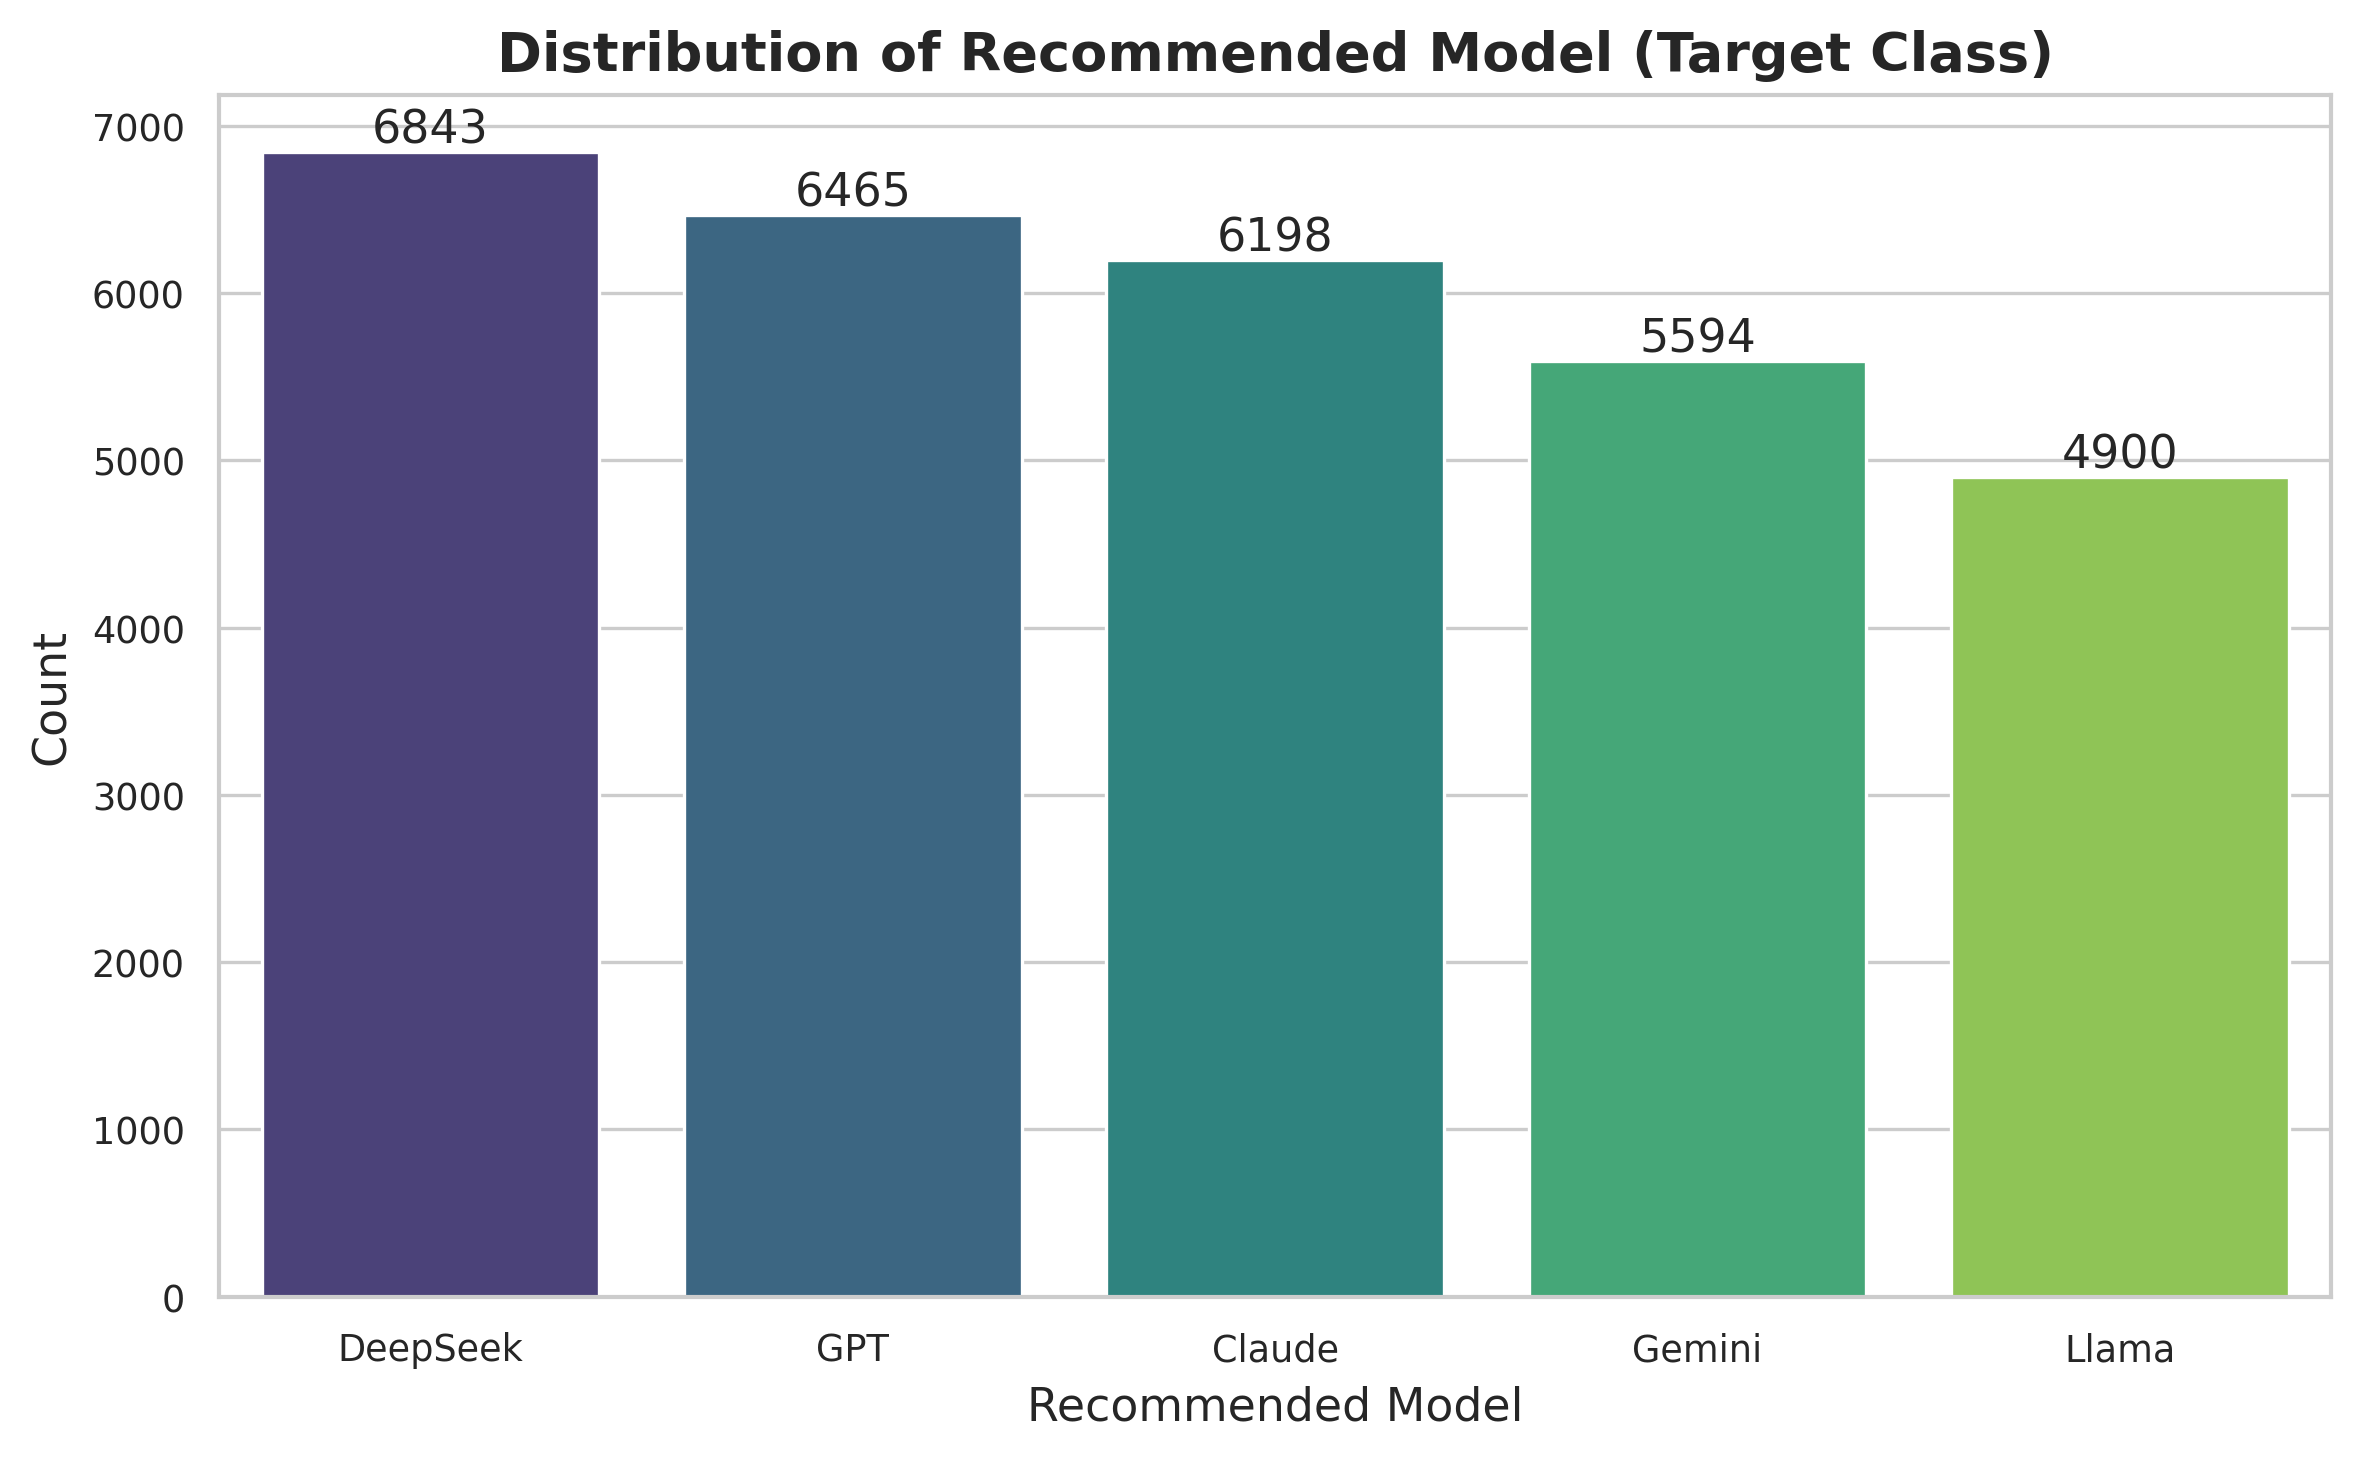

In [7]:
# ---------------------------------------------------------------
# 4.1 Preferred model distribution (the target)
# ---------------------------------------------------------------
fig, ax = plt.subplots()
order = df["recommended_model"].value_counts().index
sns.countplot(data=df, x="recommended_model", order=order, palette="viridis", ax=ax)
ax.set_title("Distribution of Recommended Model (Target Class)")
ax.set_xlabel("Recommended Model")
ax.set_ylabel("Count")
for container in ax.containers:
    ax.bar_label(container)
save_figure(fig, "01_recommended_model_distribution")
plt.show()

Saved figure: /content/thesis_outputs/figures/02_complexity_distribution.png


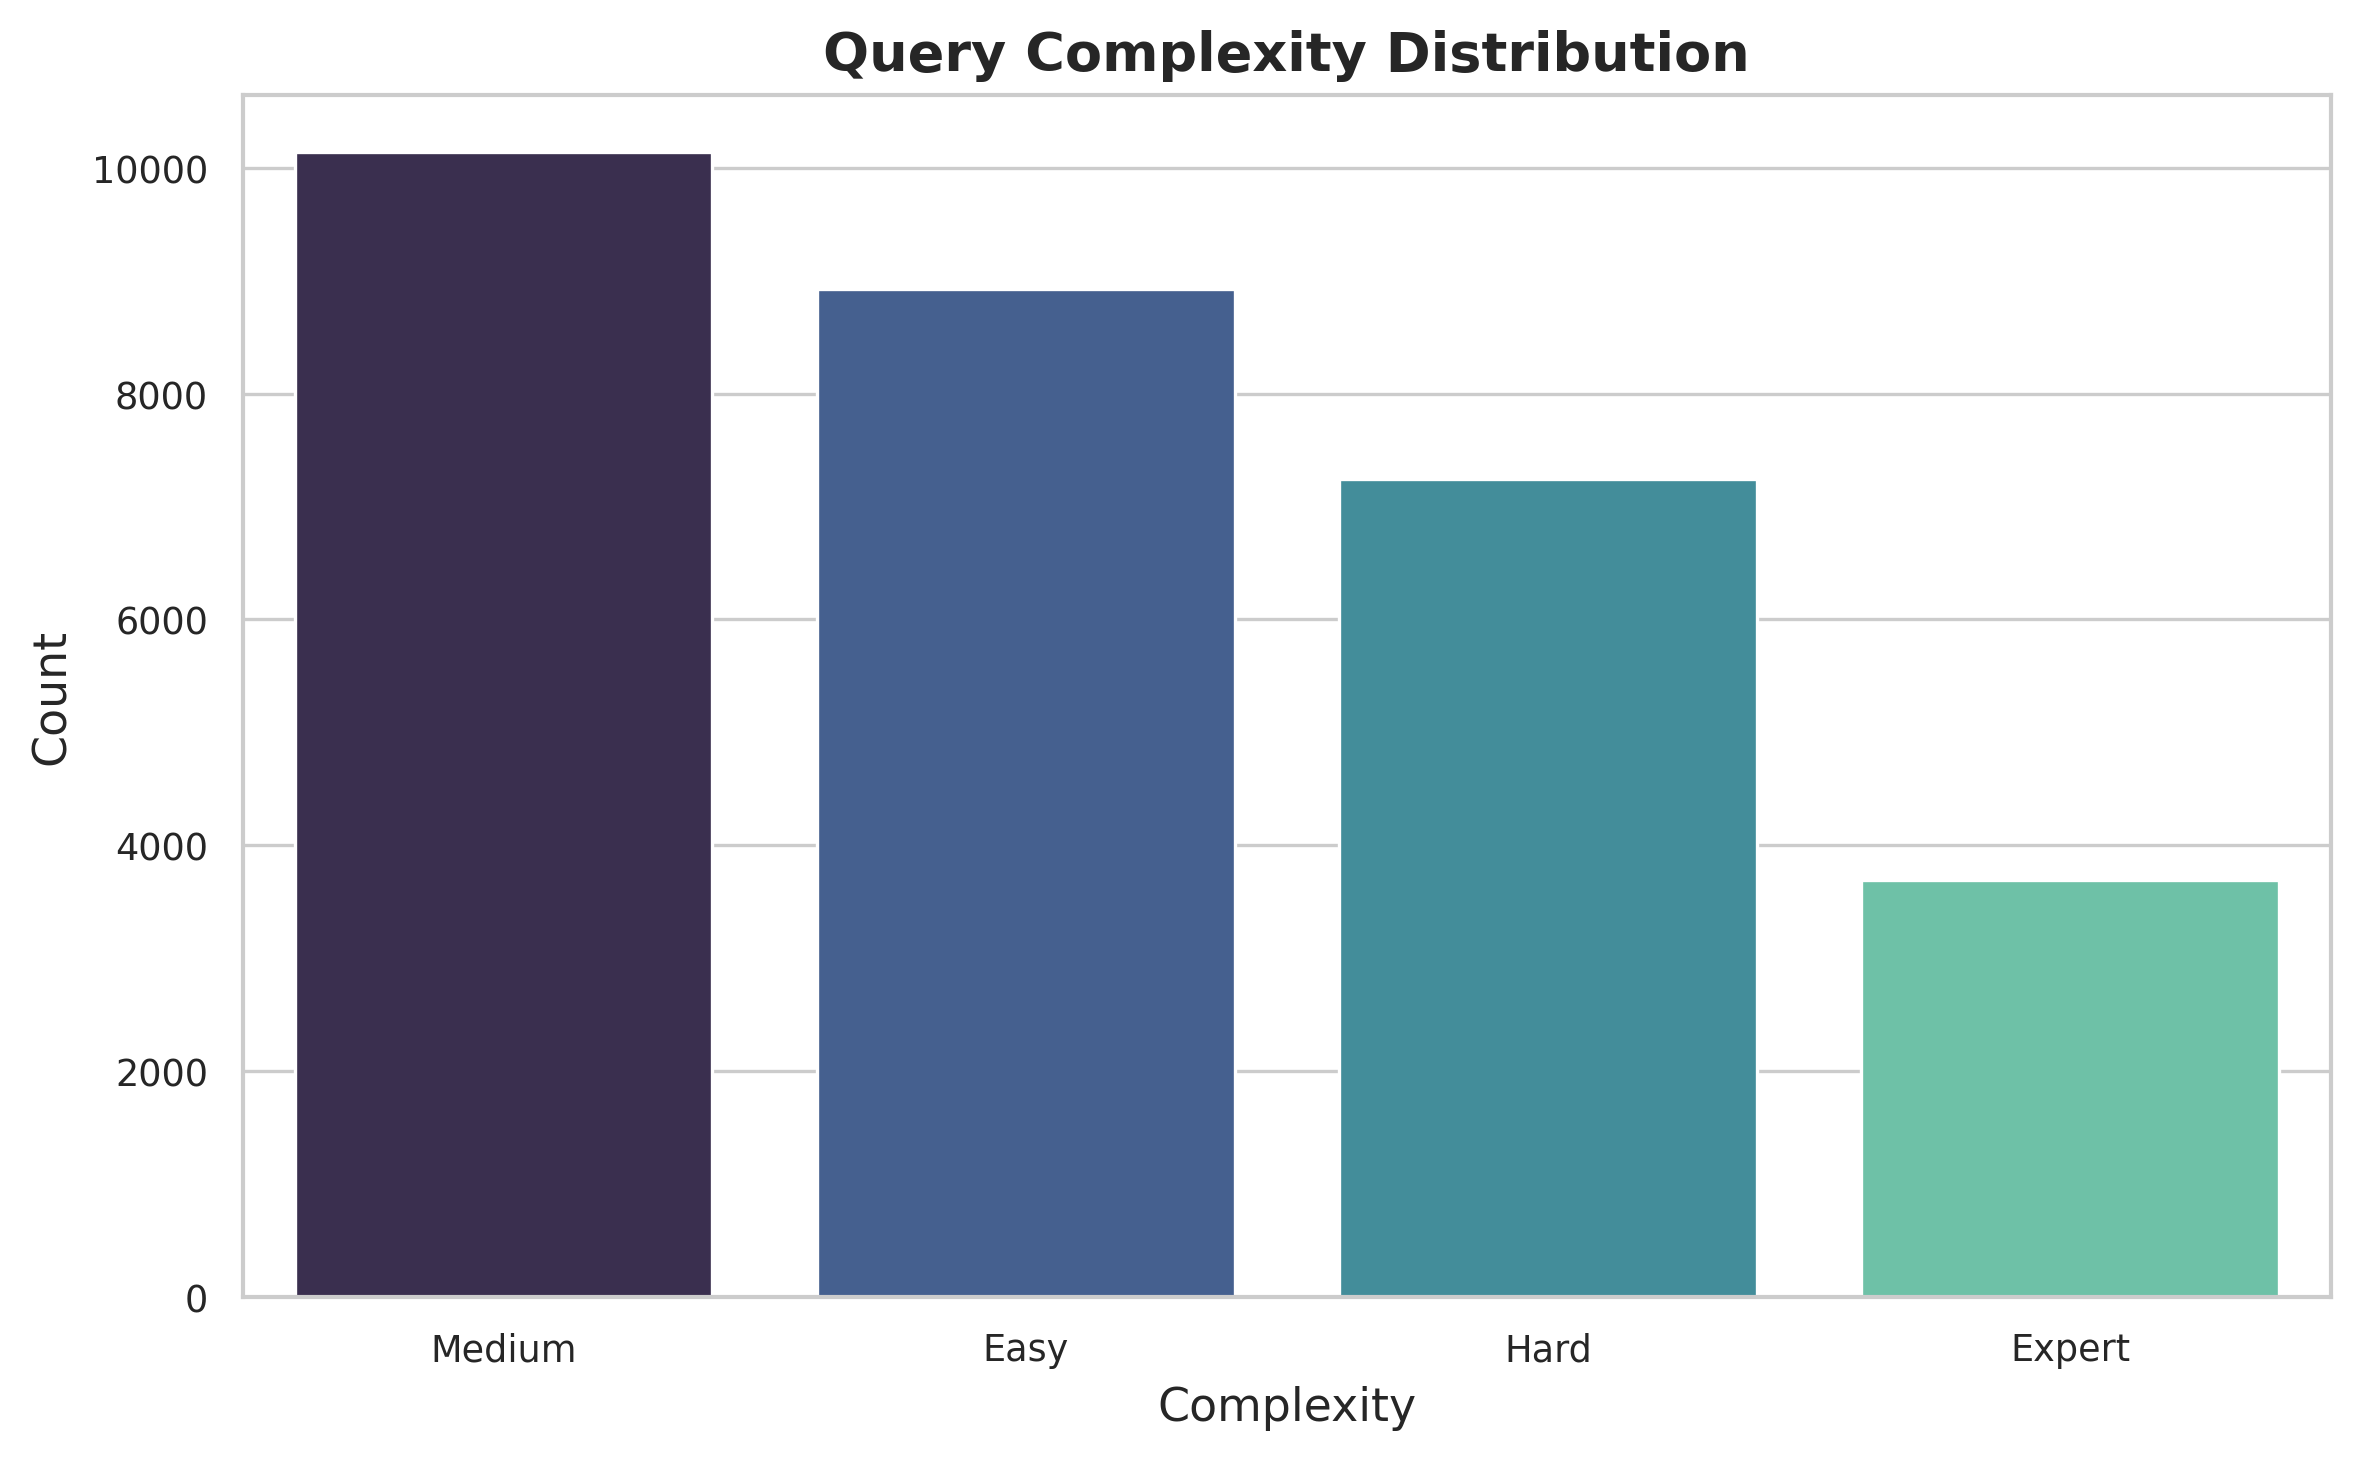

In [8]:
# ---------------------------------------------------------------
# 4.2 Complexity distribution
# ---------------------------------------------------------------
fig, ax = plt.subplots()
sns.countplot(data=df, x="complexity", order=df["complexity"].value_counts().index,
              palette="mako", ax=ax)
ax.set_title("Query Complexity Distribution")
ax.set_xlabel("Complexity")
ax.set_ylabel("Count")
save_figure(fig, "02_complexity_distribution")
plt.show()

Saved figure: /content/thesis_outputs/figures/03_category_distribution.png


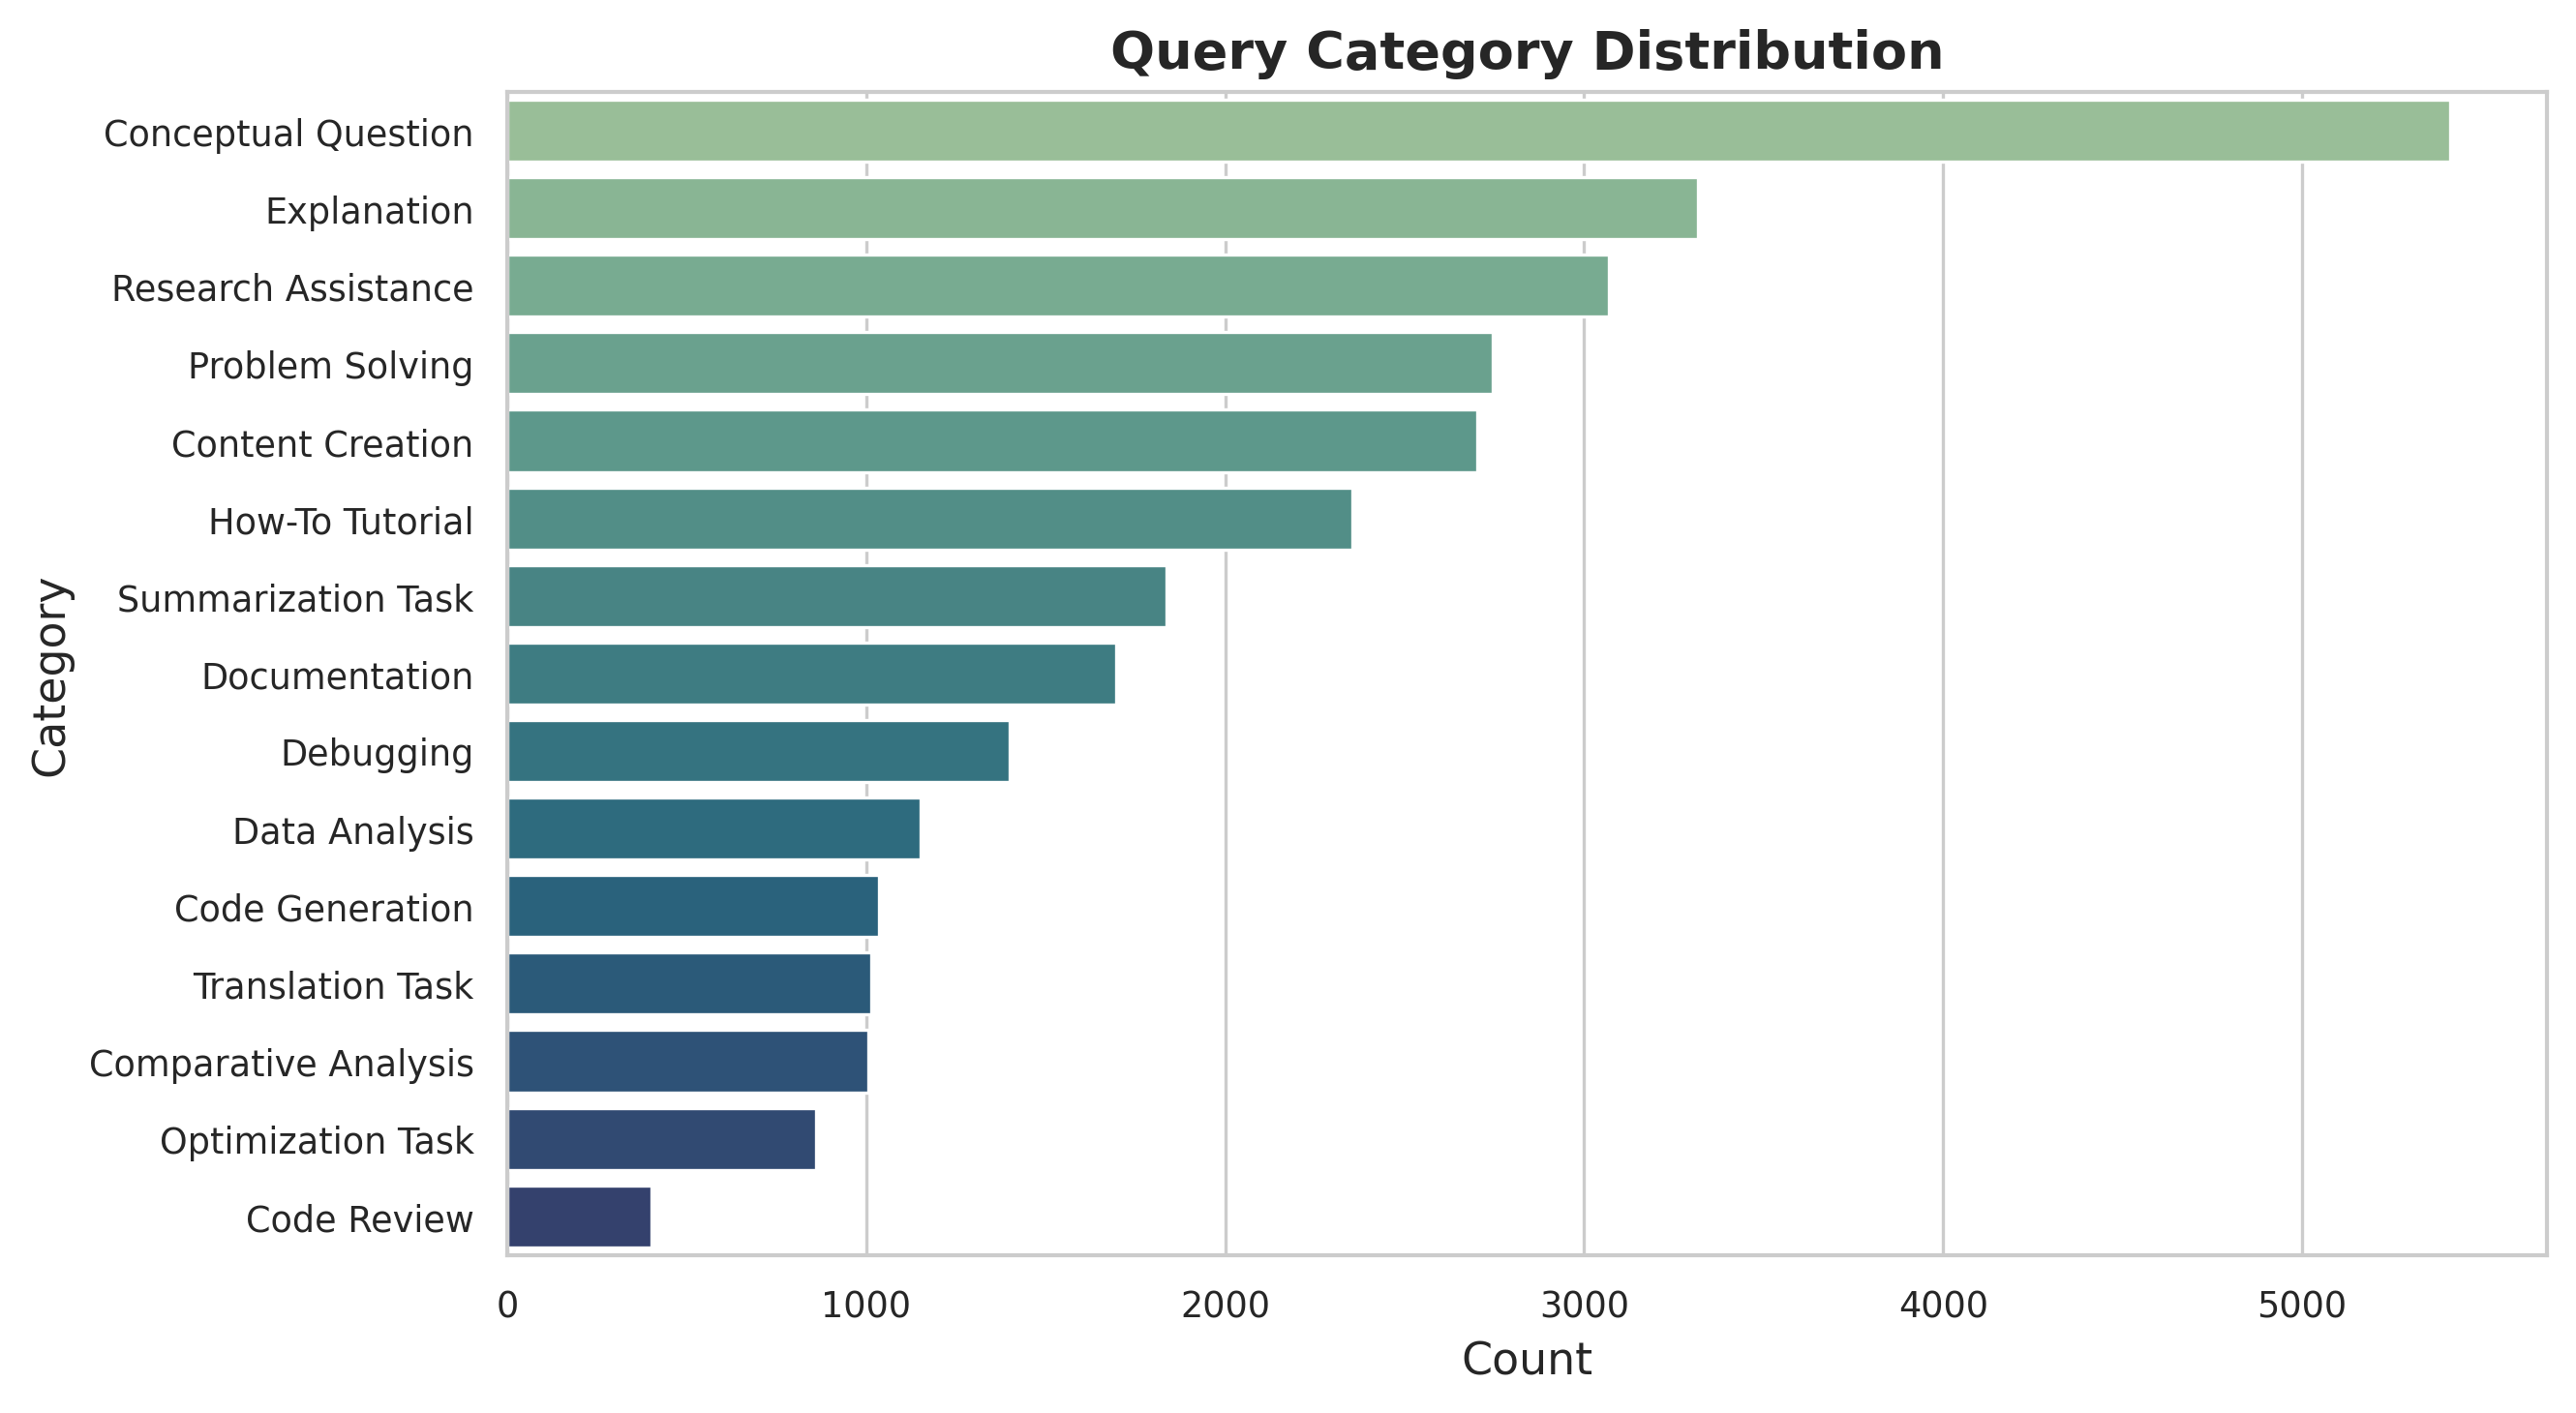

In [9]:
# ---------------------------------------------------------------
# 4.3 Category distribution
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
order = df["category"].value_counts().index
sns.countplot(data=df, y="category", order=order, palette="crest", ax=ax)
ax.set_title("Query Category Distribution")
ax.set_xlabel("Count")
ax.set_ylabel("Category")
save_figure(fig, "03_category_distribution")
plt.show()


Saved figure: /content/thesis_outputs/figures/04_domain_distribution.png


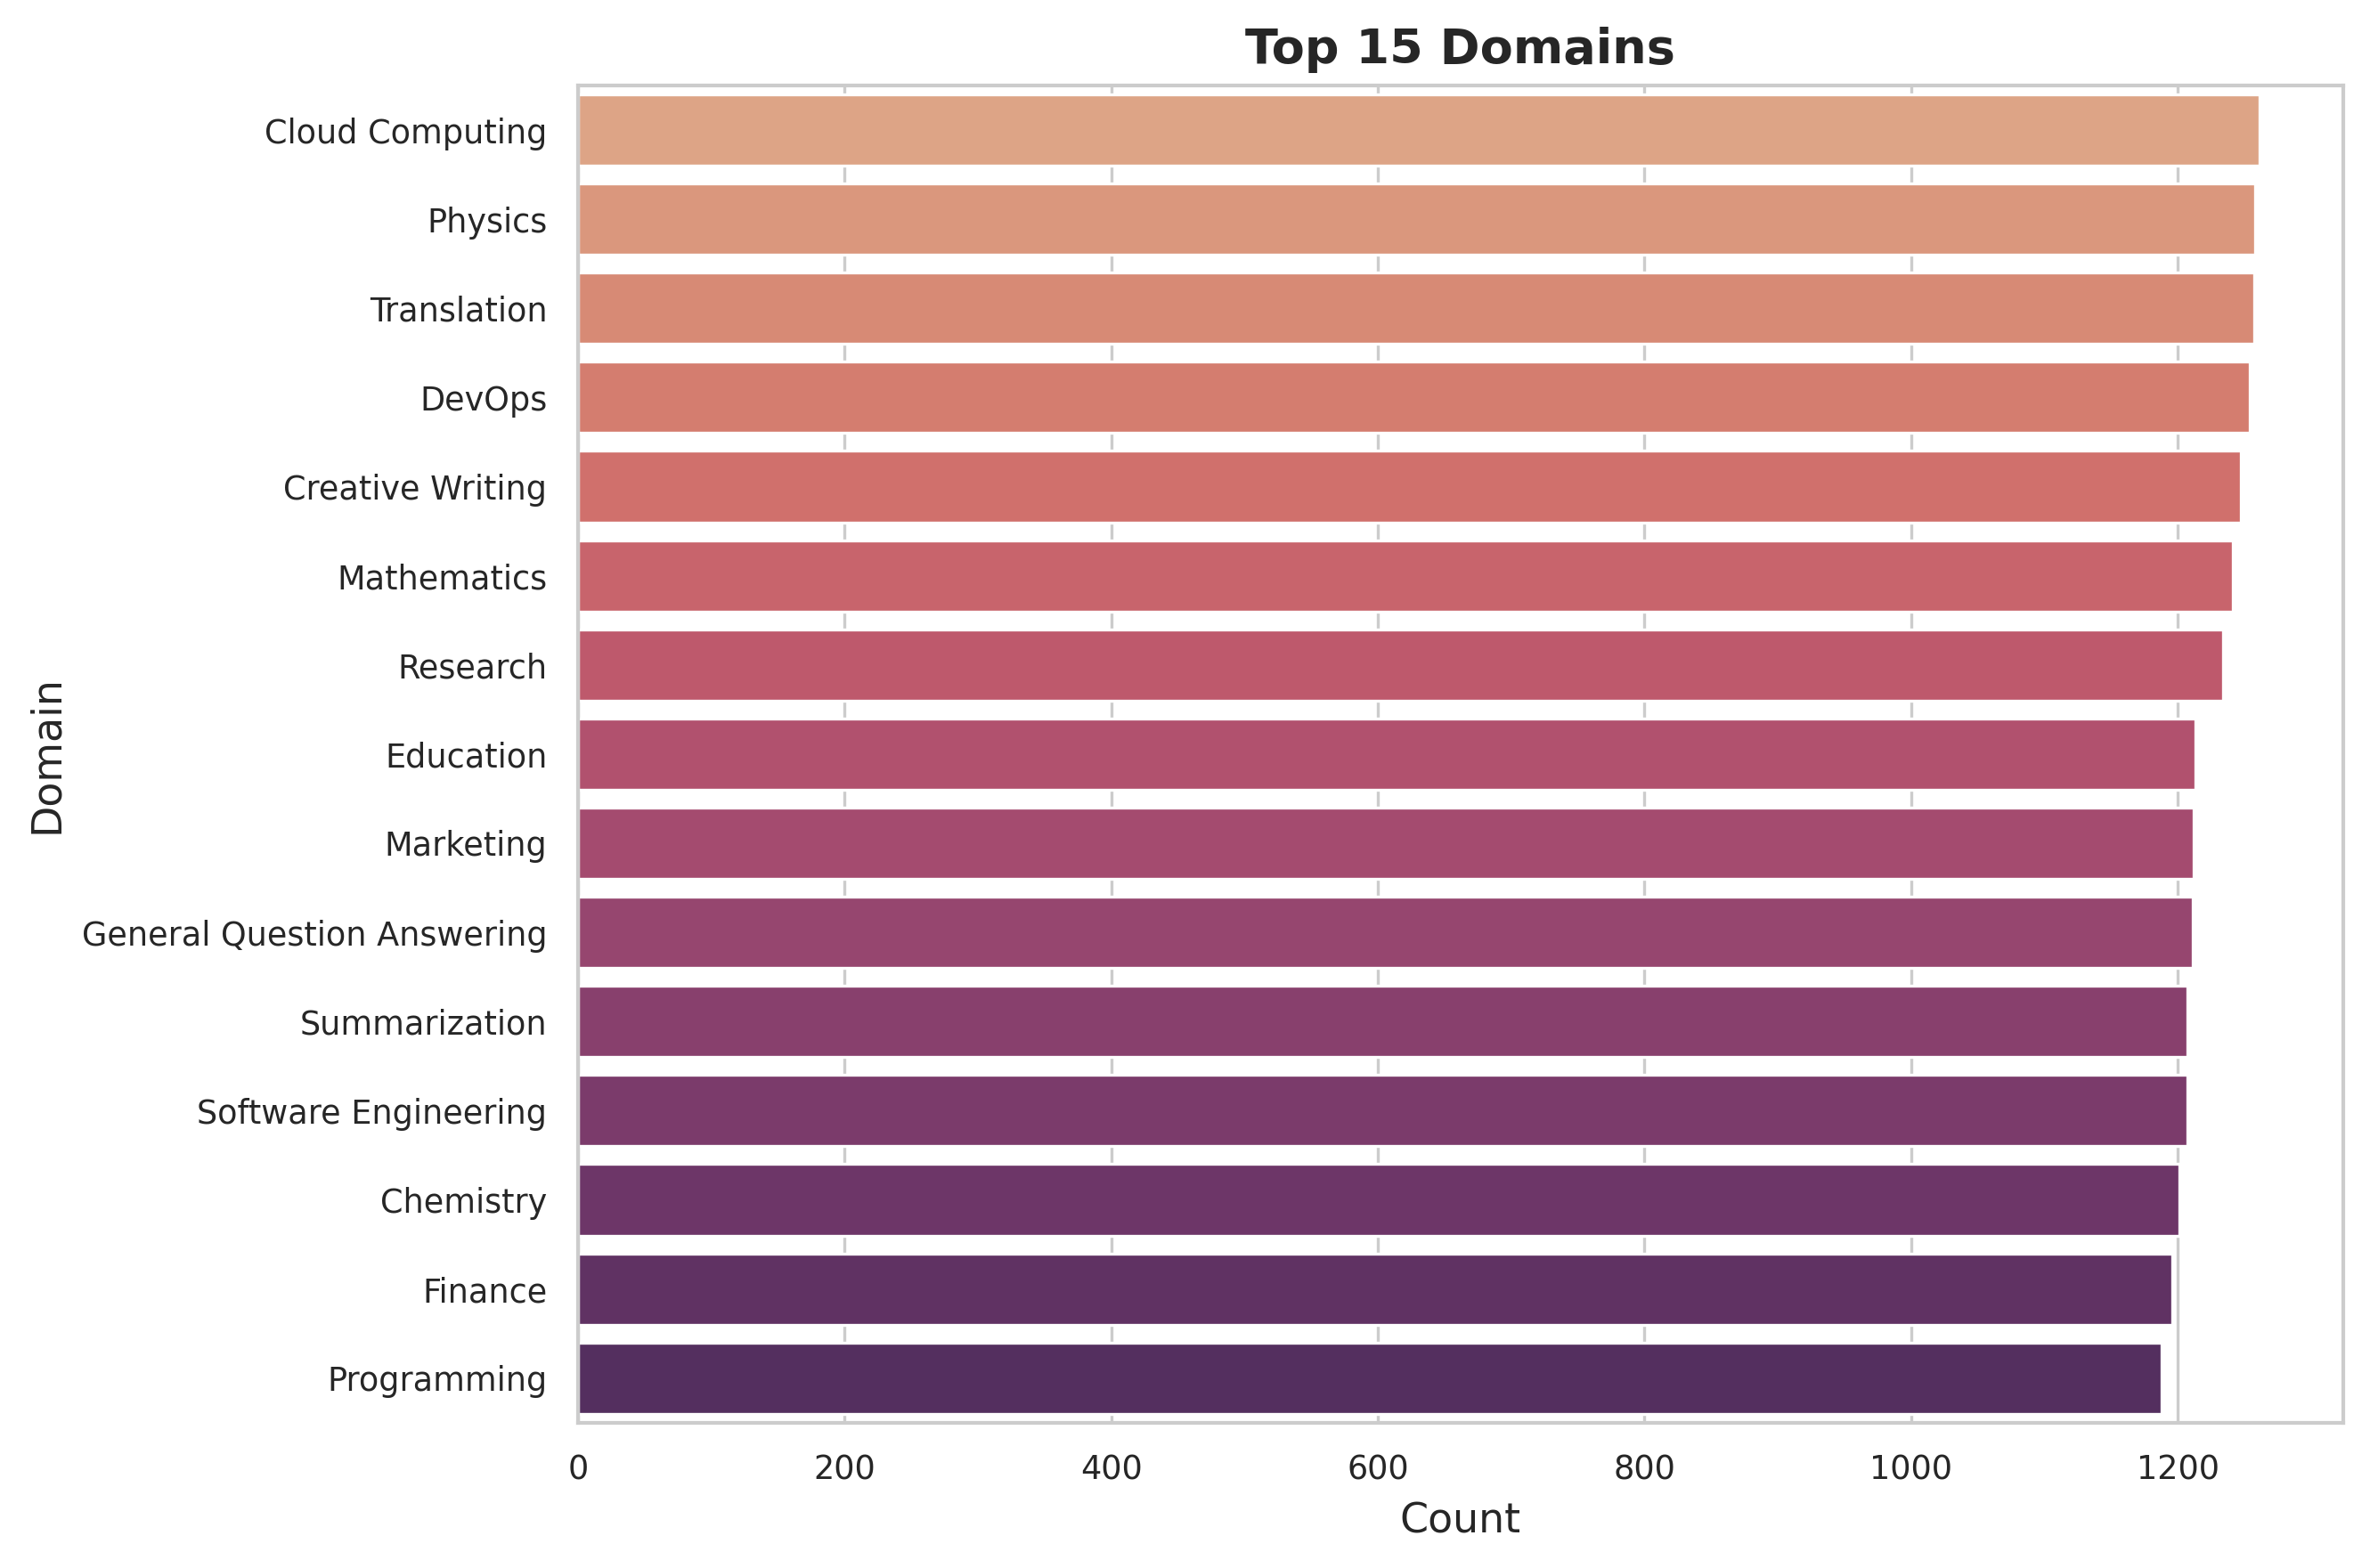

In [10]:
# ---------------------------------------------------------------
# 4.4 Domain distribution (top 15)
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))
top_sub = df["domain"].value_counts().nlargest(15)
sns.barplot(x=top_sub.values, y=top_sub.index, palette="flare", ax=ax)
ax.set_title("Top 15 Domains")
ax.set_xlabel("Count")
ax.set_ylabel("Domain")
save_figure(fig, "04_domain_distribution")
plt.show()

Saved figure: /content/thesis_outputs/figures/05_token_distribution.png


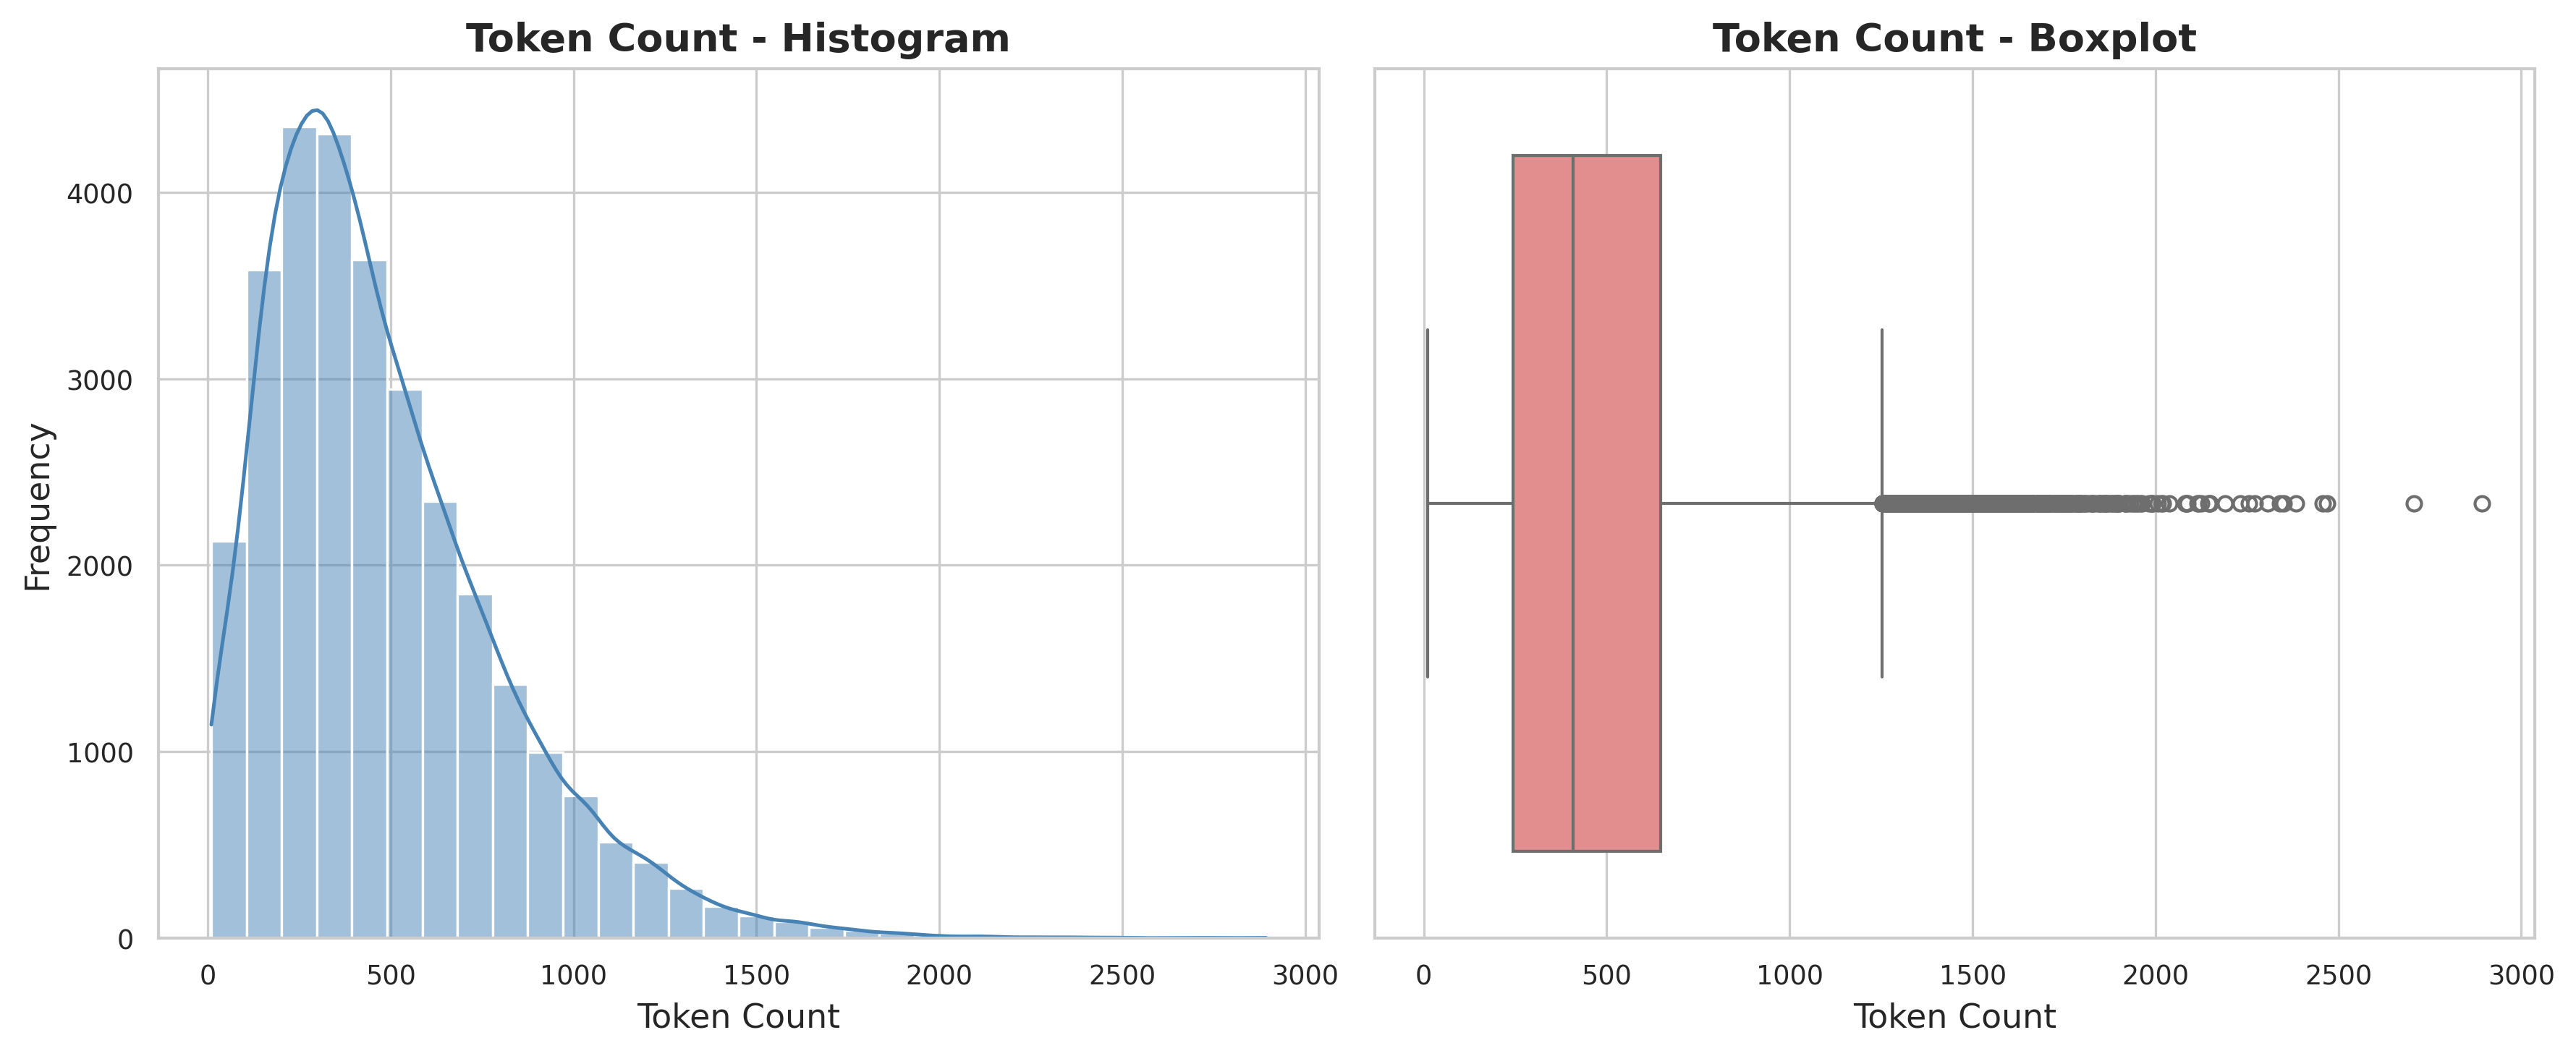

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df["token_count"], bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Token Count - Histogram")
axes[0].set_xlabel("Token Count")
axes[0].set_ylabel("Frequency")

sns.boxplot(x=df["token_count"], color="lightcoral", ax=axes[1])
axes[1].set_title("Token Count - Boxplot")
axes[1].set_xlabel("Token Count")

save_figure(fig, "05_token_distribution")
plt.tight_layout()
plt.show()

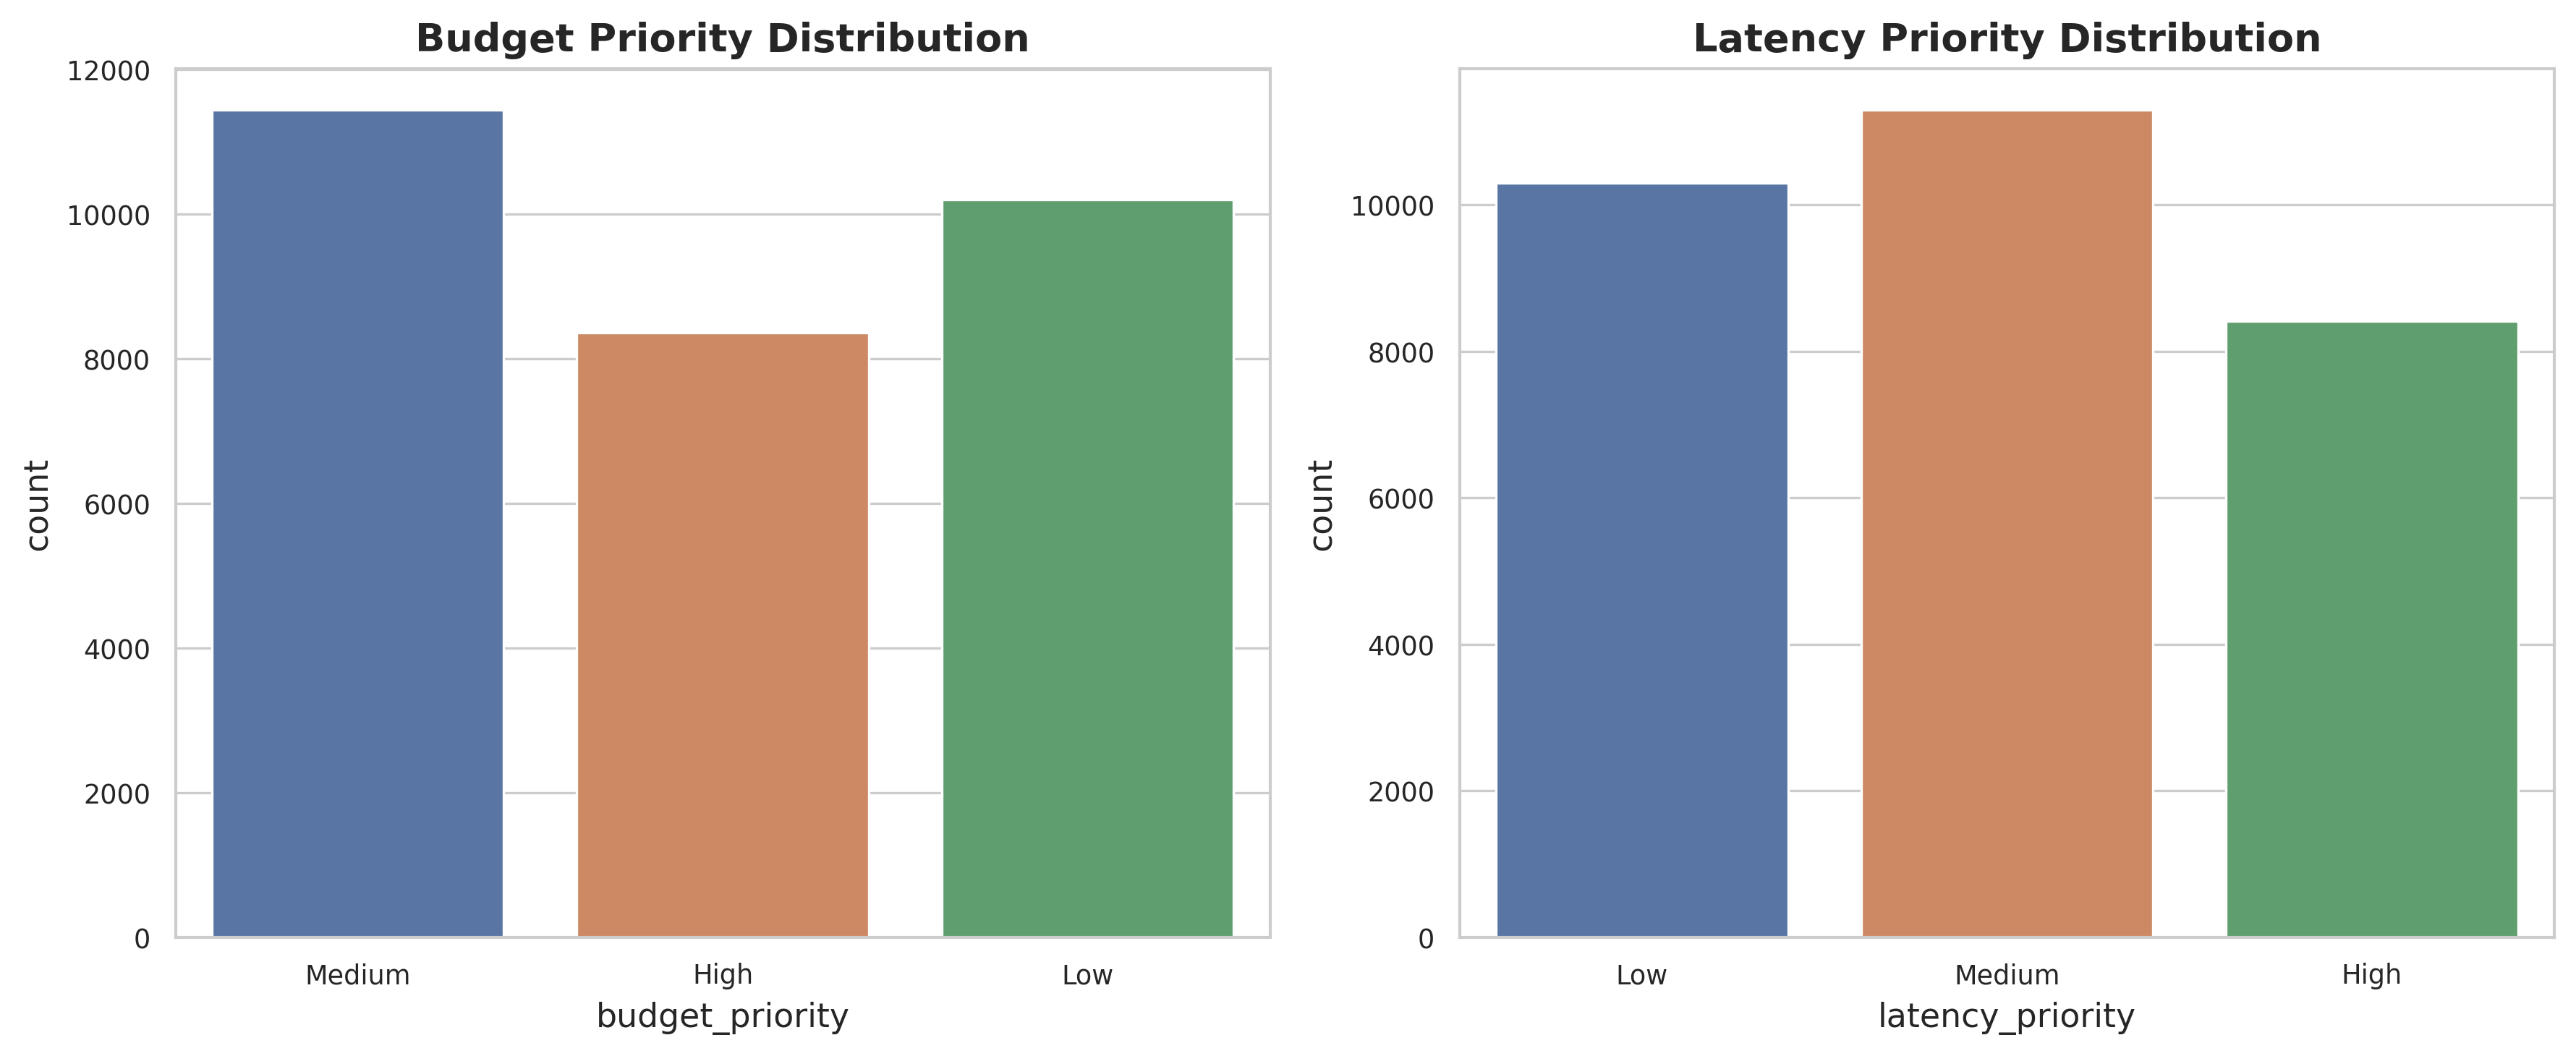

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("llm_routing_dataset.csv")   # তোমার path দাও

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(
    data=df,
    x="budget_priority",
    hue="budget_priority",
    legend=False,
    ax=axes[0]
)

sns.countplot(
    data=df,
    x="latency_priority",
    hue="latency_priority",
    legend=False,
    ax=axes[1]
)

axes[0].set_title("Budget Priority Distribution")
axes[1].set_title("Latency Priority Distribution")

plt.tight_layout()
plt.show()

Saved figure: /content/thesis_outputs/figures/07_preferred_model_pie.png


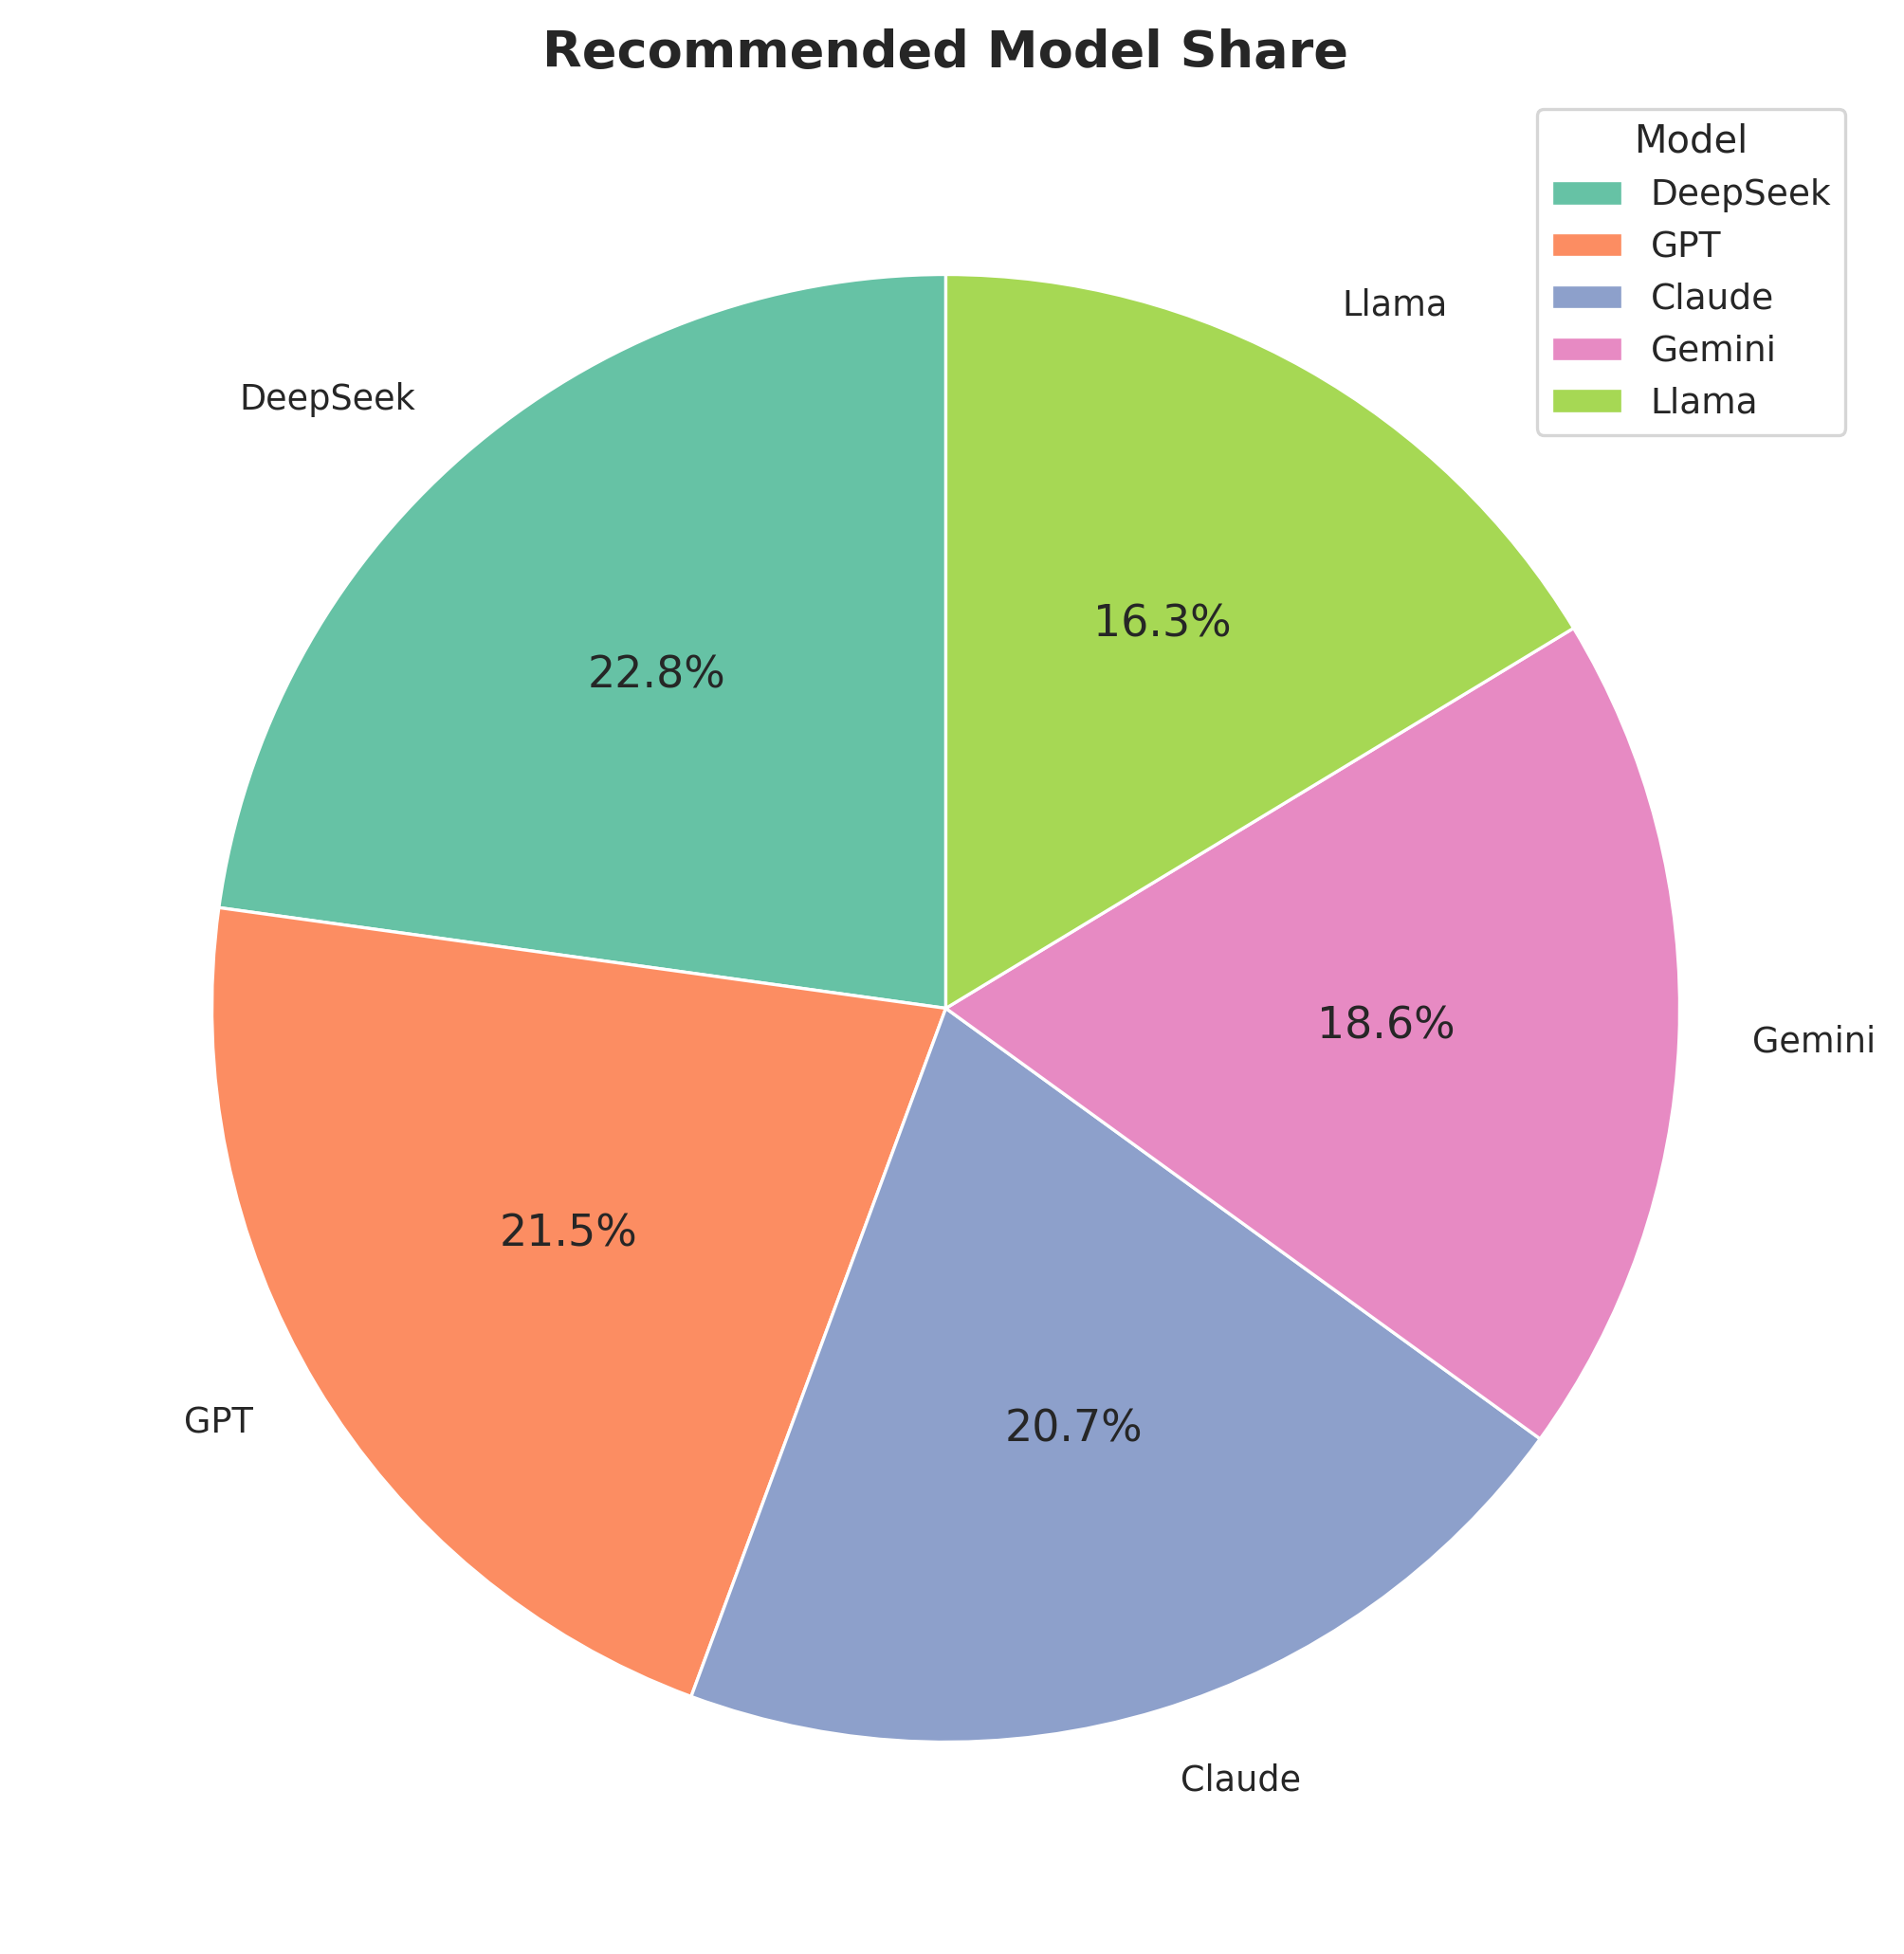

In [18]:
# ---------------------------------------------------------------
# 4.7 Pie chart - preferred model share
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 7))
counts = df["recommended_model"].value_counts()
ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=sns.color_palette("Set2", len(counts)))
ax.set_title("Recommended Model Share")
ax.legend(counts.index, title="Model", loc="best")
save_figure(fig, "07_preferred_model_pie")
plt.show()

Saved figure: /content/thesis_outputs/figures/08_correlation_heatmap.png


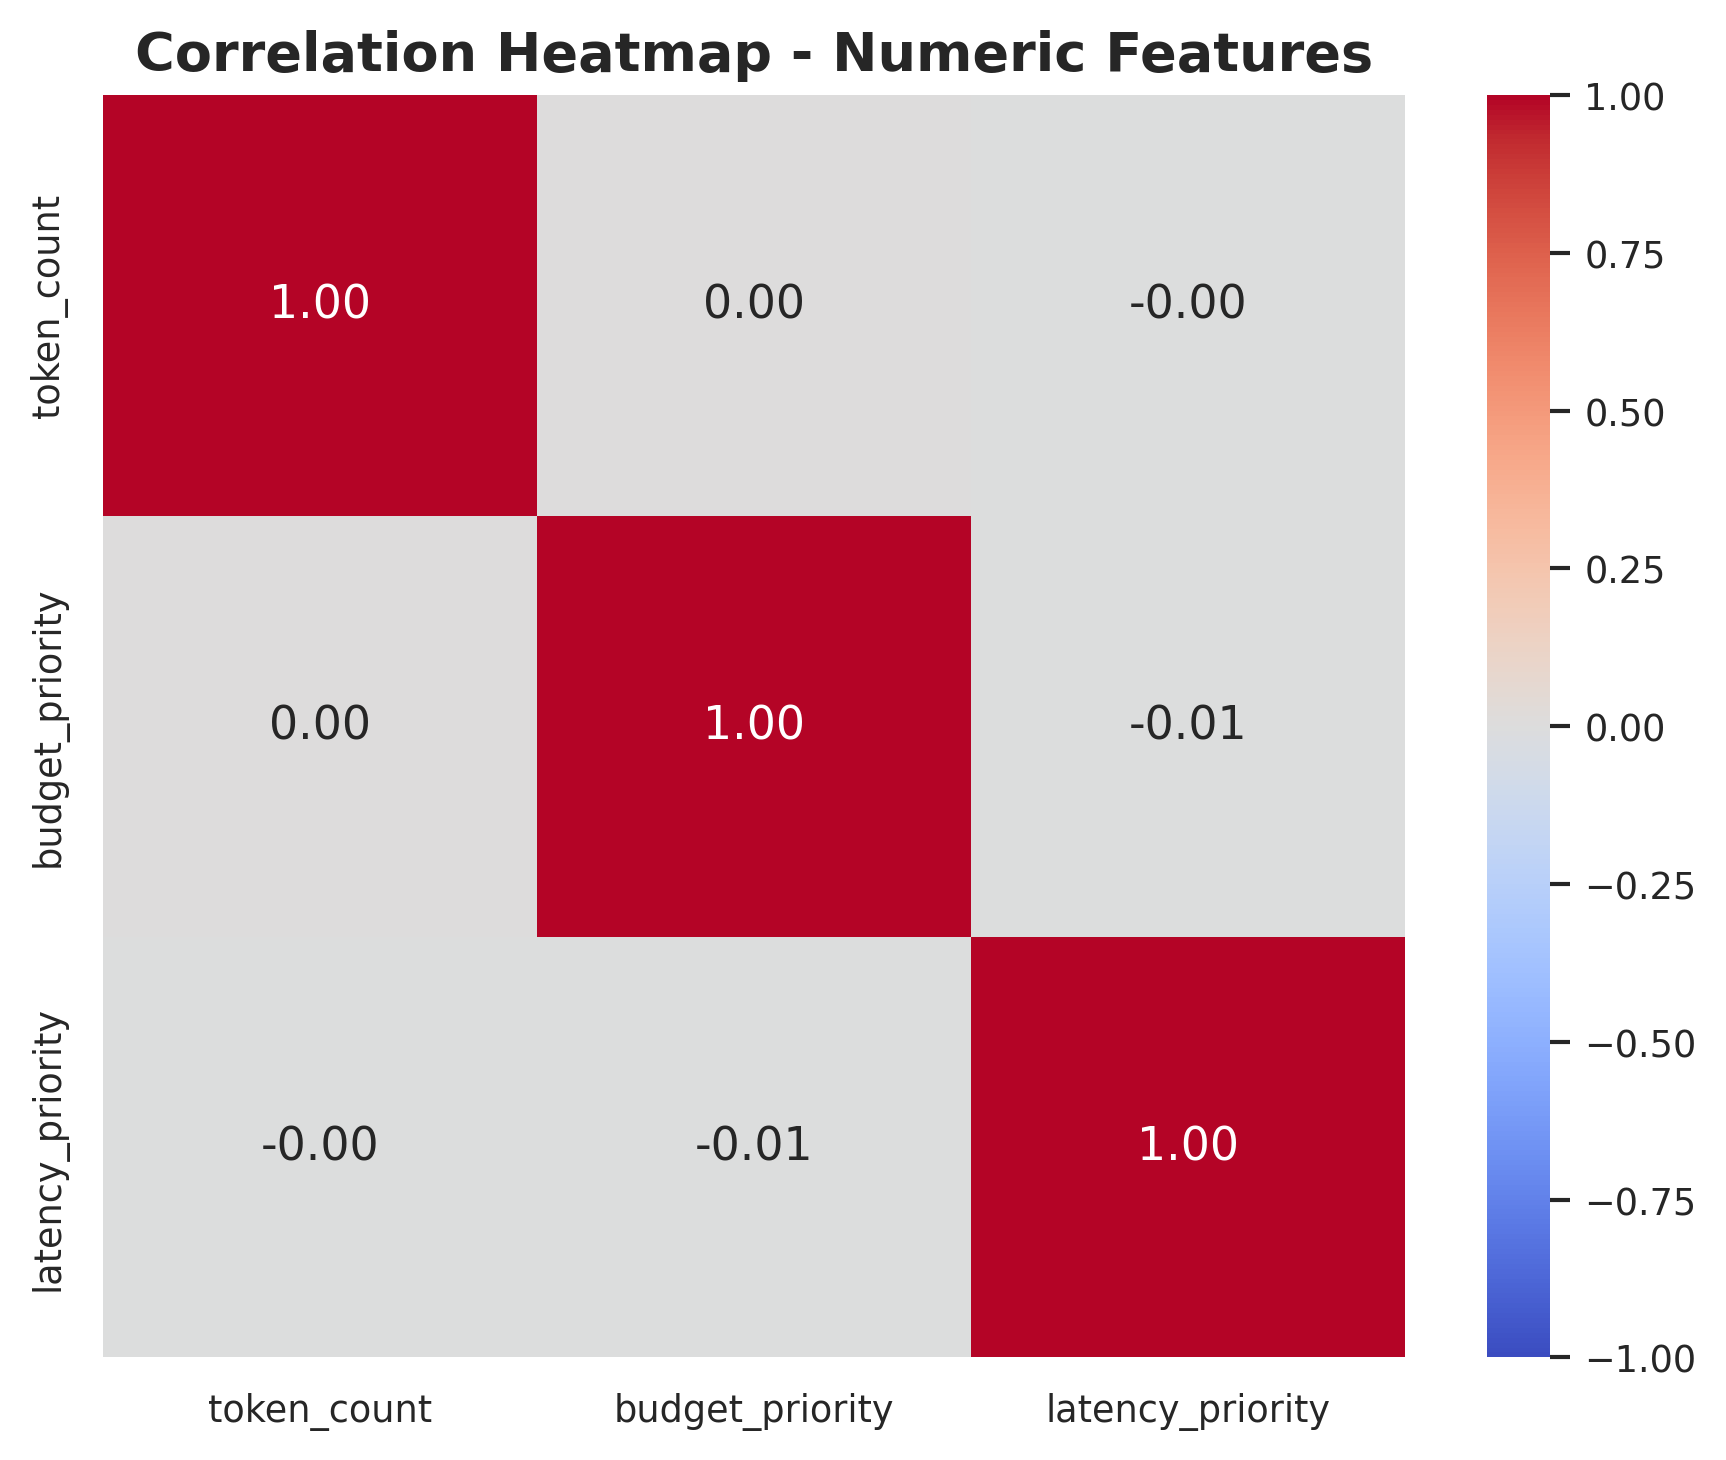

In [20]:
# ---------------------------------------------------------------
# 4.8 Correlation heatmap (numeric features)
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))

# Define the ordinal mapping for priority levels
priority_mapping = {'Low': 0, 'Medium': 1, 'High': 2}

# Create a temporary DataFrame to apply mapping and calculate correlation
temp_df_for_corr = df[["token_count", "budget_priority", "latency_priority"]].copy()

# Apply the mapping to convert string priorities to numeric
temp_df_for_corr["budget_priority"] = temp_df_for_corr["budget_priority"].map(priority_mapping)
temp_df_for_corr["latency_priority"] = temp_df_for_corr["latency_priority"].map(priority_mapping)

numeric_df = temp_df_for_corr
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax, fmt=".2f")
ax.set_title("Correlation Heatmap - Numeric Features")
save_figure(fig, "08_correlation_heatmap")
plt.show()

Saved figure: /content/thesis_outputs/figures/09_boxplots_by_model.png


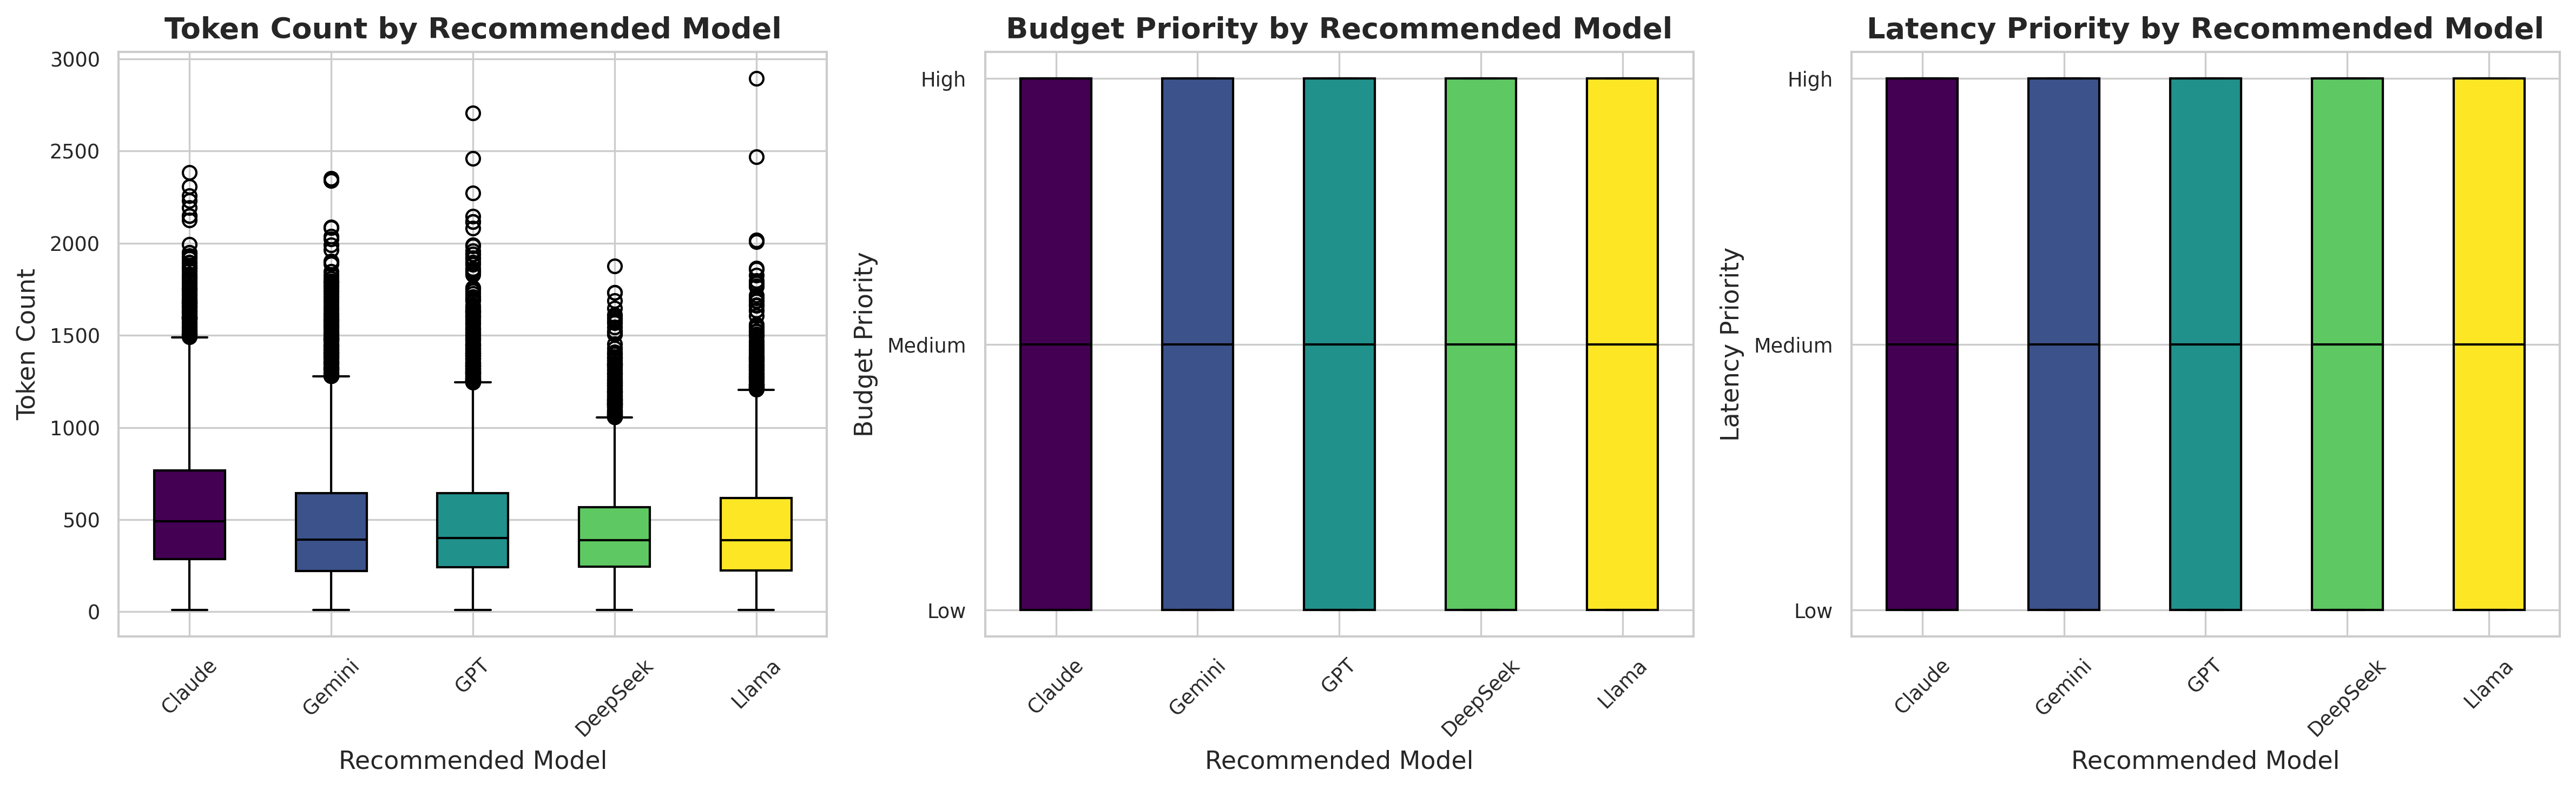

In [22]:
# ---------------------------------------------------------------
# 4.9 Boxplots of numeric features grouped by recommended model
# ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Get unique recommended models for x-axis categories
recommended_models = df["recommended_model"].unique()

# Define the ordinal mapping for priority levels for consistency and to fix error
priority_mapping = {'Low': 0, 'Medium': 1, 'High': 2}

# Generate colors for each box
box_colors = [plt.cm.viridis(x) for x in np.linspace(0, 1, len(recommended_models))]

for ax, col in zip(axes, ["token_count", "budget_priority", "latency_priority"]):
    # Create a temporary series for the current column
    temp_col_series = df[col].copy()

    # Apply mapping for priority columns if they are not numeric
    if col in ["budget_priority", "latency_priority"]:
        # Check if mapping is needed (i.e., if column is still object/string type)
        if pd.api.types.is_object_dtype(temp_col_series) or pd.api.types.is_string_dtype(temp_col_series):
            temp_col_series = temp_col_series.map(priority_mapping)

    # Prepare data for matplotlib boxplot using the potentially mapped series
    data_for_boxplot = [temp_col_series[df["recommended_model"] == model_name].dropna() for model_name in recommended_models]

    # Create boxplot using matplotlib.pyplot
    bp = ax.boxplot(data_for_boxplot, labels=recommended_models, patch_artist=True,
                    medianprops=dict(color="black"))

    # Color the boxes individually
    for patch, color in zip(bp["boxes"], box_colors):
        patch.set_facecolor(color)

    ax.set_title(f"{col.replace('_', ' ').title()} by Recommended Model")
    ax.set_xlabel("Recommended Model")
    ax.set_ylabel(col.replace("_", " ").title())

    # Adjust y-axis ticks and labels for priority columns to show original string labels
    if col in ["budget_priority", "latency_priority"]:
        # Get unique numeric values that were mapped (from the temp_col_series)
        unique_numeric_priorities = sorted(temp_col_series.dropna().unique())
        # Create a reverse mapping for labels to display on the y-axis
        reverse_priority_mapping = {v: k for k, v in priority_mapping.items()}
        ax.set_yticks(unique_numeric_priorities)
        ax.set_yticklabels([reverse_priority_mapping[val] for val in unique_numeric_priorities])


    ax.tick_params(axis="x", rotation=45)
save_figure(fig, "09_boxplots_by_model")
plt.tight_layout()
plt.show()

## 5. Feature Engineering
Encode categorical variables with label encoding and one-hot encoding where appropriate.

In [23]:
# ---------------------------------------------------------------
# 5.1 Separate features and target
# ---------------------------------------------------------------
TARGET_COL = "recommended_model"

feature_df = df.drop(columns=["query_id", "query", TARGET_COL]).copy()
target_raw = df[TARGET_COL].copy()

# ---------------------------------------------------------------
# 5.2 Label-encode the target
# ---------------------------------------------------------------
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(target_raw)
CLASS_NAMES = target_encoder.classes_
print("Target classes:", list(CLASS_NAMES))

# ---------------------------------------------------------------
# 5.3 Label-encode ordinal-like features: complexity, reasoning_level, urgency, quality_priority, budget_priority, and latency_priority
# ---------------------------------------------------------------
difficulty_encoder = LabelEncoder()
feature_df["difficulty_encoded"] = difficulty_encoder.fit_transform(feature_df["complexity"])

reasoning_level_encoder = LabelEncoder()
feature_df["reasoning_level_encoded"] = reasoning_level_encoder.fit_transform(feature_df["reasoning_level"])

urgency_encoder = LabelEncoder()
feature_df["urgency_encoded"] = urgency_encoder.fit_transform(feature_df["urgency"])

quality_priority_encoder = LabelEncoder()
feature_df["quality_priority_encoded"] = quality_priority_encoder.fit_transform(feature_df["quality_priority"])

budget_priority_encoder = LabelEncoder()
feature_df["budget_priority_encoded"] = budget_priority_encoder.fit_transform(feature_df["budget_priority"])

latency_priority_encoder = LabelEncoder()
feature_df["latency_priority_encoded"] = latency_priority_encoder.fit_transform(feature_df["latency_priority"])

# ---------------------------------------------------------------
# 5.4 One-hot encode nominal categorical features: category, domain, best_quality_model, lowest_cost_model, lowest_latency_model
# ---------------------------------------------------------------
categorical_nominal = ["category", "domain", "best_quality_model", "lowest_cost_model", "lowest_latency_model"]
feature_df_ohe = pd.get_dummies(feature_df, columns=categorical_nominal, prefix=categorical_nominal)

# Drop the original text-based ordinal columns (now encoded numerically)
feature_df_ohe = feature_df_ohe.drop(columns=["complexity", "reasoning_level", "urgency", "quality_priority", "budget_priority", "latency_priority"])

# ---------------------------------------------------------------
# 5.5 Final feature matrix
# ---------------------------------------------------------------
X = feature_df_ohe.copy()
FEATURE_NAMES = X.columns.tolist()

print(f"\nFinal feature matrix shape: {X.shape}")
print(f"Number of features after encoding: {len(FEATURE_NAMES)}")
display(X.head())

Target classes: ['Claude', 'DeepSeek', 'GPT', 'Gemini', 'Llama']

Final feature matrix shape: (30000, 82)
Number of features after encoding: 82


,token_count,context_length,requires_code,requires_math,requires_reasoning,requires_creativity,multilingual,gpt_quality_score,claude_quality_score,gemini_quality_score,...,best_quality_model_Gemini,best_quality_model_Llama,lowest_cost_model_DeepSeek,lowest_cost_model_Gemini,lowest_cost_model_Llama,lowest_latency_model_Claude,lowest_latency_model_DeepSeek,lowest_latency_model_GPT,lowest_latency_model_Gemini,lowest_latency_model_Llama
0,607,376,True,False,False,False,False,8.32,9.14,8.19,...,False,False,False,False,True,False,True,False,False,False
1,131,334,False,False,False,False,False,7.47,7.70,8.04,...,True,False,False,False,True,False,False,False,False,True
2,984,230,False,False,True,True,False,7.51,9.70,8.12,...,False,False,False,False,True,False,True,False,False,False
3,621,409,False,False,True,False,True,8.38,8.24,7.85,...,False,False,False,False,True,False,False,False,True,False
4,164,250,False,False,False,False,False,7.07,7.12,7.62,...,True,False,False,False,True,False,False,False,True,False


## 6. Train/Test Split
80/20 split with `random_state=42`.

In [24]:
# ---------------------------------------------------------------
# 6.1 Stratified 80/20 split
# ---------------------------------------------------------------
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")


Training set: 24000 samples
Test set:     6000 samples


## 7. Baseline Model
Decision Tree classifier as the baseline.

In [25]:
# ---------------------------------------------------------------
# 7.1 Train baseline Decision Tree
# ---------------------------------------------------------------
baseline_model = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline_model.fit(X_train, y_train)
baseline_preds = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_preds)
print(f"Baseline Decision Tree Accuracy: {baseline_accuracy:.4f}")


Baseline Decision Tree Accuracy: 0.9257


## 8. Advanced Models
Train seven advanced classifiers used for comparison and routing.

In [26]:
# ---------------------------------------------------------------
# 8.1 Instantiate all advanced models
# ---------------------------------------------------------------
n_classes = len(CLASS_NAMES)

models = {
    "Decision Tree": baseline_model,
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=300),
    "XGBoost": XGBClassifier(
        random_state=RANDOM_STATE, eval_metric="mlogloss",
        use_label_encoder=False, n_estimators=300,
    ),
    "LightGBM": LGBMClassifier(random_state=RANDOM_STATE, n_estimators=300, verbosity=-1),
    "CatBoost": CatBoostClassifier(random_state=RANDOM_STATE, verbose=0, iterations=300),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE, n_estimators=200),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(random_state=RANDOM_STATE, n_estimators=300),
}

trained_models = {}
training_times = {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start
    trained_models[name] = model
    training_times[name] = elapsed
    print(f"Trained {name:<20s} in {elapsed:6.2f}s")


Trained Decision Tree        in   0.88s
Trained Random Forest        in  33.80s
Trained XGBoost              in  15.82s
Trained LightGBM             in  11.36s
Trained CatBoost             in  15.02s
Trained Gradient Boosting    in 184.85s
Trained Logistic Regression  in  83.04s
Trained Extra Trees          in  15.69s


## 9. Hyperparameter Tuning
RandomizedSearchCV is used to tune the two strongest tree-based candidates (Random Forest and XGBoost). Tuned versions replace the default versions in the model dictionary.

In [27]:
# ---------------------------------------------------------------
# 9.1 Tune Random Forest
# ---------------------------------------------------------------
rf_param_dist = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_distributions=rf_param_dist,
    n_iter=15,
    cv=3,
    scoring="f1_weighted",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)
trained_models["Random Forest"] = rf_search.best_estimator_
print("Best Random Forest params:", rf_search.best_params_)

# ---------------------------------------------------------------
# 9.2 Tune XGBoost
# ---------------------------------------------------------------
xgb_param_dist = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [3, 5, 7, 9],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
}

xgb_search = RandomizedSearchCV(
    XGBClassifier(random_state=RANDOM_STATE, eval_metric="mlogloss", use_label_encoder=False),
    param_distributions=xgb_param_dist,
    n_iter=15,
    cv=3,
    scoring="f1_weighted",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb_search.fit(X_train, y_train)
trained_models["XGBoost"] = xgb_search.best_estimator_
print("Best XGBoost params:", xgb_search.best_params_)

print("\nHyperparameter tuning complete. Tuned models have replaced the default versions.")


Best Random Forest params: {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}
Best XGBoost params: {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.2, 'colsample_bytree': 1.0}

Hyperparameter tuning complete. Tuned models have replaced the default versions.


## 10. Model Evaluation
Accuracy, precision, recall, F1, confusion matrix, classification report, ROC curves and cross-validation for every model.

In [28]:
# ---------------------------------------------------------------
# 10.1 Evaluation helper function
# ---------------------------------------------------------------
def evaluate_model(name, model, X_te, y_te):
    '''Compute the full evaluation metric suite for one trained model.'''
    preds = model.predict(X_te)

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_te, preds),
        "Precision": precision_score(y_te, preds, average="weighted", zero_division=0),
        "Recall": recall_score(y_te, preds, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_te, preds, average="weighted", zero_division=0),
    }
    return metrics, preds

evaluation_results = []
predictions_by_model = {}

for name, model in trained_models.items():
    metrics, preds = evaluate_model(name, model, X_test, y_test)
    evaluation_results.append(metrics)
    predictions_by_model[name] = preds
    print(f"{name}: Accuracy={metrics['Accuracy']:.4f}  F1={metrics['F1 Score']:.4f}")

metrics_df = pd.DataFrame(evaluation_results).sort_values("F1 Score", ascending=False).reset_index(drop=True)
display(metrics_df)


Decision Tree: Accuracy=0.9257  F1=0.9257
Random Forest: Accuracy=0.9210  F1=0.9209
XGBoost: Accuracy=0.9770  F1=0.9770
LightGBM: Accuracy=0.9703  F1=0.9703
CatBoost: Accuracy=0.9703  F1=0.9703
Gradient Boosting: Accuracy=0.9683  F1=0.9683
Logistic Regression: Accuracy=0.9350  F1=0.9348
Extra Trees: Accuracy=0.8760  F1=0.8753


,Model,Accuracy,Precision,Recall,F1 Score
0,XGBoost,0.977000,0.977039,0.977000,0.977009
1,CatBoost,0.970333,0.970449,0.970333,0.970345
2,LightGBM,0.970333,0.970360,0.970333,0.970334
3,Gradient Boosting,0.968333,0.968335,0.968333,0.968313
4,Logistic Regression,0.935000,0.936659,0.935000,0.934840
5,Decision Tree,0.925667,0.925724,0.925667,0.925666
6,Random Forest,0.921000,0.927242,0.921000,0.920915
7,Extra Trees,0.876000,0.896781,0.876000,0.875298


Saved figure: /content/thesis_outputs/figures/10_confusion_matrices_all_models.png


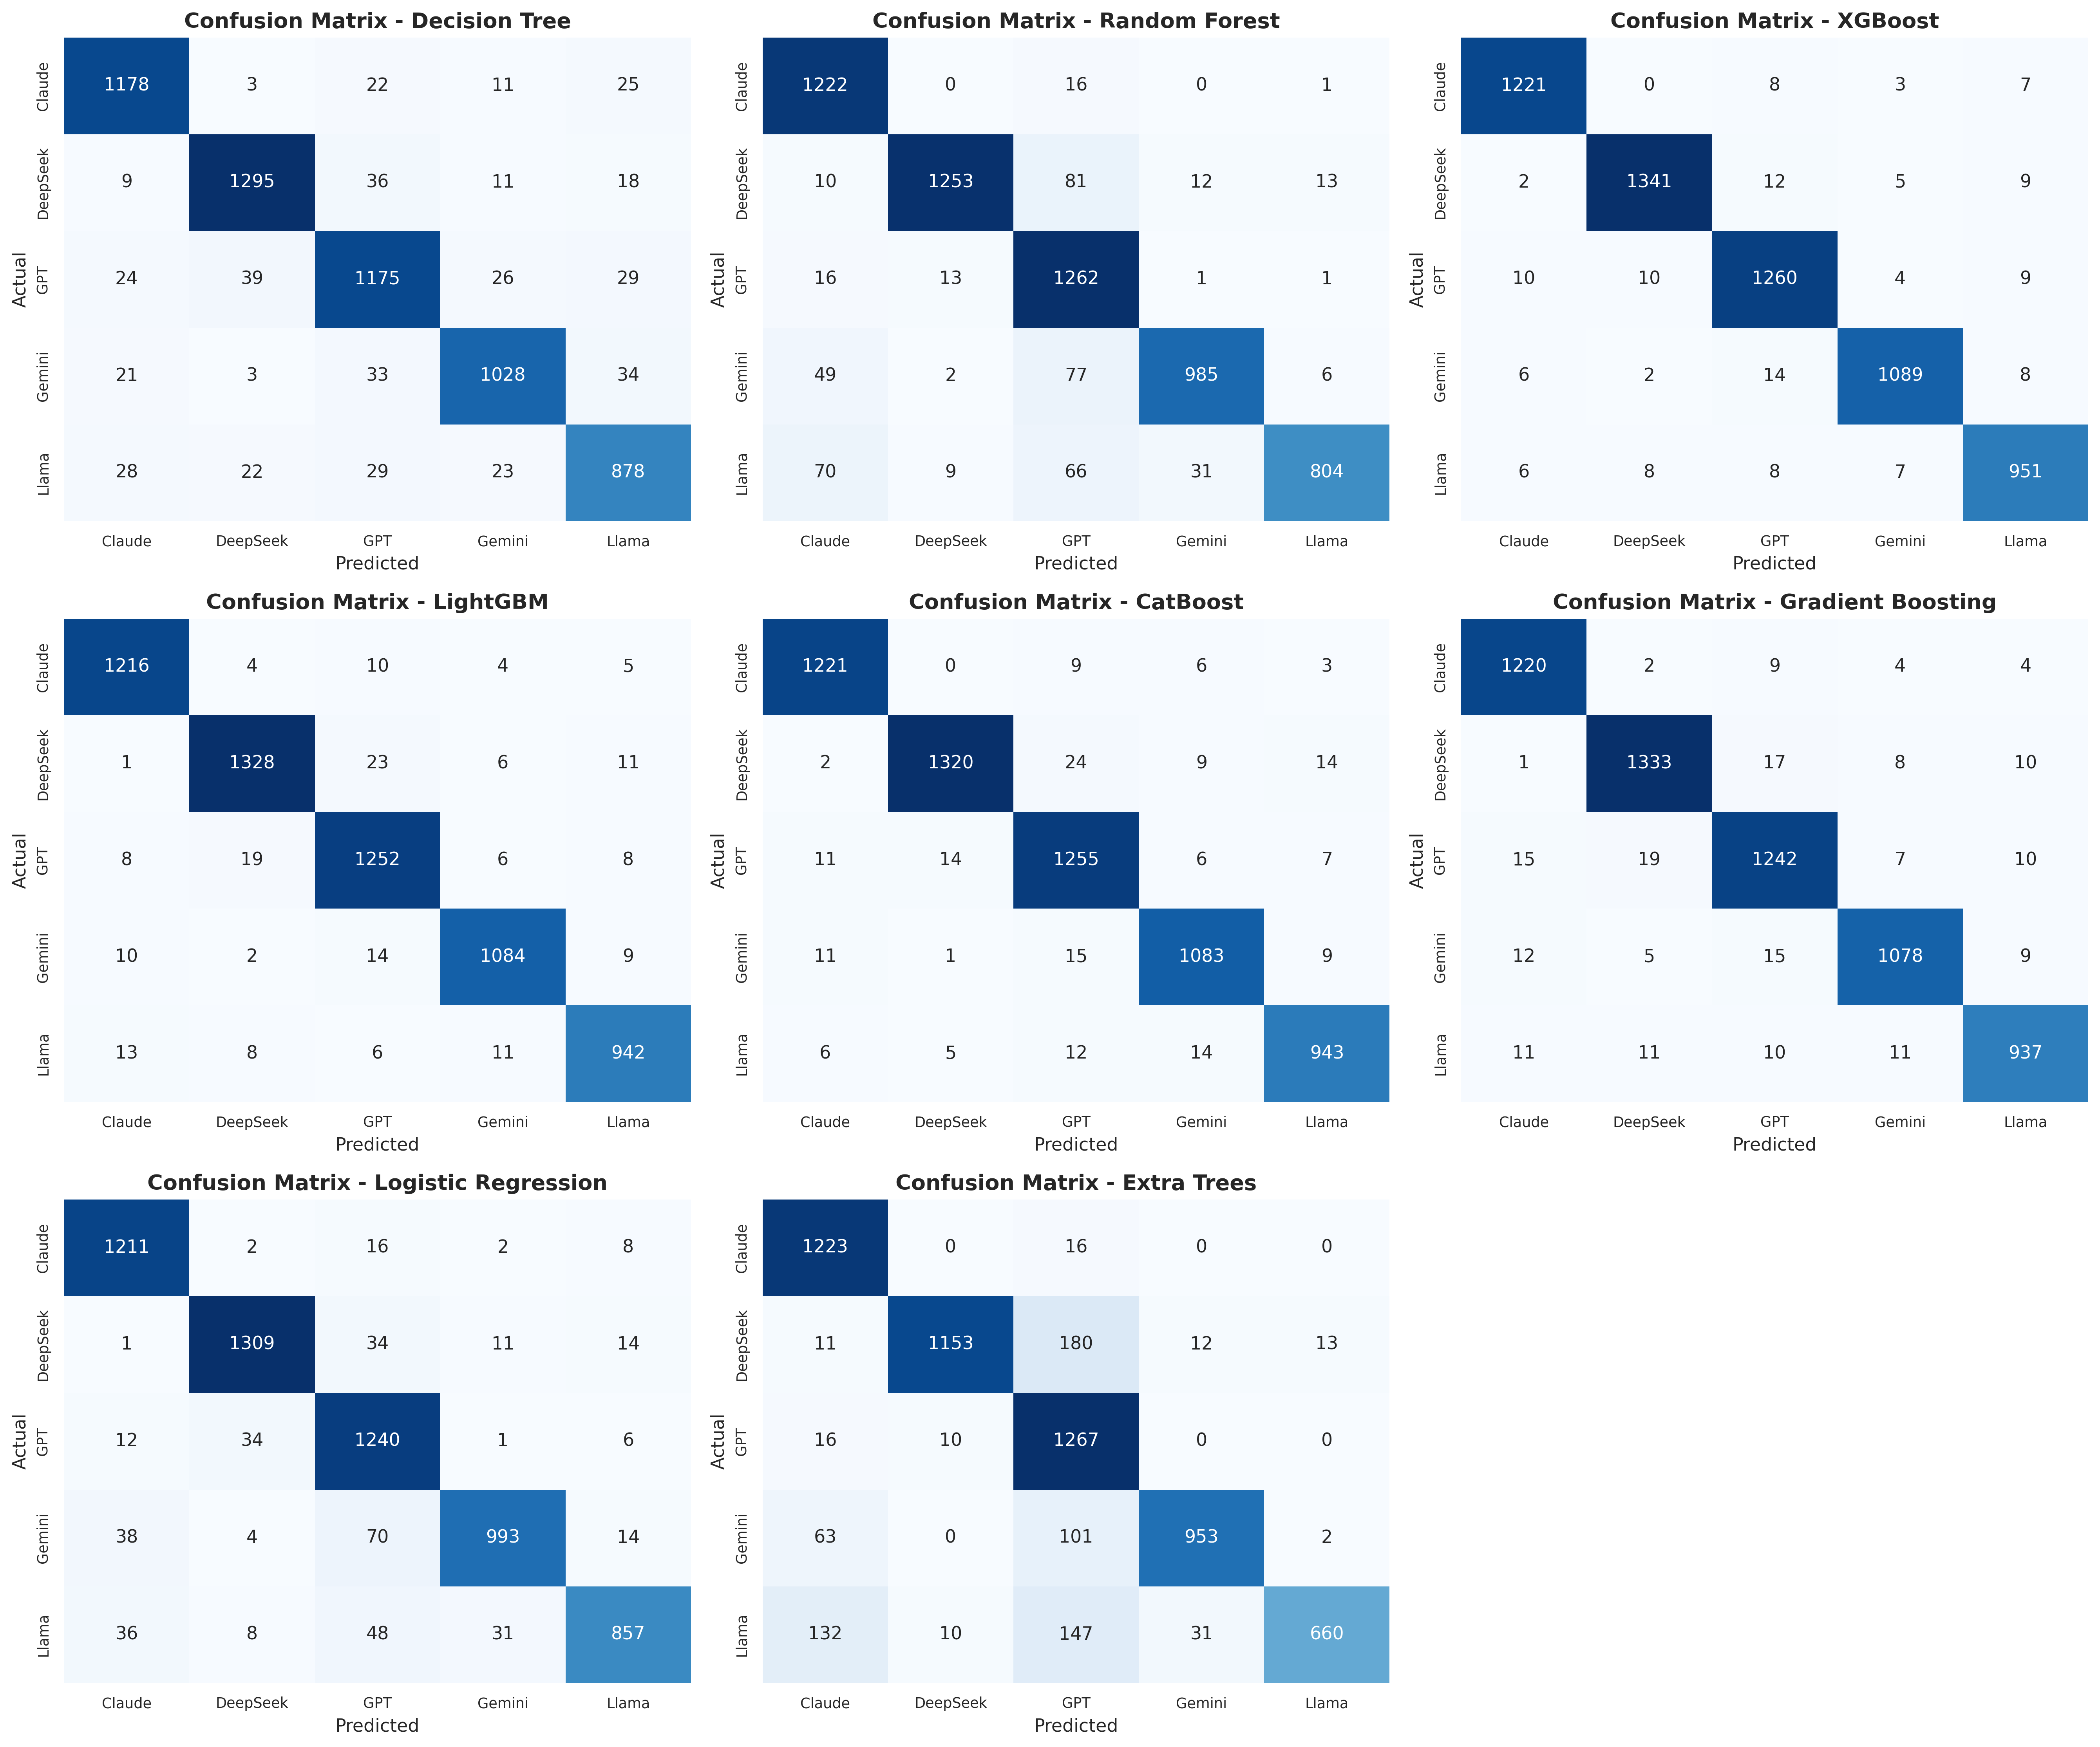

In [29]:
# ---------------------------------------------------------------
# 10.2 Confusion matrices for every model
# ---------------------------------------------------------------
n_models = len(trained_models)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, (name, preds) in zip(axes, predictions_by_model.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax, cbar=False)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

# Hide any unused subplots
for ax in axes[len(predictions_by_model):]:
    ax.axis("off")

save_figure(fig, "10_confusion_matrices_all_models")
plt.show()


In [30]:
# ---------------------------------------------------------------
# 10.3 Classification reports
# ---------------------------------------------------------------
for name, preds in predictions_by_model.items():
    print("=" * 70)
    print(f"Classification Report - {name}")
    print("=" * 70)
    print(classification_report(y_test, preds, target_names=CLASS_NAMES, zero_division=0))


Classification Report - Decision Tree
              precision    recall  f1-score   support

      Claude       0.93      0.95      0.94      1239
    DeepSeek       0.95      0.95      0.95      1369
         GPT       0.91      0.91      0.91      1293
      Gemini       0.94      0.92      0.93      1119
       Llama       0.89      0.90      0.89       980

    accuracy                           0.93      6000
   macro avg       0.92      0.92      0.92      6000
weighted avg       0.93      0.93      0.93      6000

Classification Report - Random Forest
              precision    recall  f1-score   support

      Claude       0.89      0.99      0.94      1239
    DeepSeek       0.98      0.92      0.95      1369
         GPT       0.84      0.98      0.90      1293
      Gemini       0.96      0.88      0.92      1119
       Llama       0.97      0.82      0.89       980

    accuracy                           0.92      6000
   macro avg       0.93      0.92      0.92      6000
w

Saved figure: /content/thesis_outputs/figures/11_roc_curves_best_model.png


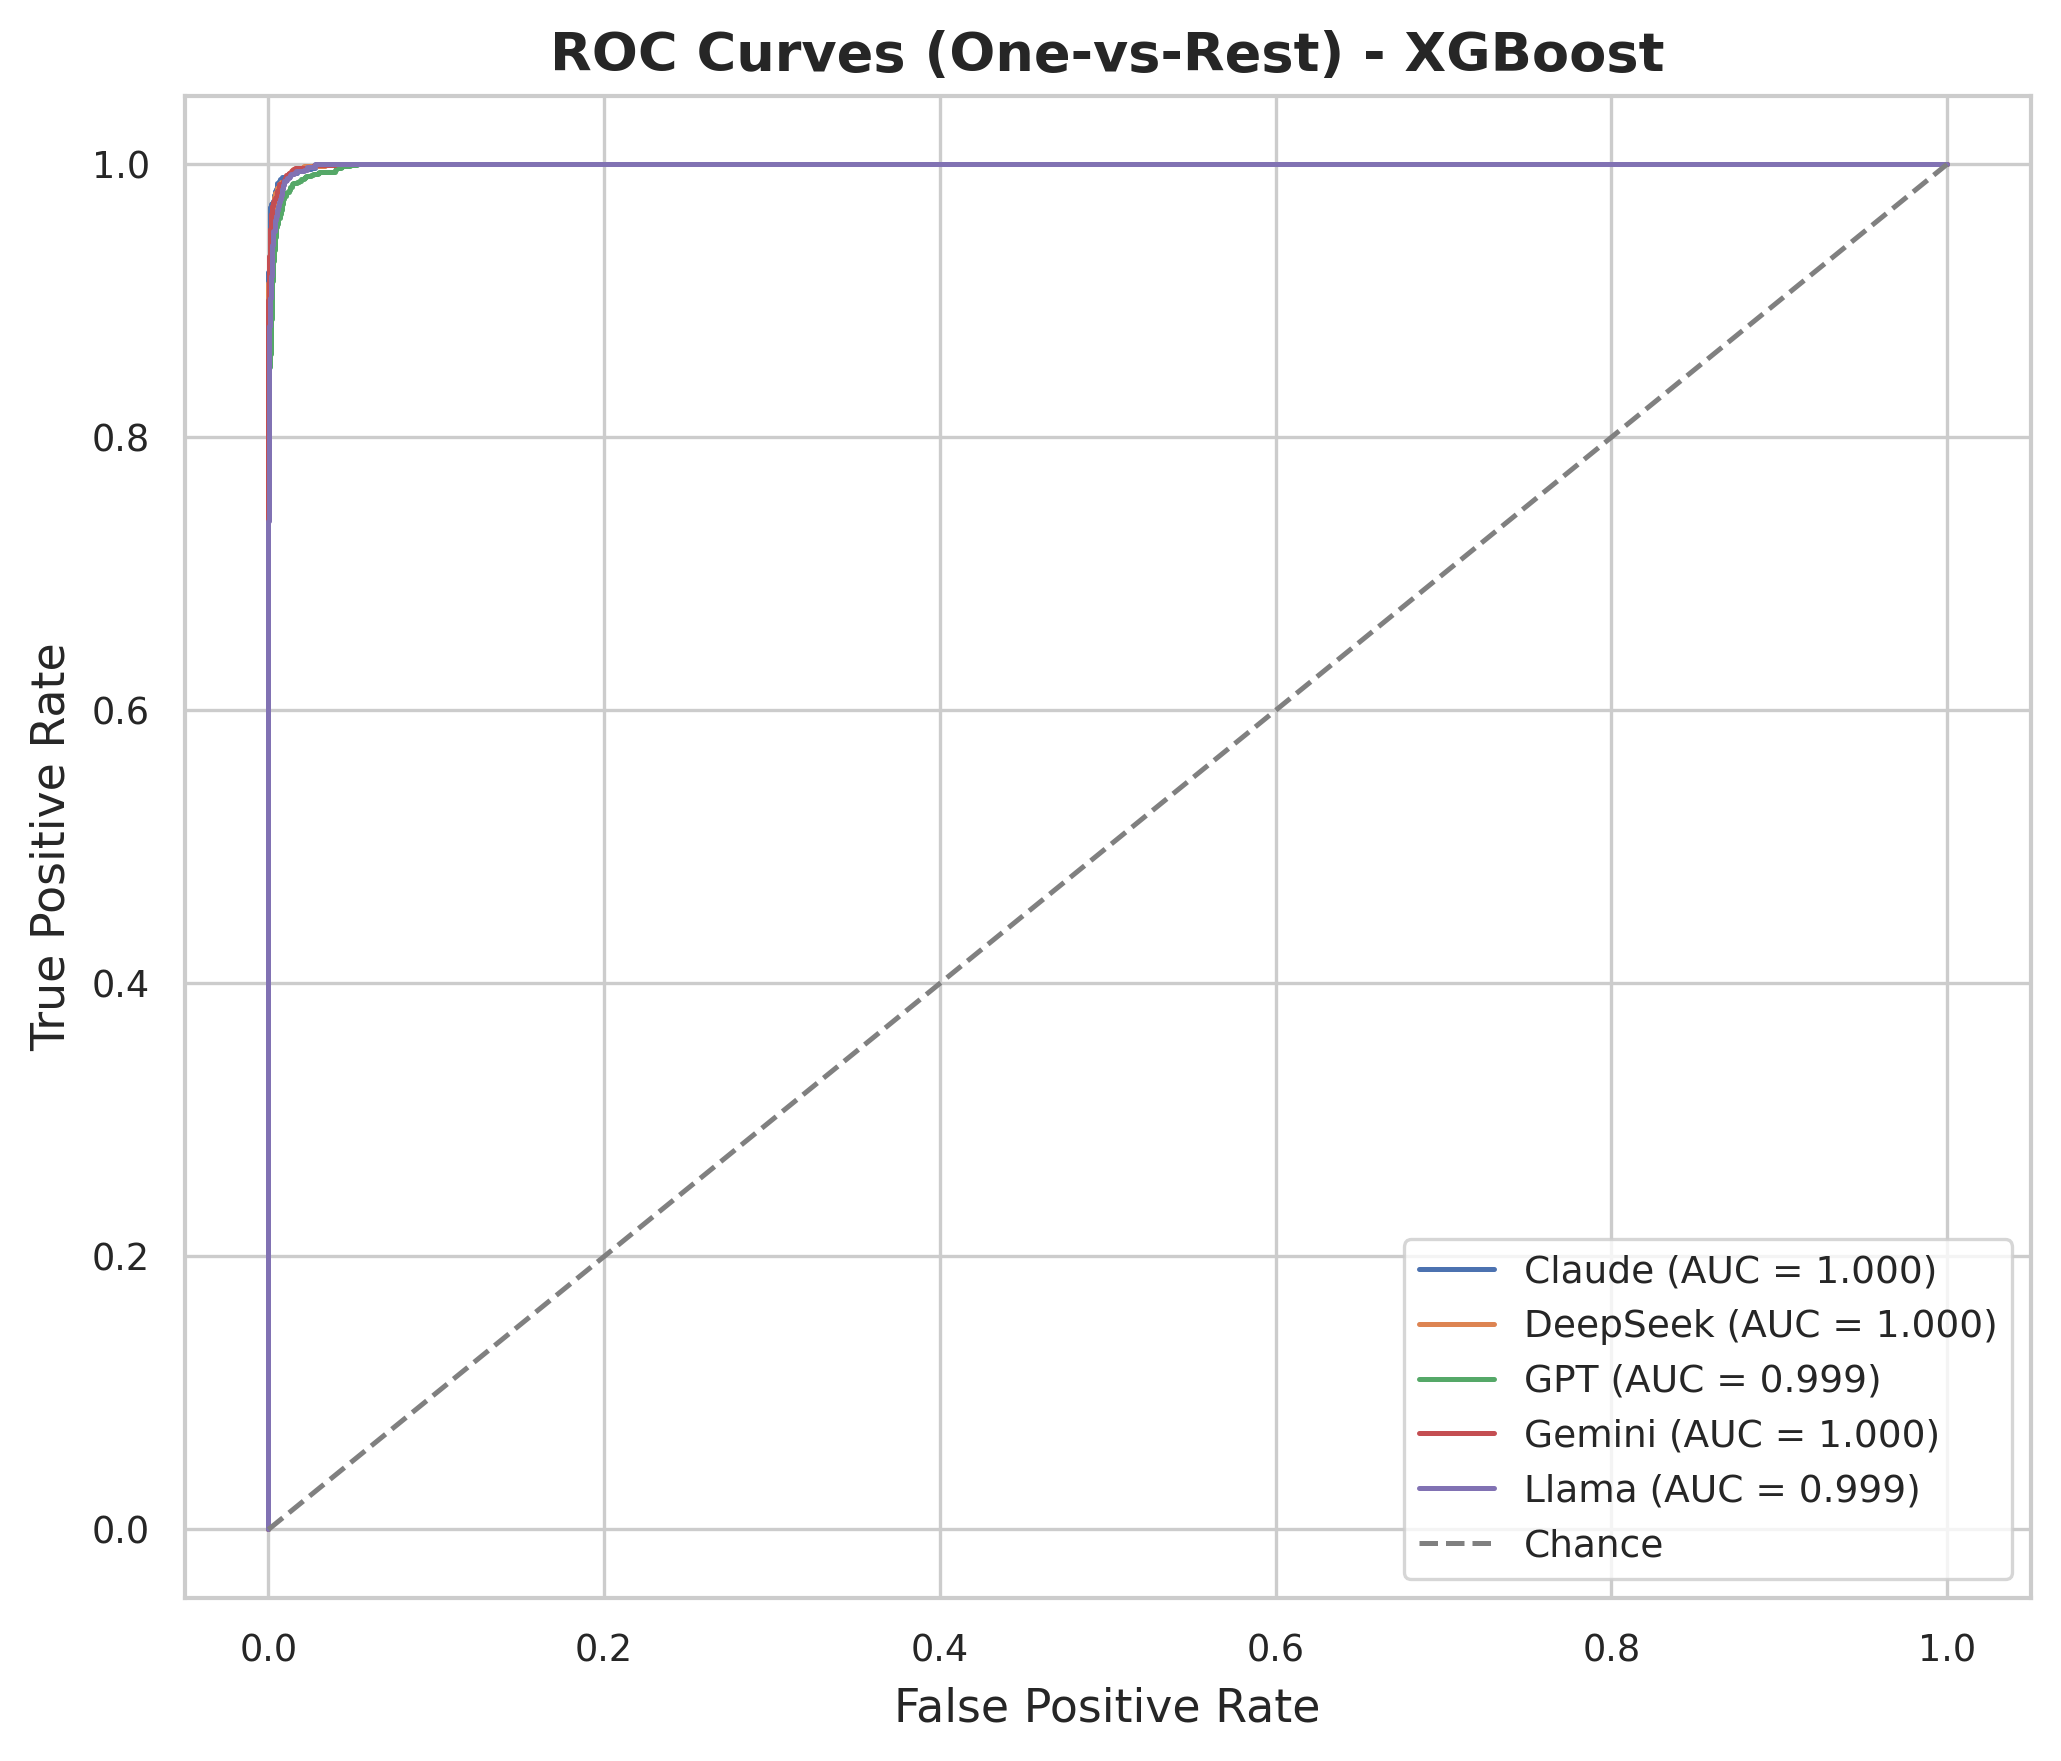

In [31]:
# ---------------------------------------------------------------
# 10.4 ROC curves (multi-class, one-vs-rest) for the best model
# ---------------------------------------------------------------
best_model_name_preview = metrics_df.iloc[0]["Model"]
best_model_preview = trained_models[best_model_name_preview]

if hasattr(best_model_preview, "predict_proba"):
    y_test_bin = label_binarize(y_test, classes=range(n_classes))
    y_score = best_model_preview.predict_proba(X_test)

    fig, ax = plt.subplots(figsize=(7, 6))
    for i, class_name in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{class_name} (AUC = {roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
    ax.set_title(f"ROC Curves (One-vs-Rest) - {best_model_name_preview}")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend(loc="lower right")
    save_figure(fig, "11_roc_curves_best_model")
    plt.show()
else:
    print(f"{best_model_name_preview} does not support predict_proba; ROC curve skipped.")


In [32]:
# ---------------------------------------------------------------
# 10.5 Cross-validation scores for every model
# ---------------------------------------------------------------
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}

for name, model in trained_models.items():
    scores = cross_val_score(model, X, y, cv=cv_strategy, scoring="f1_weighted", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name}: CV F1 (mean ± std) = {scores.mean():.4f} ± {scores.std():.4f}")

cv_df = pd.DataFrame({name: scores for name, scores in cv_results.items()})


Decision Tree: CV F1 (mean ± std) = 0.9222 ± 0.0032
Random Forest: CV F1 (mean ± std) = 0.9191 ± 0.0015
XGBoost: CV F1 (mean ± std) = 0.9743 ± 0.0011
LightGBM: CV F1 (mean ± std) = 0.9688 ± 0.0010
CatBoost: CV F1 (mean ± std) = 0.9681 ± 0.0011
Gradient Boosting: CV F1 (mean ± std) = 0.9679 ± 0.0020
Logistic Regression: CV F1 (mean ± std) = 0.9381 ± 0.0060
Extra Trees: CV F1 (mean ± std) = 0.8732 ± 0.0038


Saved figure: /content/thesis_outputs/figures/12_cross_validation_boxplot.png


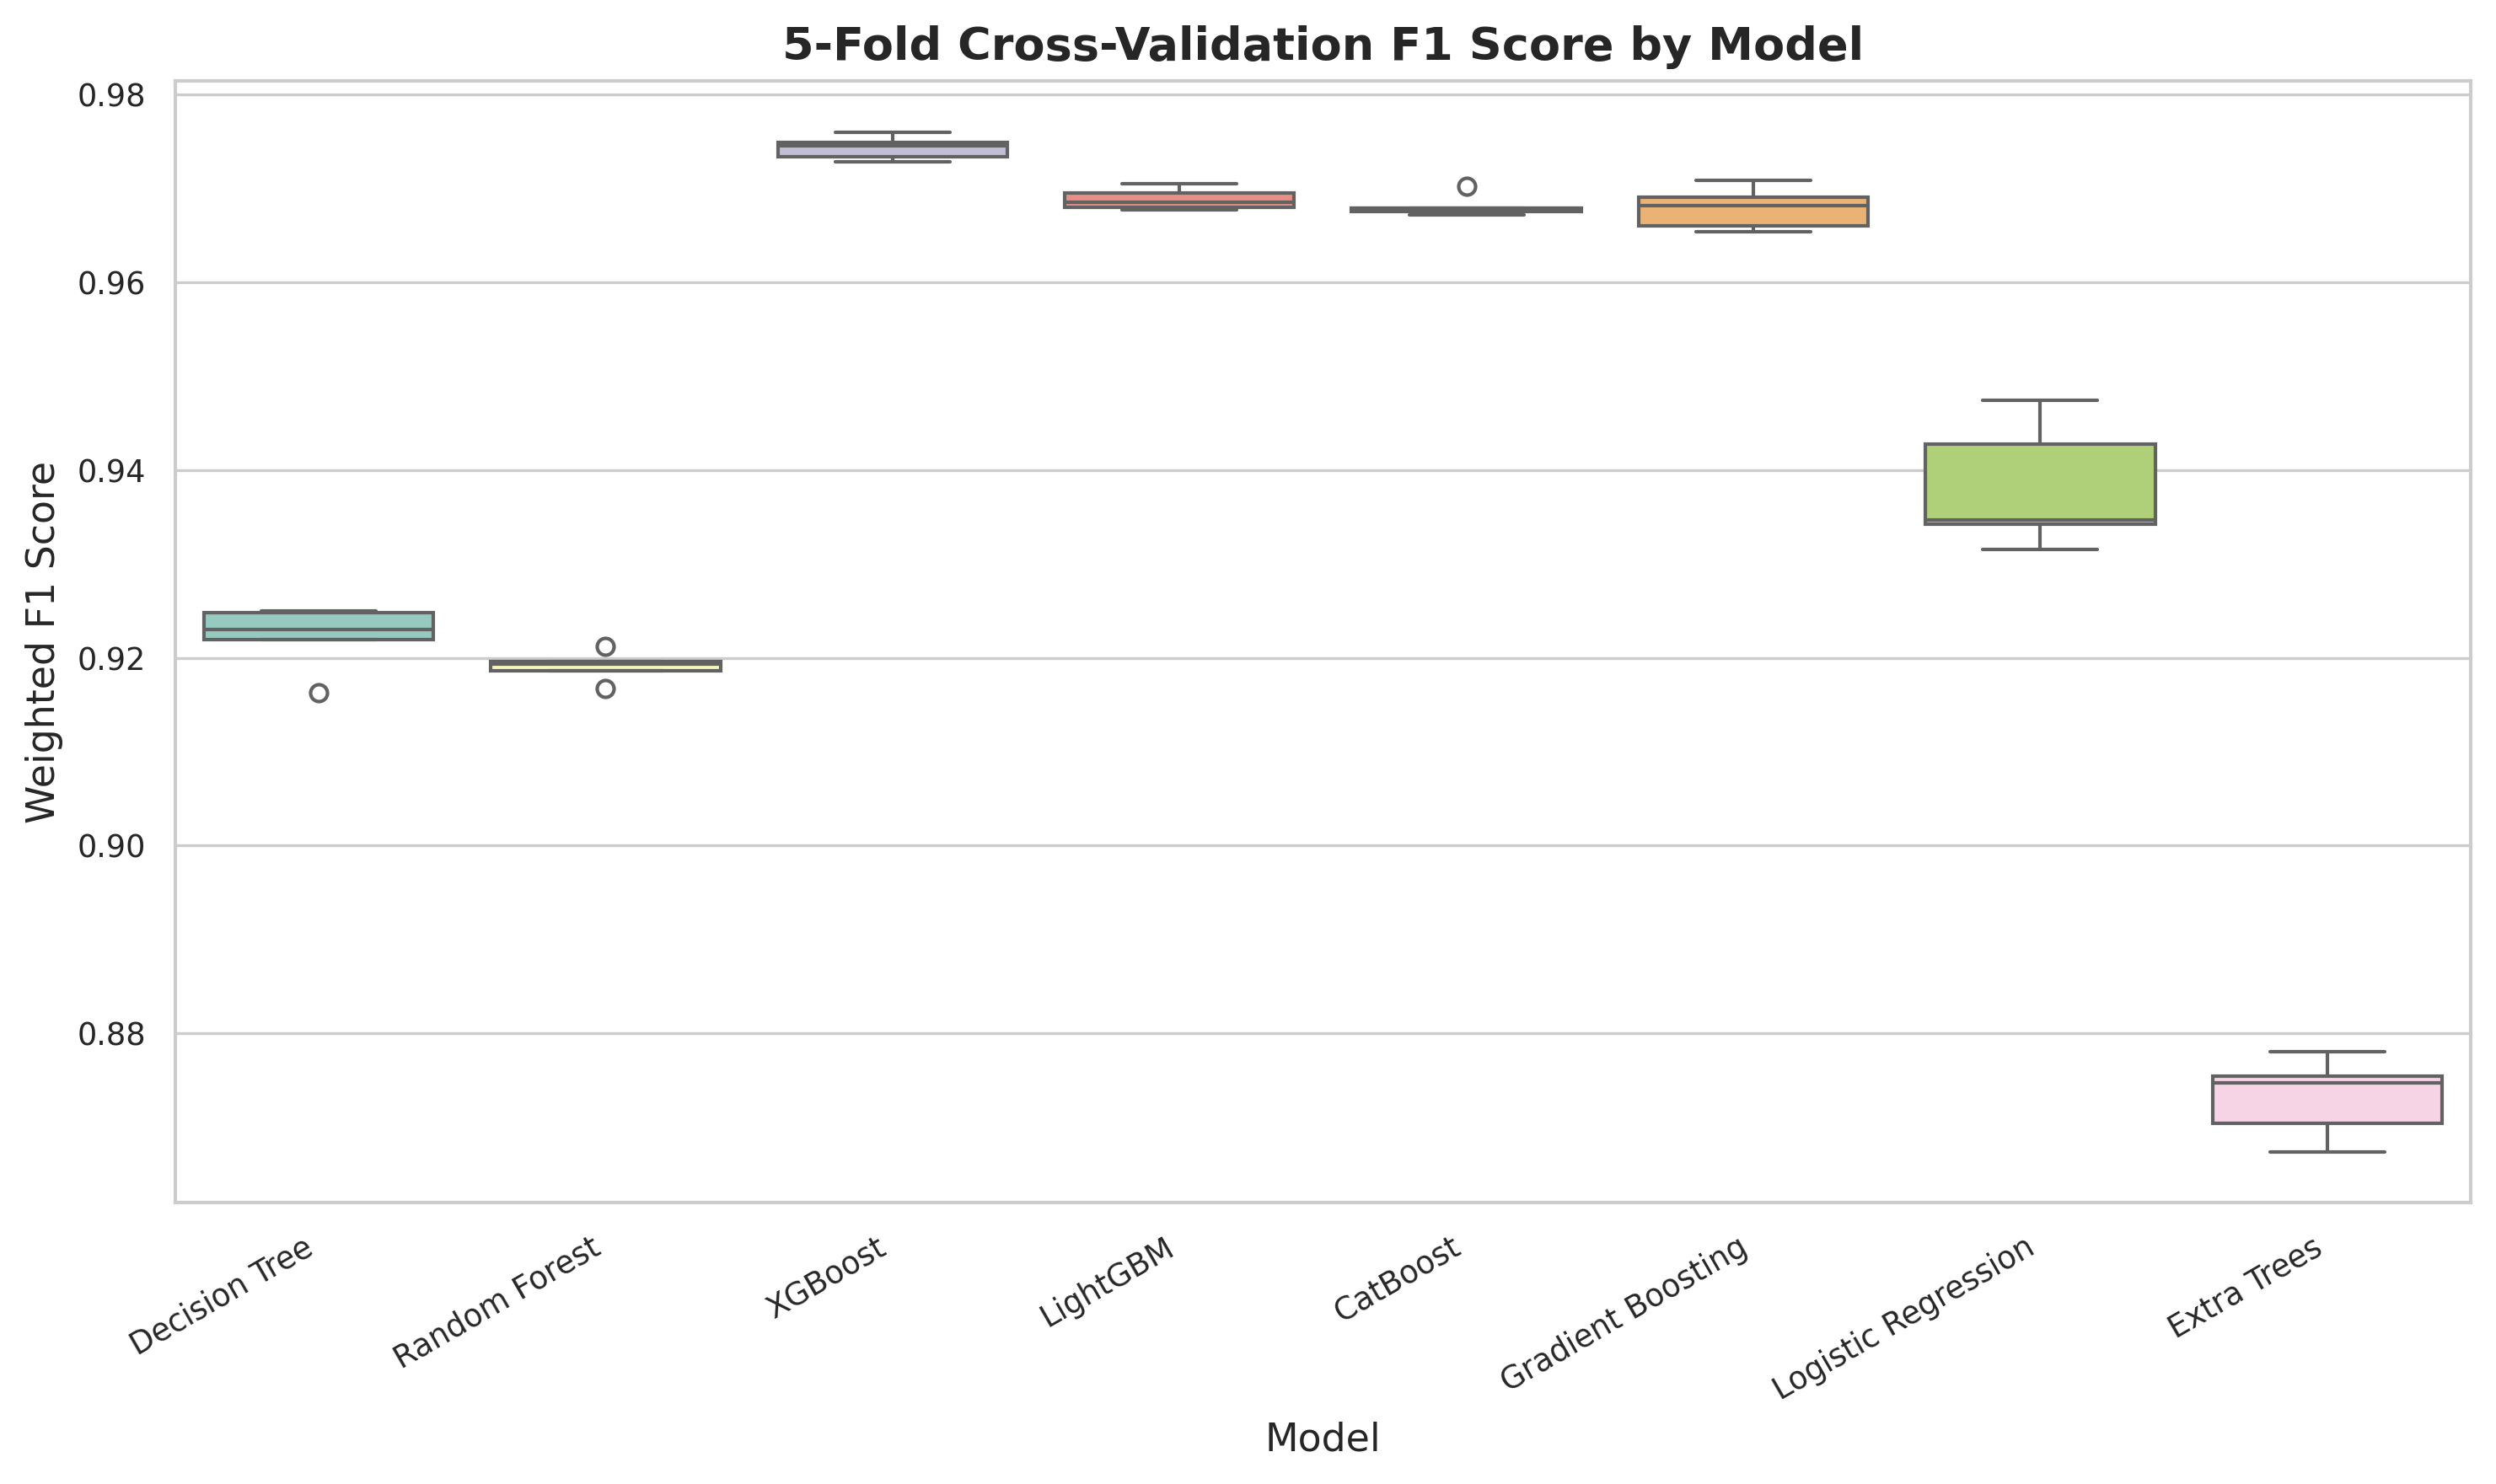

In [33]:
# ---------------------------------------------------------------
# 10.6 Cross-validation boxplot
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=cv_df, palette="Set3", ax=ax)
ax.set_title("5-Fold Cross-Validation F1 Score by Model")
ax.set_xlabel("Model")
ax.set_ylabel("Weighted F1 Score")
plt.xticks(rotation=30, ha="right")
save_figure(fig, "12_cross_validation_boxplot")
plt.show()


## 11. Model Comparison
Comparison table, bar chart, and automatic selection of the best model.

In [34]:
# ---------------------------------------------------------------
# 11.1 Comparison table (including CV mean F1)
# ---------------------------------------------------------------
metrics_df["CV F1 Mean"] = metrics_df["Model"].map(lambda n: cv_results[n].mean())
metrics_df["CV F1 Std"] = metrics_df["Model"].map(lambda n: cv_results[n].std())
metrics_df["Training Time (s)"] = metrics_df["Model"].map(training_times)
metrics_df = metrics_df.sort_values("F1 Score", ascending=False).reset_index(drop=True)

metrics_df.to_csv(os.path.join(TABLES_DIR, "model_comparison.csv"), index=False)
display(metrics_df)


,Model,Accuracy,Precision,Recall,F1 Score,CV F1 Mean,CV F1 Std,Training Time (s)
0,XGBoost,0.977000,0.977039,0.977000,0.977009,0.974310,0.001121,15.821665
1,CatBoost,0.970333,0.970449,0.970333,0.970345,0.968118,0.001068,15.016058
2,LightGBM,0.970333,0.970360,0.970333,0.970334,0.968841,0.001037,11.360291
3,Gradient Boosting,0.968333,0.968335,0.968333,0.968313,0.967871,0.002002,184.846382
4,Logistic Regression,0.935000,0.936659,0.935000,0.934840,0.938098,0.005964,83.039192
5,Decision Tree,0.925667,0.925724,0.925667,0.925666,0.922215,0.003160,0.875314
6,Random Forest,0.921000,0.927242,0.921000,0.920915,0.919095,0.001455,33.796241
7,Extra Trees,0.876000,0.896781,0.876000,0.875298,0.873236,0.003819,15.686561


Saved figure: /content/thesis_outputs/figures/13_model_comparison_bar_chart.png


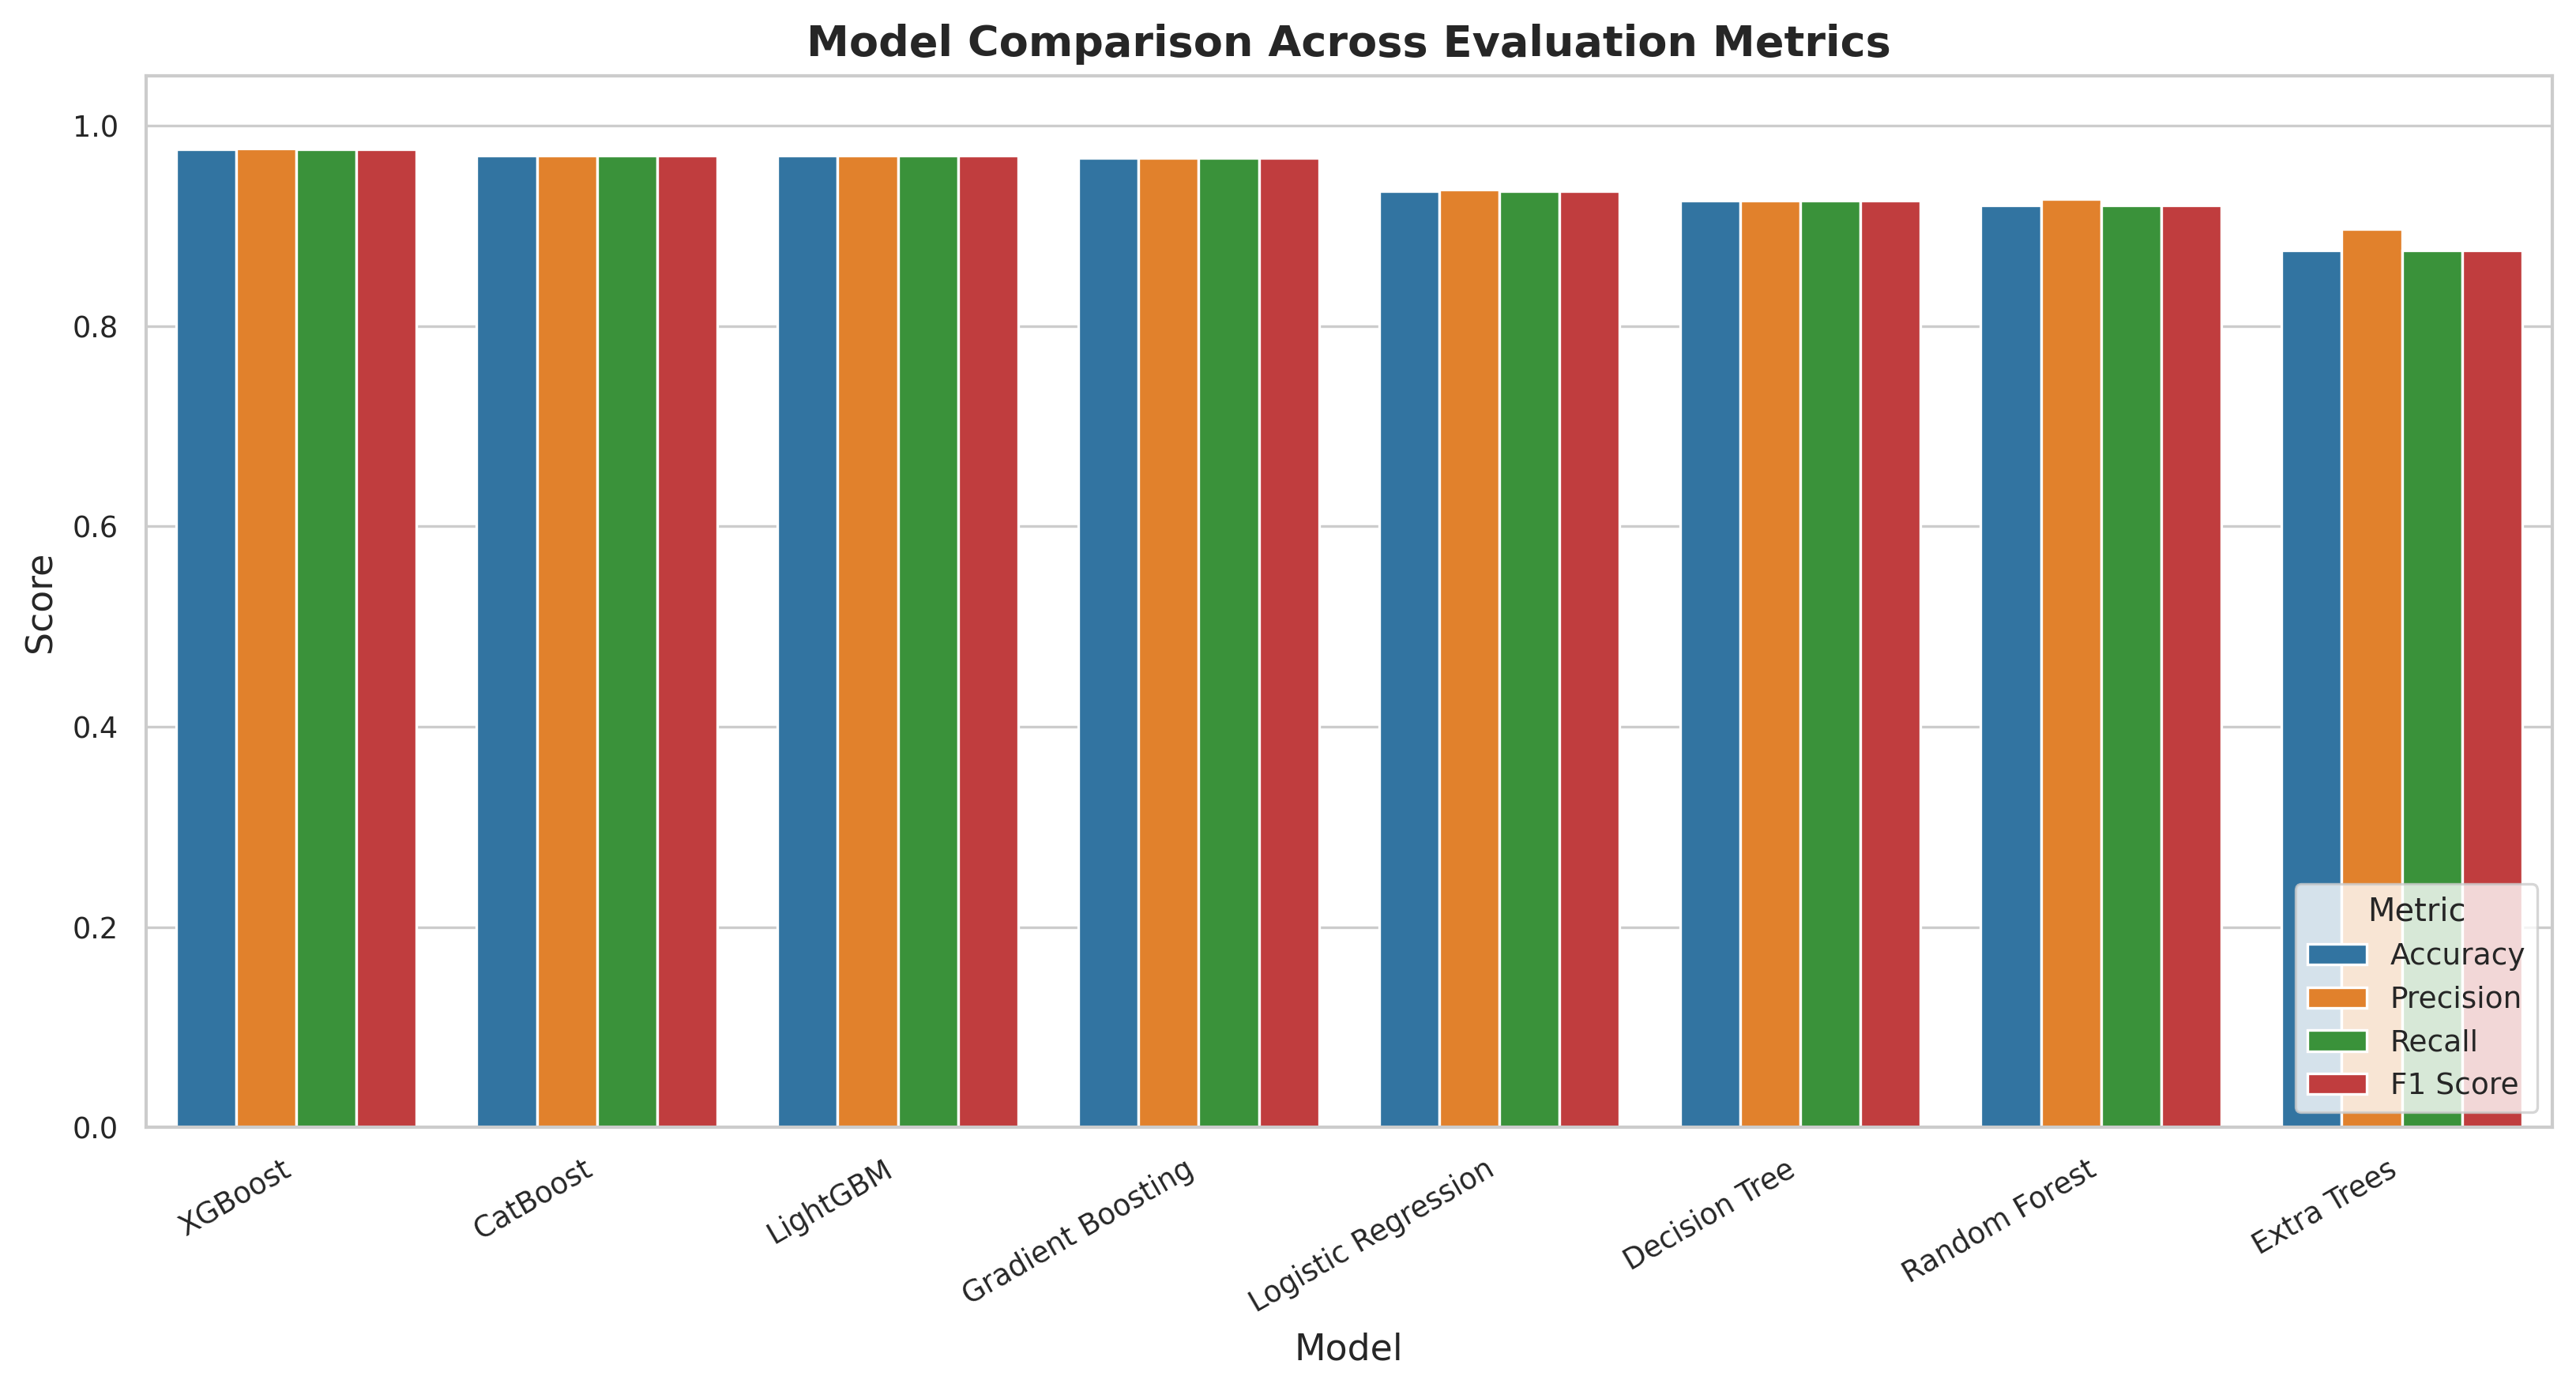

In [35]:
# ---------------------------------------------------------------
# 11.2 Comparison bar chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6))
plot_df = metrics_df.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
                           var_name="Metric", value_name="Score")
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="tab10", ax=ax)
ax.set_title("Model Comparison Across Evaluation Metrics")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=30, ha="right")
ax.legend(title="Metric", loc="lower right")
save_figure(fig, "13_model_comparison_bar_chart")
plt.show()


In [36]:
# ---------------------------------------------------------------
# 11.3 Automatically select the best model (highest F1 Score)
# ---------------------------------------------------------------
BEST_MODEL_NAME = metrics_df.iloc[0]["Model"]
best_model = trained_models[BEST_MODEL_NAME]
best_model_predictions = predictions_by_model[BEST_MODEL_NAME]

print(f"Automatically selected BEST MODEL: {BEST_MODEL_NAME}")
print(f"  Accuracy : {metrics_df.iloc[0]['Accuracy']:.4f}")
print(f"  F1 Score : {metrics_df.iloc[0]['F1 Score']:.4f}")


Automatically selected BEST MODEL: XGBoost
  Accuracy : 0.9770
  F1 Score : 0.9770


## 12. Feature Importance
Model-native feature importance and SHAP explanations for the best model.

Saved figure: /content/thesis_outputs/figures/14_feature_importance.png


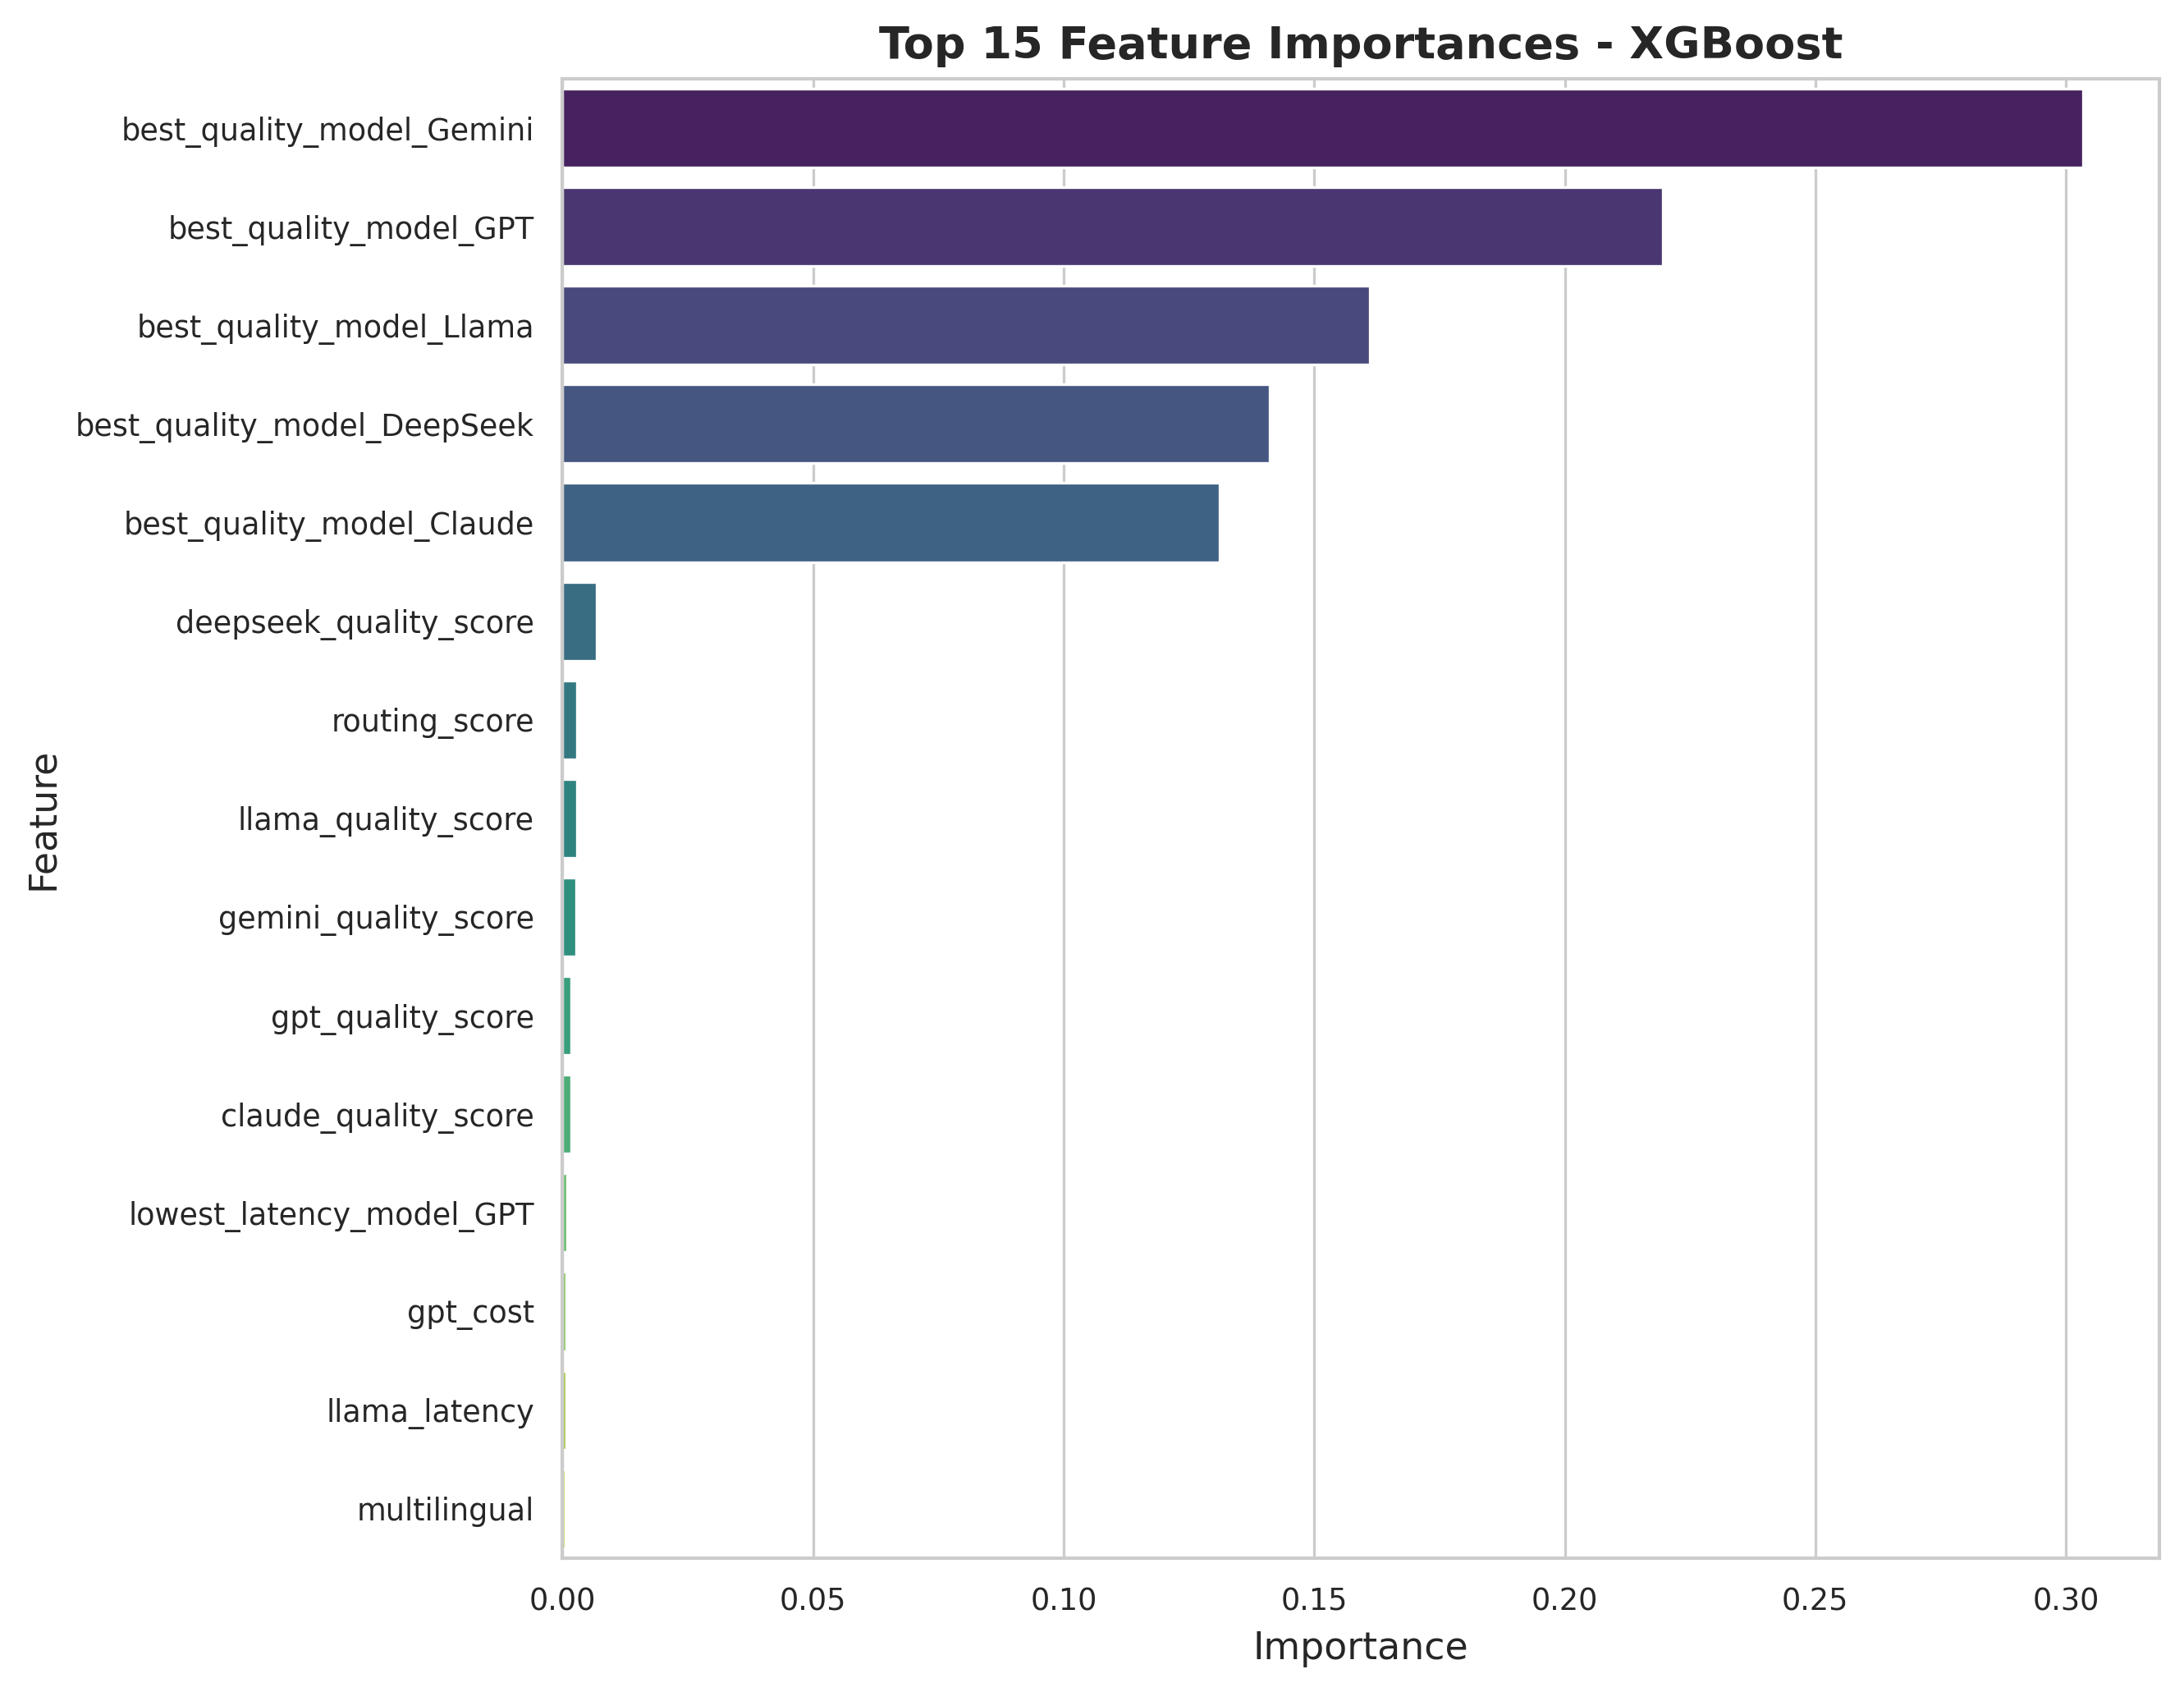

In [37]:
# ---------------------------------------------------------------
# 12.1 Native feature importance (if available)
# ---------------------------------------------------------------
if hasattr(best_model, "feature_importances_"):
    importance_df = pd.DataFrame({
        "Feature": FEATURE_NAMES,
        "Importance": best_model.feature_importances_,
    }).sort_values("Importance", ascending=False).reset_index(drop=True)

    importance_df.to_csv(os.path.join(TABLES_DIR, "feature_importance.csv"), index=False)

    top_n = min(15, len(importance_df))
    fig, ax = plt.subplots(figsize=(9, 7))
    sns.barplot(data=importance_df.head(top_n), x="Importance", y="Feature", palette="viridis", ax=ax)
    ax.set_title(f"Top {top_n} Feature Importances - {BEST_MODEL_NAME}")
    ax.set_xlabel("Importance")
    ax.set_ylabel("Feature")
    save_figure(fig, "14_feature_importance")
    plt.show()
else:
    print(f"{BEST_MODEL_NAME} has no native feature_importances_ attribute.")
    importance_df = pd.DataFrame({"Feature": FEATURE_NAMES, "Importance": np.nan})
    importance_df.to_csv(os.path.join(TABLES_DIR, "feature_importance.csv"), index=False)


Saved figure: /content/thesis_outputs/figures/15_shap_summary.png


<Figure size 3000x2100 with 0 Axes>

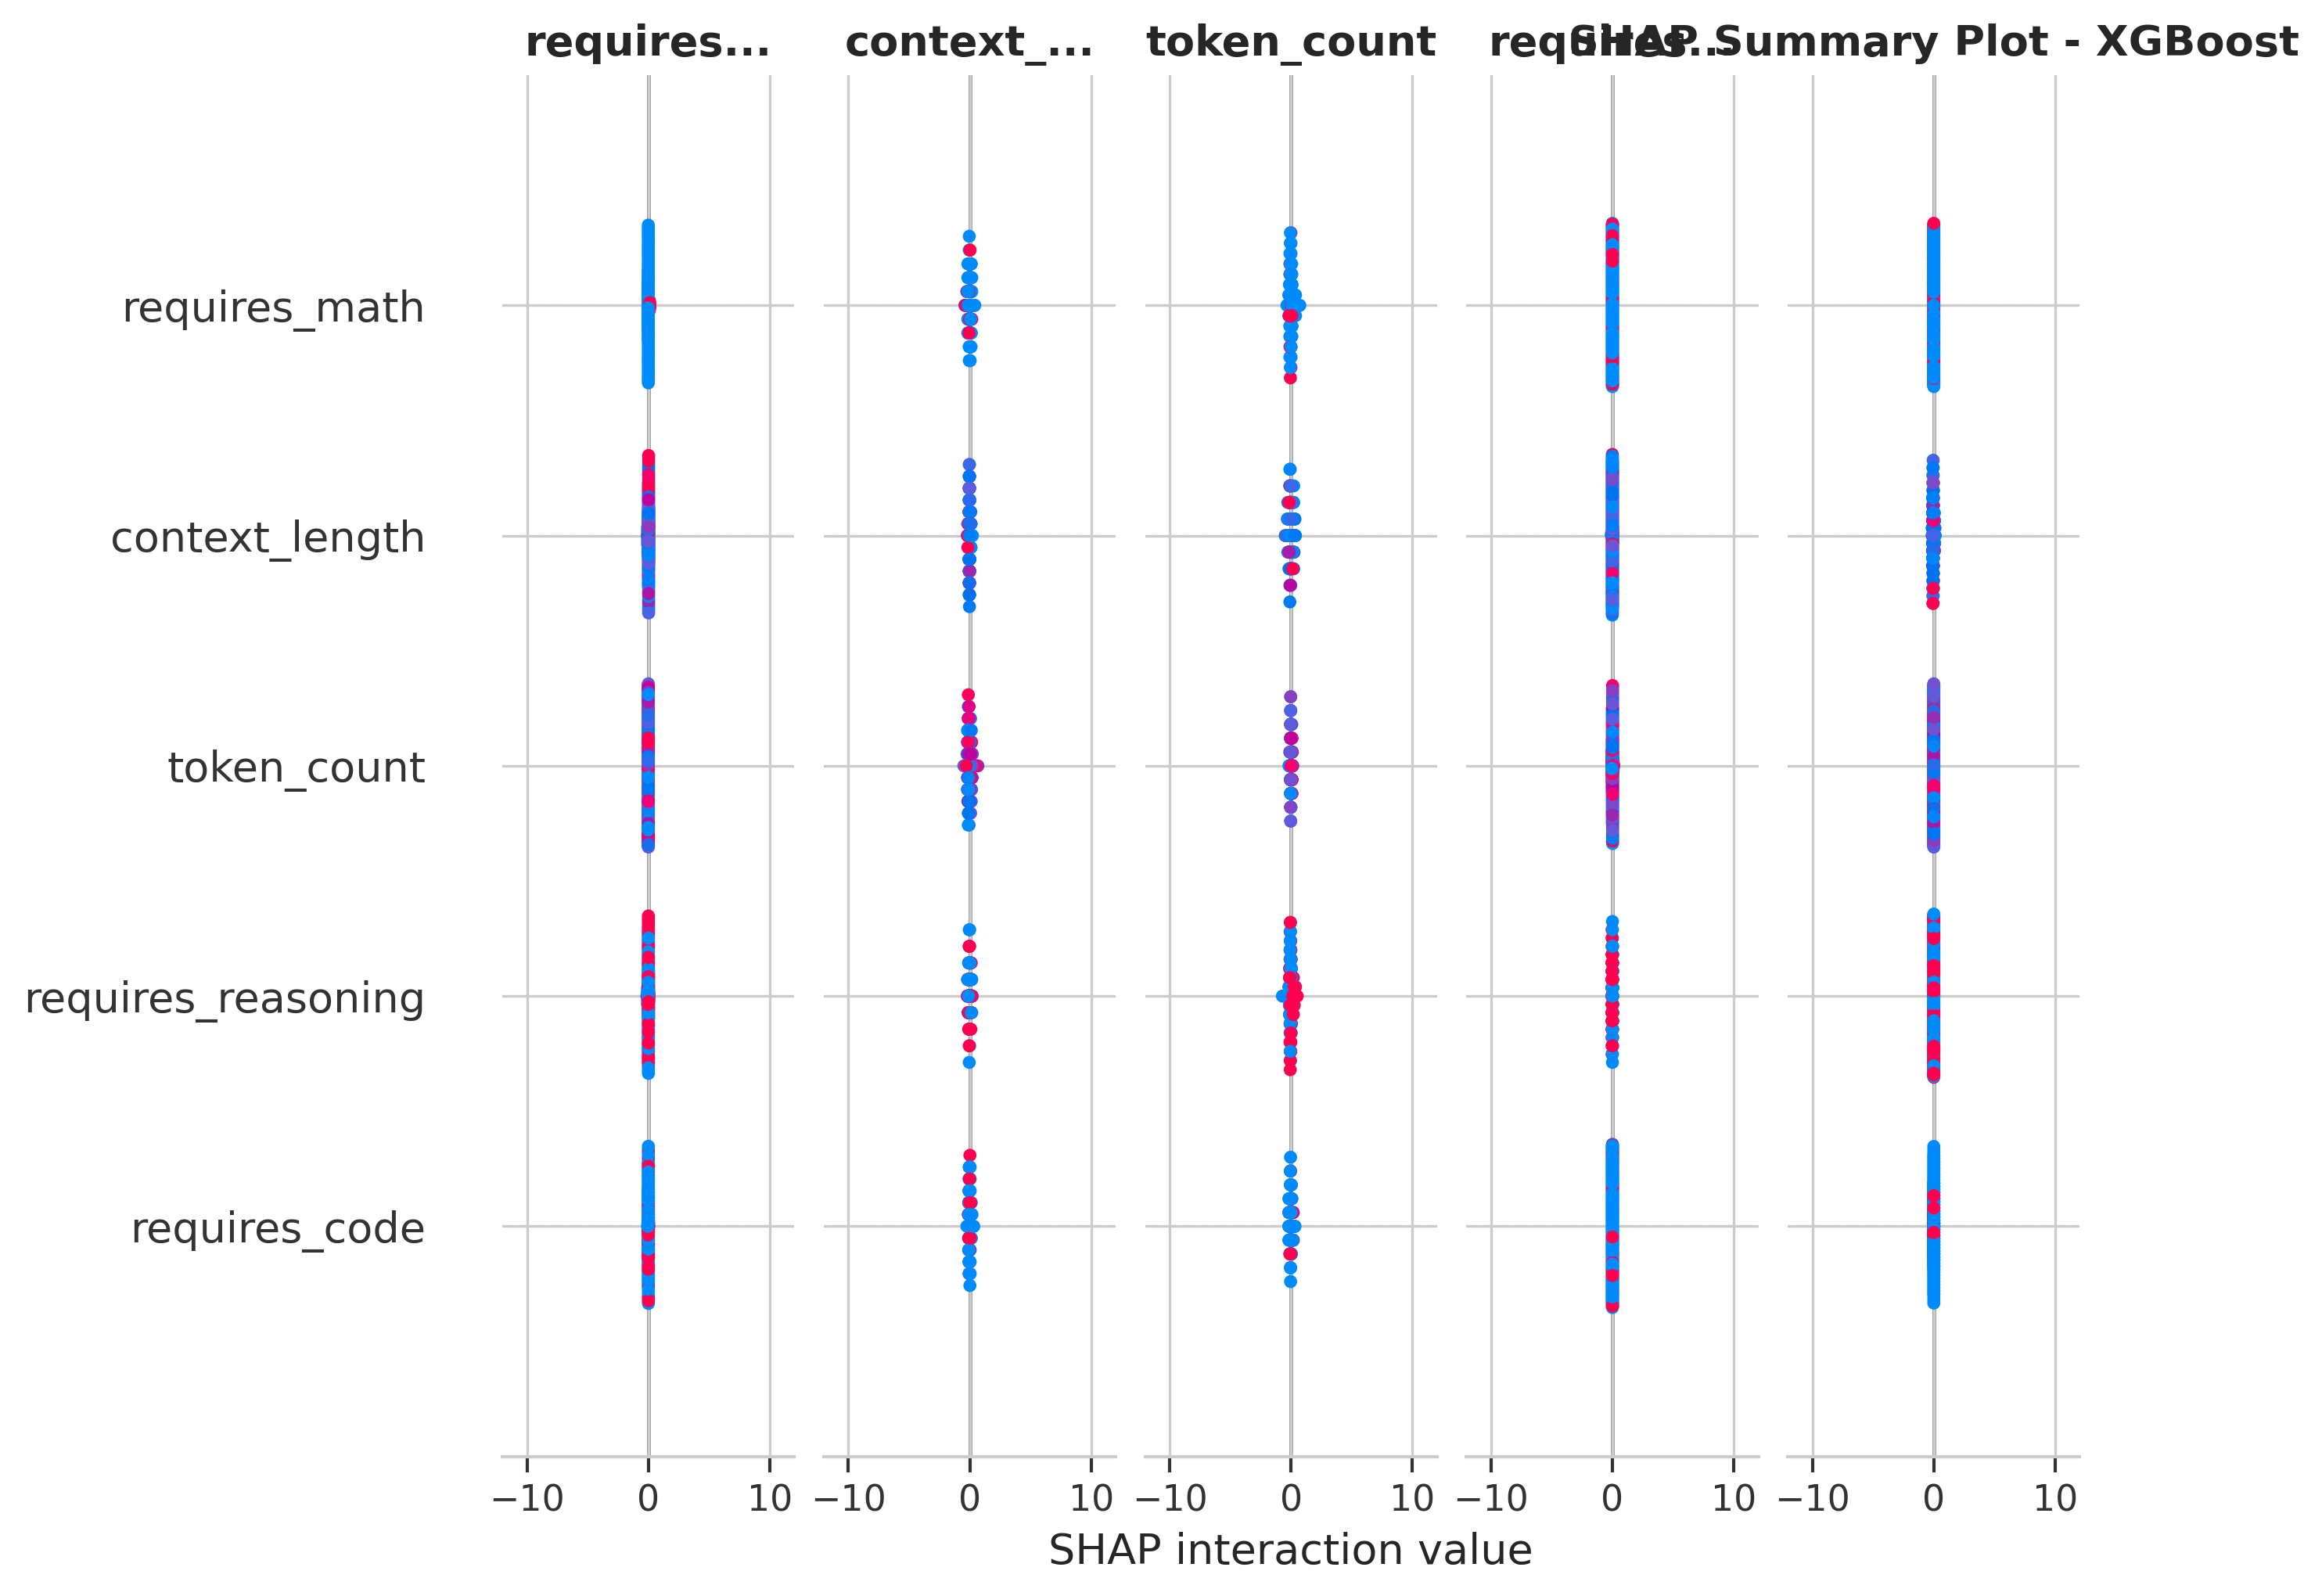

In [38]:
# ---------------------------------------------------------------
# 12.2 SHAP explanation for the best model
# ---------------------------------------------------------------
try:
    # Use a manageable background/explain sample for speed
    sample_size = min(200, len(X_test))
    X_sample = X_test.sample(n=sample_size, random_state=RANDOM_STATE)

    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_sample)

    fig = plt.figure(figsize=(10, 7))
    # For multi-class output, shap_values is a list; summarize across classes
    if isinstance(shap_values, list):
        shap.summary_plot(shap_values, X_sample, class_names=CLASS_NAMES, show=False)
    else:
        shap.summary_plot(shap_values, X_sample, show=False)
    plt.title(f"SHAP Summary Plot - {BEST_MODEL_NAME}")
    save_figure(fig, "15_shap_summary")
    plt.show()
except Exception as e:
    print(f"SHAP explanation skipped for {BEST_MODEL_NAME} (non tree-based or incompatible): {e}")


## 13. Cost-Aware Routing Simulation
The most important section: simulate the financial impact of intelligent routing versus always using the largest model.

In [41]:
# ---------------------------------------------------------------
# 13.1 Define the three simulated LLM tiers and their cost per 1K tokens
# ---------------------------------------------------------------
COST_PER_1K_TOKENS = {
    "Small Model": 0.002,
    "Medium Model": 0.010,
    "Large Model": 0.030,
}

# ---------------------------------------------------------------
# 13.2 Map dataset's preferred_model labels onto the three simulated tiers
# ---------------------------------------------------------------
# The dataset's own class names are treated as canonical tier labels when
# they already match; otherwise they are mapped heuristically by keyword.
def map_to_tier(label):
    label_lower = str(label).lower()
    if "small" in label_lower or "mini" in label_lower or "light" in label_lower:
        return "Small Model"
    if "medium" in label_lower or "mid" in label_lower:
        return "Medium Model"
    if "large" in label_lower or "big" in label_lower or "max" in label_lower:
        return "Large Model"
    # Fallback: assign tiers by rank order of unique classes (small -> large)
    unique_sorted = sorted(CLASS_NAMES)
    rank = unique_sorted.index(label) if label in unique_sorted else 0
    tiers = ["Small Model", "Medium Model", "Large Model"]
    return tiers[min(rank, len(tiers) - 1)]

tier_lookup = {cls: map_to_tier(cls) for cls in CLASS_NAMES}
print("Preferred model -> simulated tier mapping:")
for k, v in tier_lookup.items():
    print(f"  {k:<20s} -> {v}")

# ---------------------------------------------------------------
# 13.3 Build the routing simulation dataframe for the test set
# ---------------------------------------------------------------
sim_df = pd.DataFrame({
    "estimated_tokens": df.loc[idx_test, "token_count"].values,
    "actual_label": target_encoder.inverse_transform(y_test),
    "predicted_label": target_encoder.inverse_transform(best_model_predictions),
})
sim_df["actual_tier"] = sim_df["actual_label"].map(tier_lookup)
sim_df["predicted_tier"] = sim_df["predicted_label"].map(tier_lookup)

# ---------------------------------------------------------------
# 13.4 Cost calculation
# ---------------------------------------------------------------
def compute_cost(tokens, tier):
    return (tokens / 1000.0) * COST_PER_1K_TOKENS[tier]

# Baseline: every query is routed to the Large Model
sim_df["baseline_tier"] = "Large Model"
sim_df["baseline_query_cost"] = sim_df.apply(
    lambda row: compute_cost(row["estimated_tokens"], row["baseline_tier"]), axis=1
)

# Router: query is routed based on the MODEL'S PREDICTED preferred model
sim_df["router_query_cost"] = sim_df.apply(
    lambda row: compute_cost(row["estimated_tokens"], row["predicted_tier"]), axis=1
)

baseline_cost = sim_df["baseline_query_cost"].sum()
router_cost = sim_df["router_query_cost"].sum()
saving_percent = ((baseline_cost - router_cost) / baseline_cost) * 100 if baseline_cost > 0 else 0.0

print()
print(f"Baseline Cost: ${baseline_cost:.2f}")
print(f"Router Cost: ${router_cost:.2f}")
print(f"Cost Saving: {saving_percent:.2f}%")

Preferred model -> simulated tier mapping:
  Claude               -> Small Model
  DeepSeek             -> Medium Model
  GPT                  -> Large Model
  Gemini               -> Small Model
  Llama                -> Large Model

Baseline Cost: $86.47
Router Cost: $40.35
Cost Saving: 53.34%


Saved figure: /content/thesis_outputs/figures/16_cost_comparison_bar_chart.png


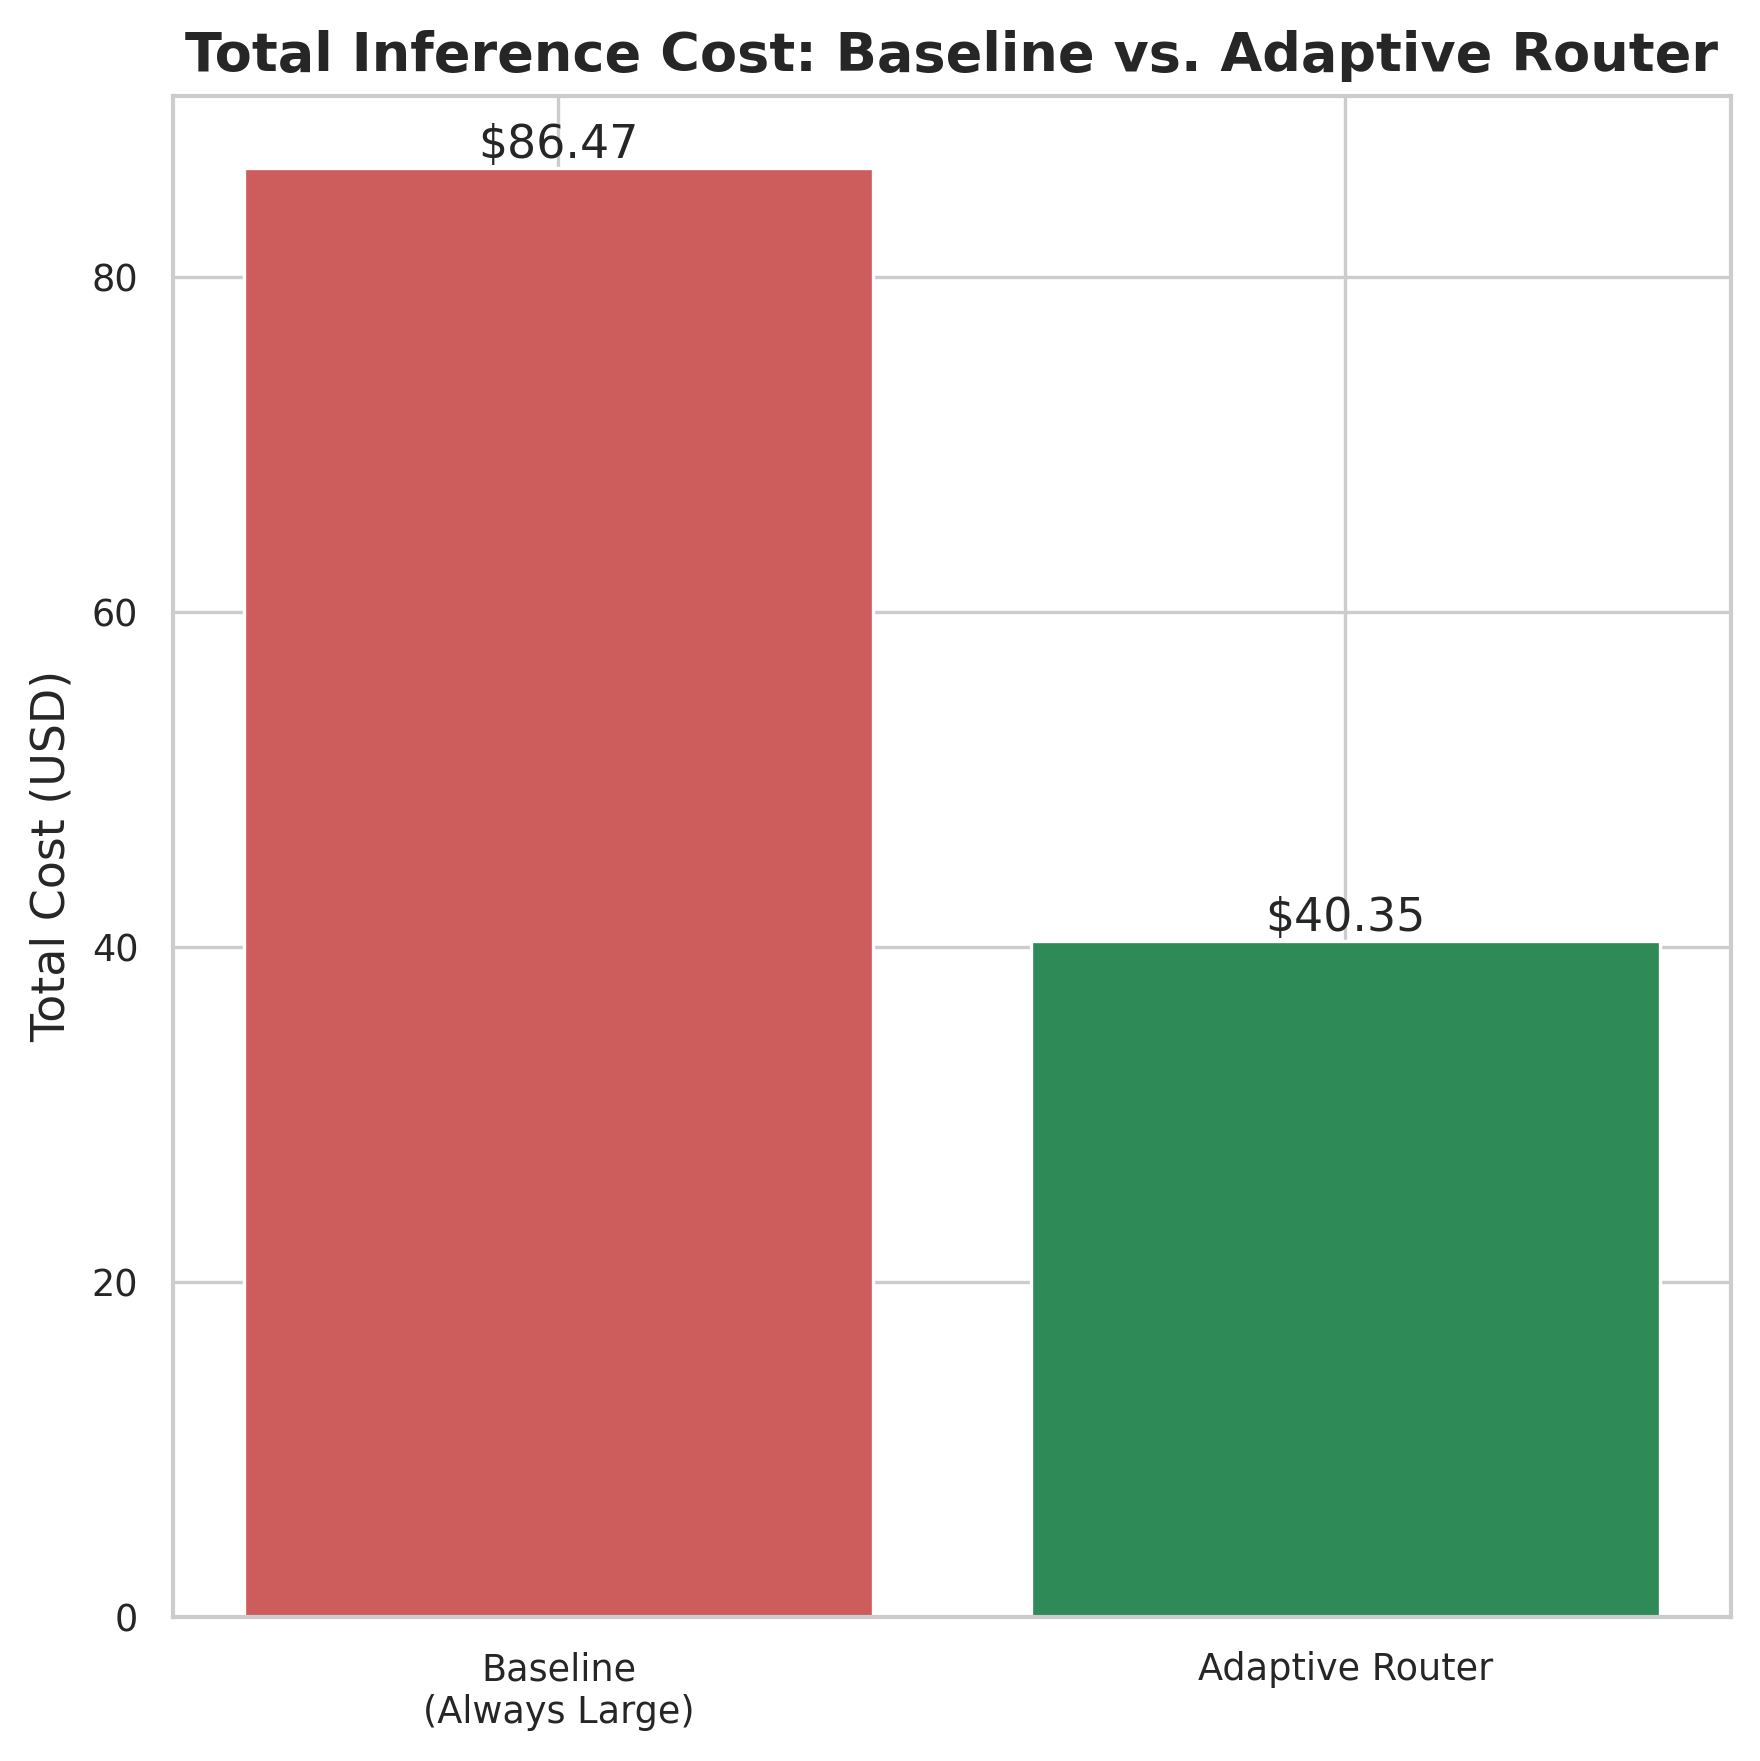

In [42]:
# ---------------------------------------------------------------
# 13.5 Cost comparison bar chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 6))
bars = ax.bar(["Baseline\n(Always Large)", "Adaptive Router"], [baseline_cost, router_cost],
              color=["indianred", "seagreen"])
ax.bar_label(bars, fmt="$%.2f")
ax.set_title("Total Inference Cost: Baseline vs. Adaptive Router")
ax.set_ylabel("Total Cost (USD)")
save_figure(fig, "16_cost_comparison_bar_chart")
plt.show()


Saved figure: /content/thesis_outputs/figures/17_cost_savings_pie_chart.png


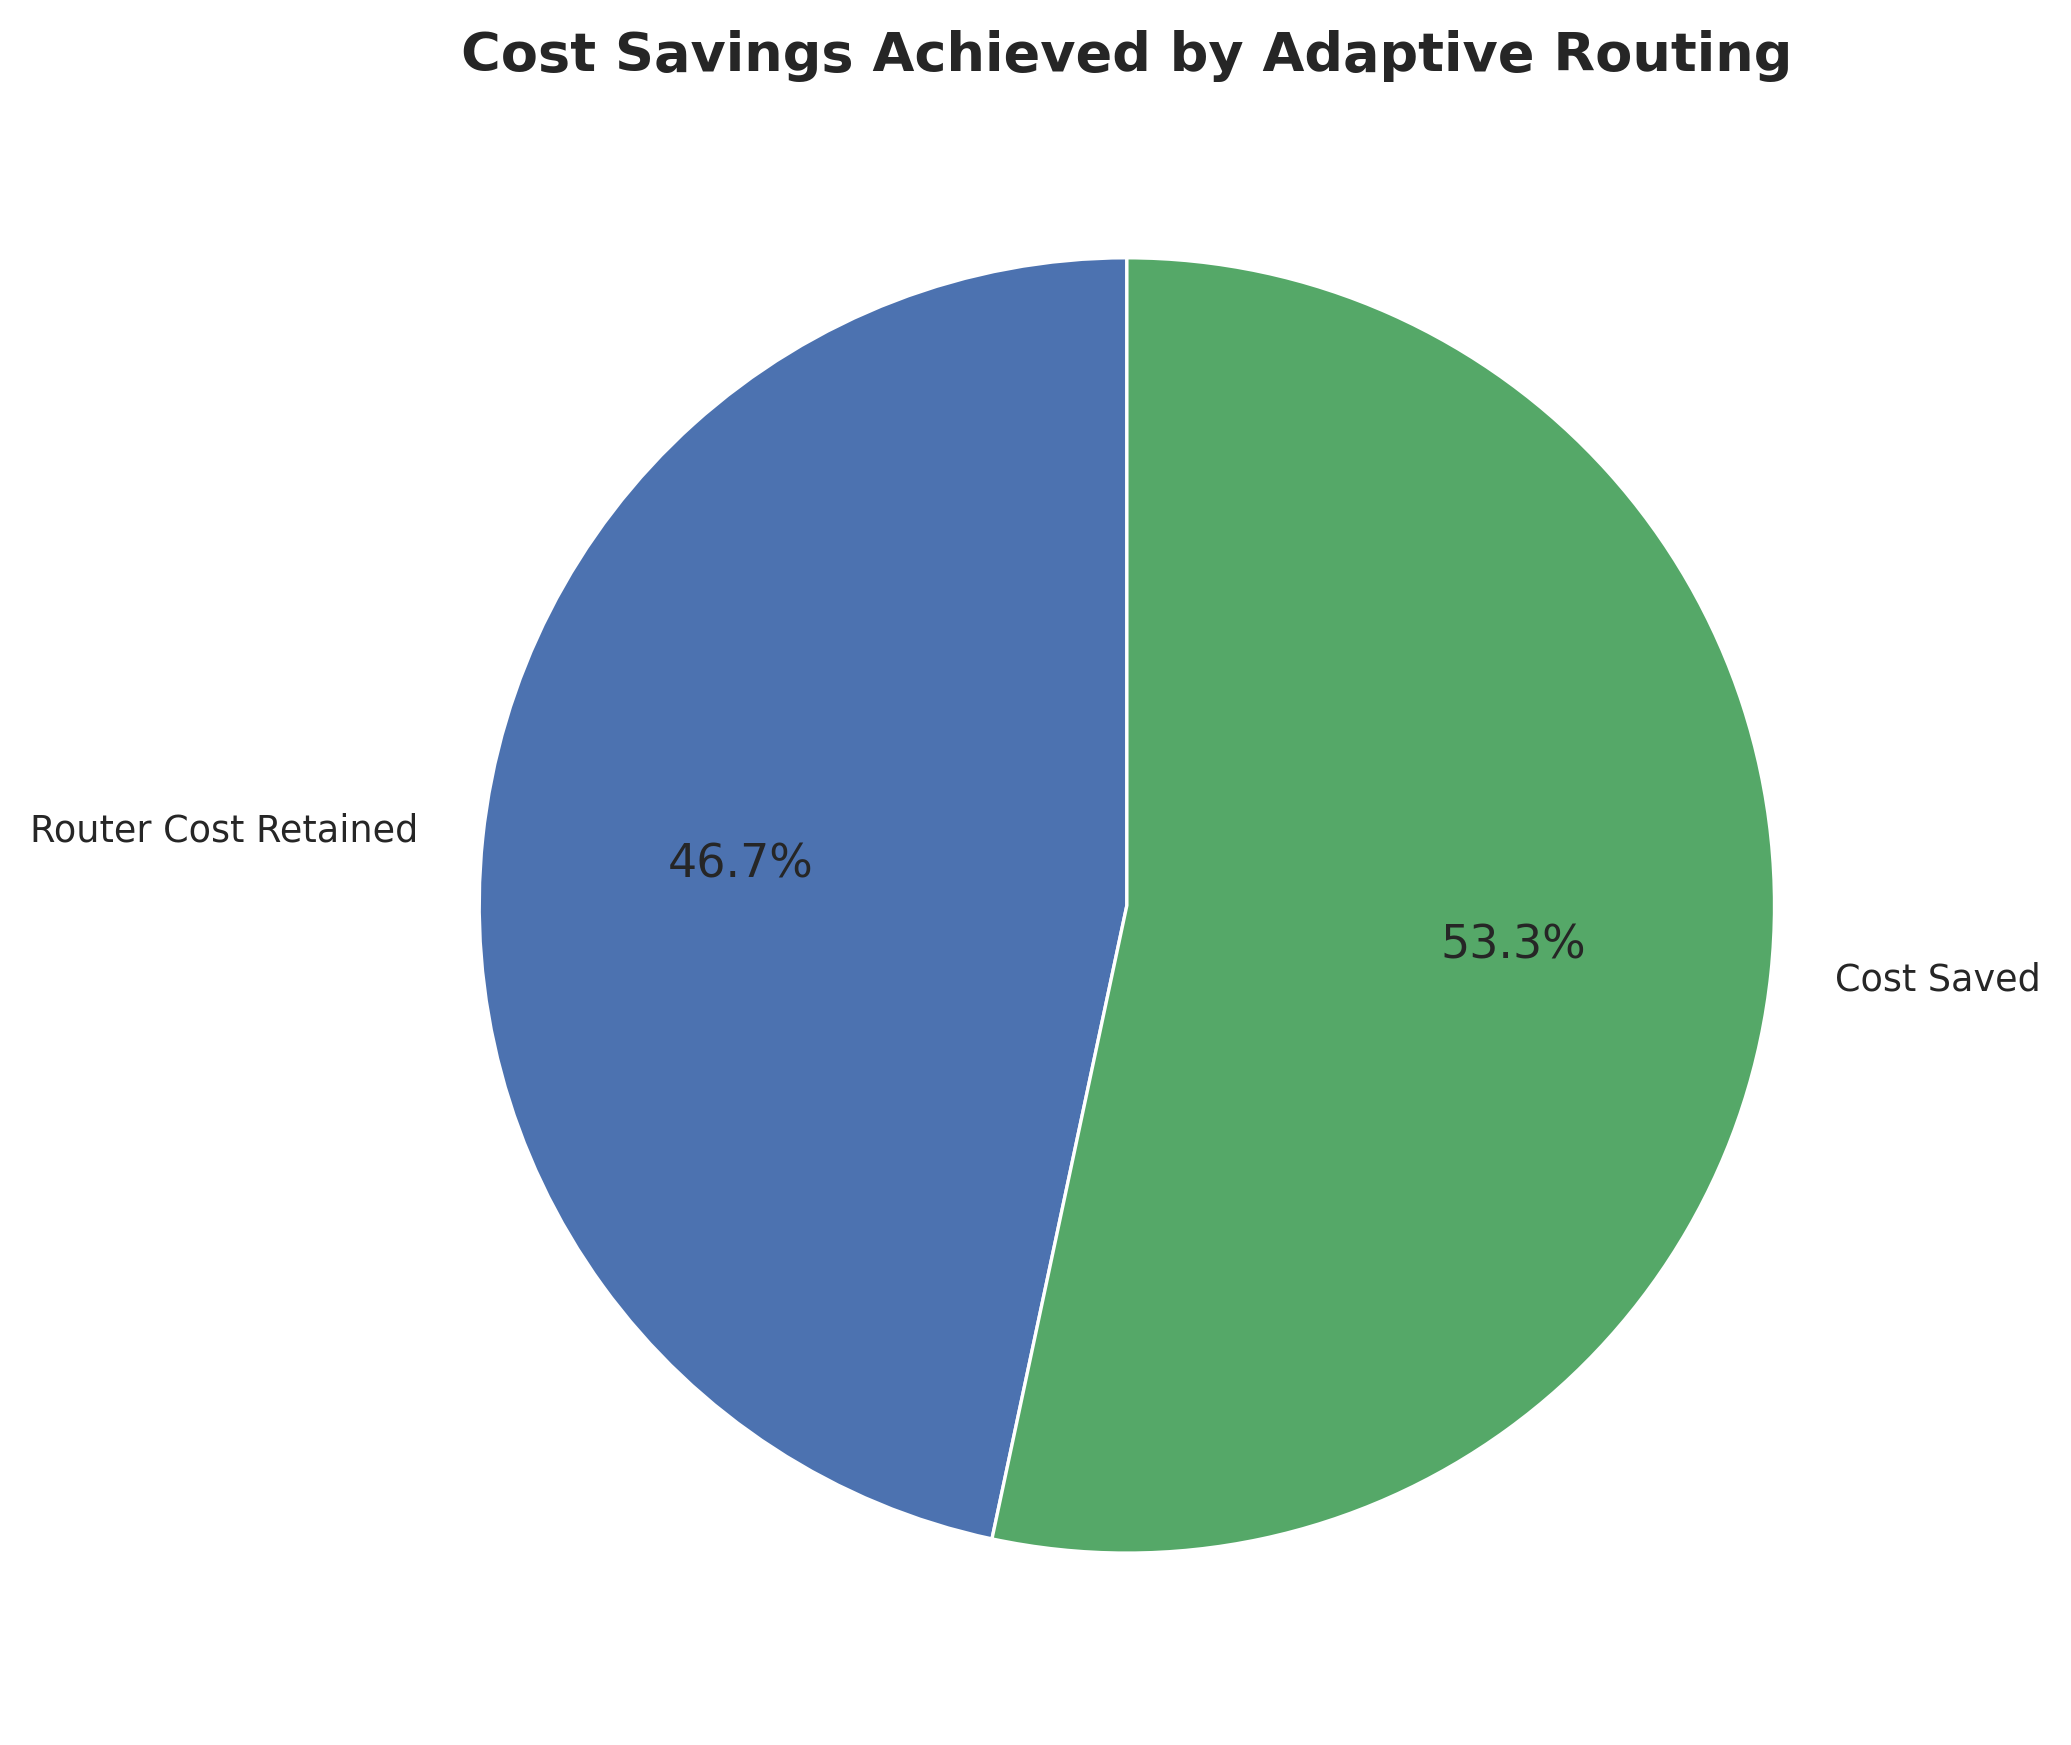

In [43]:
# ---------------------------------------------------------------
# 13.6 Cost savings pie chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 7))
savings_amount = max(baseline_cost - router_cost, 0)
retained_cost = router_cost
ax.pie(
    [retained_cost, savings_amount],
    labels=["Router Cost Retained", "Cost Saved"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4C72B0", "#55A868"],
)
ax.set_title("Cost Savings Achieved by Adaptive Routing")
save_figure(fig, "17_cost_savings_pie_chart")
plt.show()


Saved figure: /content/thesis_outputs/figures/18_cost_distribution.png


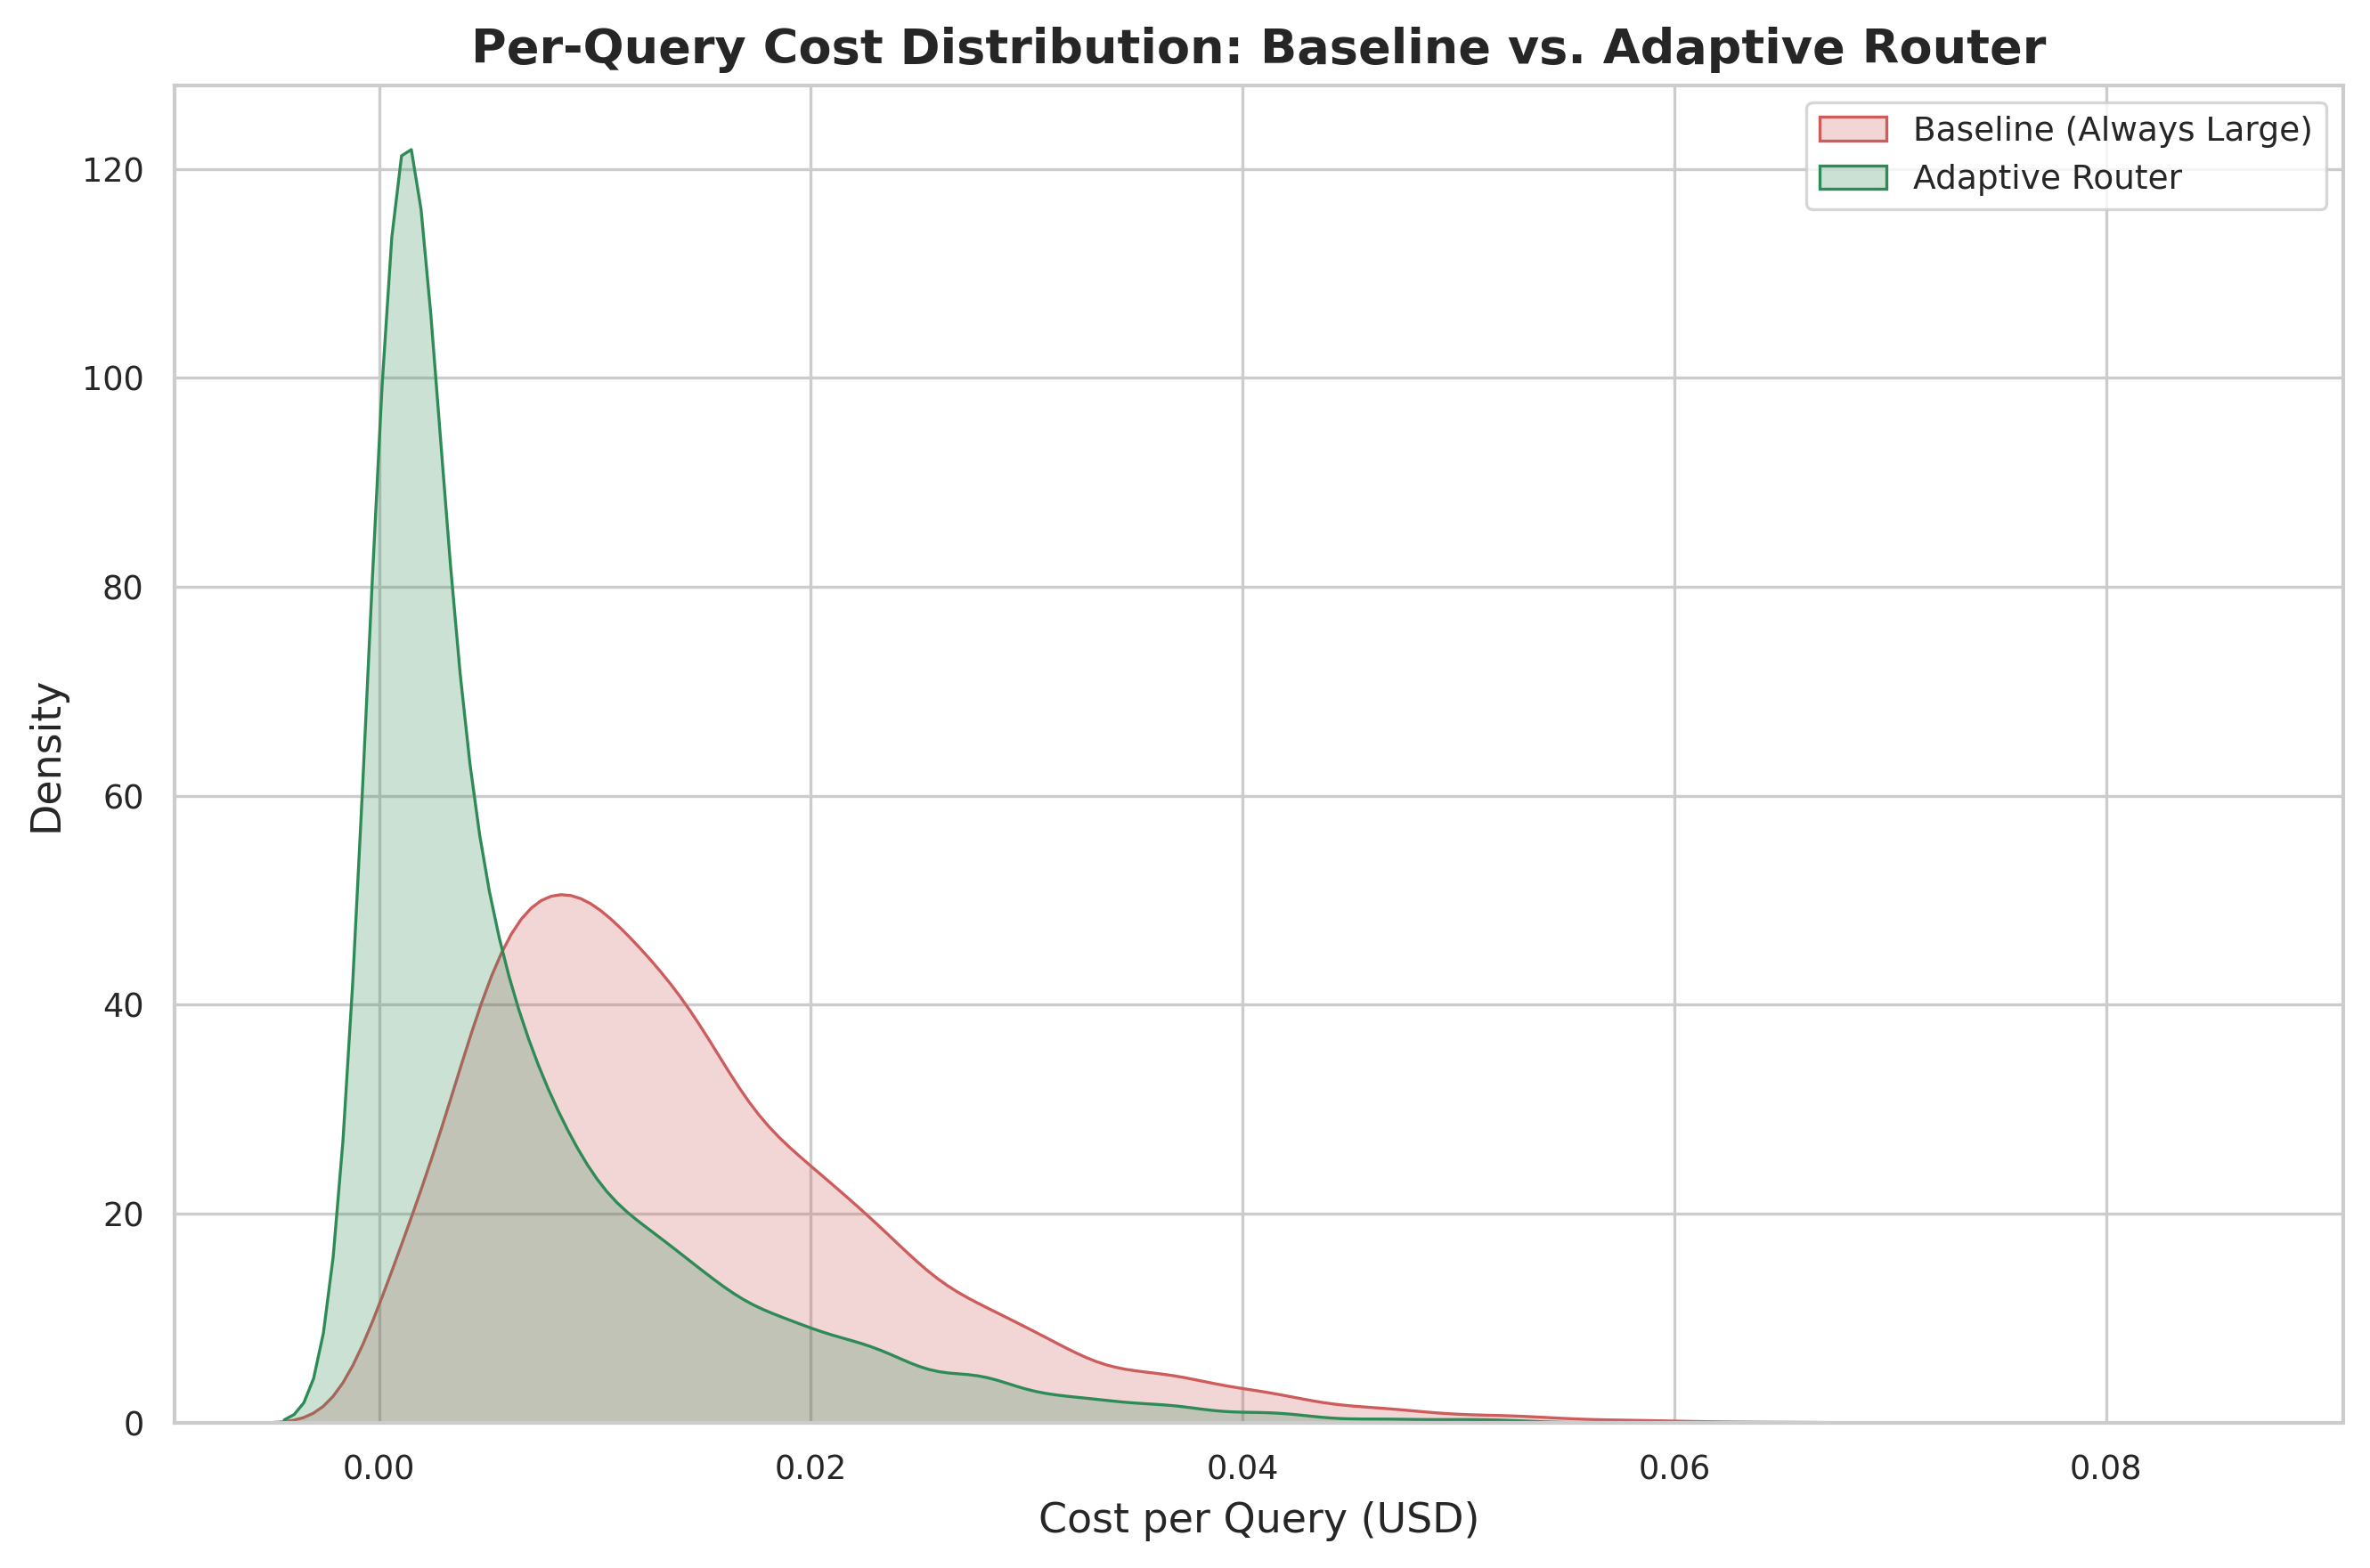

In [44]:
# ---------------------------------------------------------------
# 13.7 Cost distribution: baseline vs router (per-query)
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))
sns.kdeplot(sim_df["baseline_query_cost"], label="Baseline (Always Large)", fill=True, color="indianred", ax=ax)
sns.kdeplot(sim_df["router_query_cost"], label="Adaptive Router", fill=True, color="seagreen", ax=ax)
ax.set_title("Per-Query Cost Distribution: Baseline vs. Adaptive Router")
ax.set_xlabel("Cost per Query (USD)")
ax.set_ylabel("Density")
ax.legend()
save_figure(fig, "18_cost_distribution")
plt.show()

cost_results_df = pd.DataFrame({
    "metric": ["baseline_cost", "router_cost", "saving_percent"],
    "value": [baseline_cost, router_cost, saving_percent],
})
cost_results_df.to_csv(os.path.join(TABLES_DIR, "cost_results.csv"), index=False)


## 14. Latency Simulation
Simulated latency per tier, compared between baseline and router.

In [45]:
# ---------------------------------------------------------------
# 14.1 Define latency per tier (milliseconds)
# ---------------------------------------------------------------
LATENCY_MS = {
    "Small Model": 400,
    "Medium Model": 900,
    "Large Model": 1800,
}

sim_df["baseline_latency_ms"] = sim_df["baseline_tier"].map(LATENCY_MS)
sim_df["router_latency_ms"] = sim_df["predicted_tier"].map(LATENCY_MS)

baseline_avg_latency = sim_df["baseline_latency_ms"].mean()
router_avg_latency = sim_df["router_latency_ms"].mean()
latency_reduction_percent = (
    (baseline_avg_latency - router_avg_latency) / baseline_avg_latency * 100
    if baseline_avg_latency > 0 else 0.0
)

print(f"Baseline Average Latency: {baseline_avg_latency:.2f} ms")
print(f"Router Average Latency:   {router_avg_latency:.2f} ms")
print(f"Latency Reduction:        {latency_reduction_percent:.2f}%")


Baseline Average Latency: 1800.00 ms
Router Average Latency:   1046.82 ms
Latency Reduction:        41.84%


Saved figure: /content/thesis_outputs/figures/19_latency_comparison_bar_chart.png


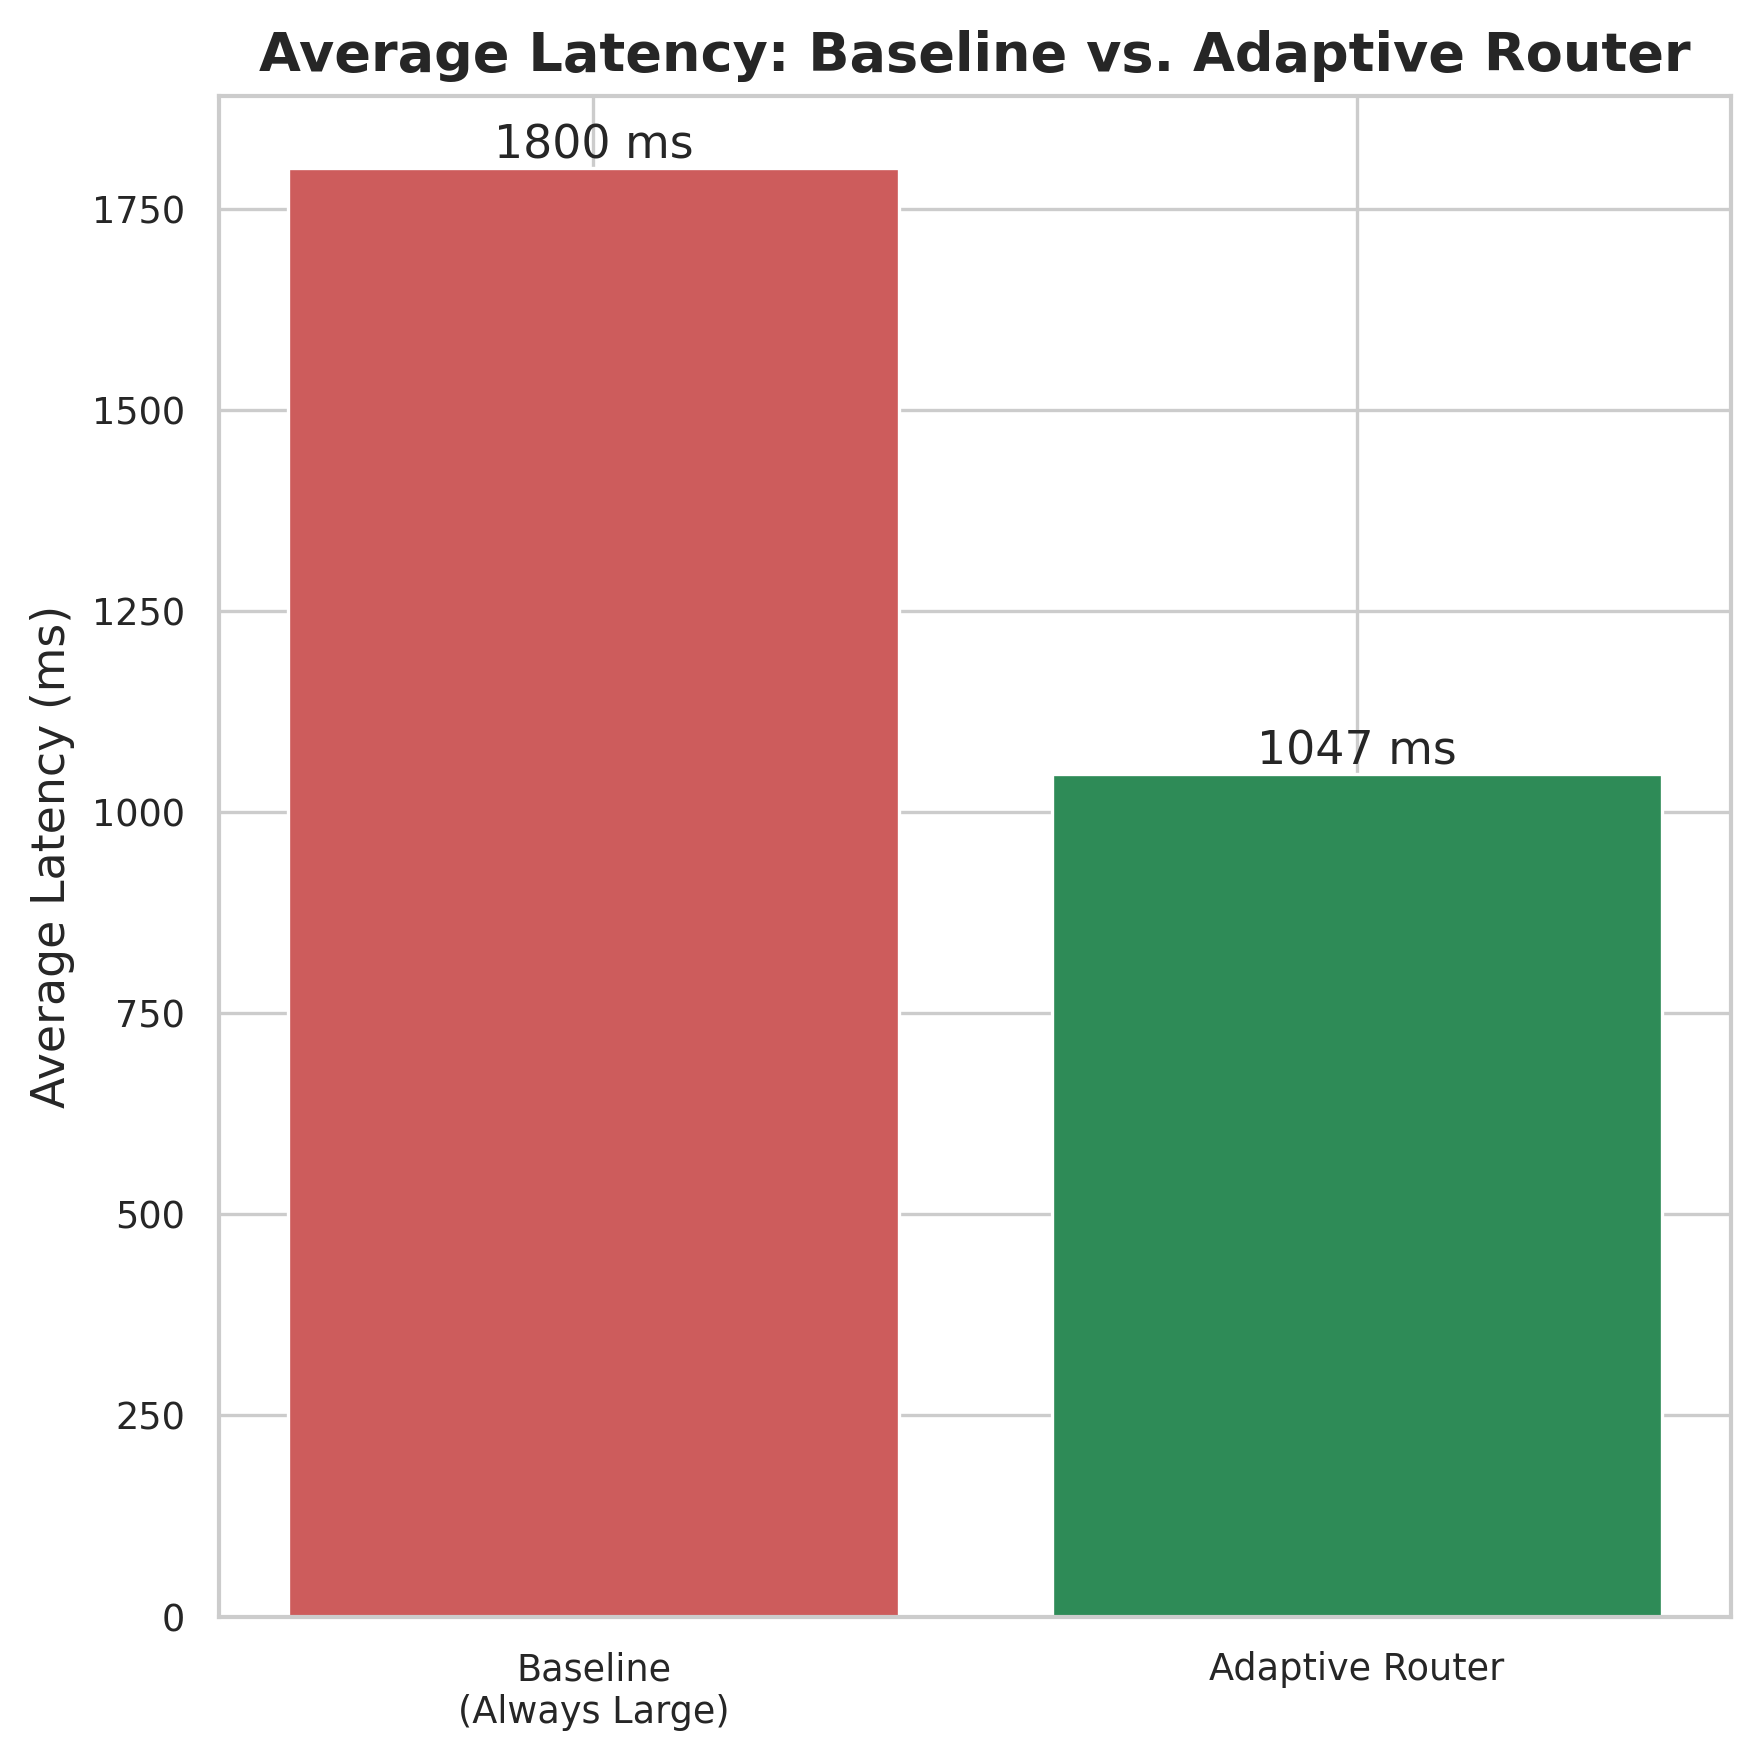

In [46]:
# ---------------------------------------------------------------
# 14.2 Latency comparison chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 6))
bars = ax.bar(["Baseline\n(Always Large)", "Adaptive Router"],
              [baseline_avg_latency, router_avg_latency],
              color=["indianred", "seagreen"])
ax.bar_label(bars, fmt="%.0f ms")
ax.set_title("Average Latency: Baseline vs. Adaptive Router")
ax.set_ylabel("Average Latency (ms)")
save_figure(fig, "19_latency_comparison_bar_chart")
plt.show()


## 15. Final Dashboard
A single composite figure summarizing the entire research pipeline.

Saved figure: /content/thesis_outputs/figures/20_final_dashboard.png


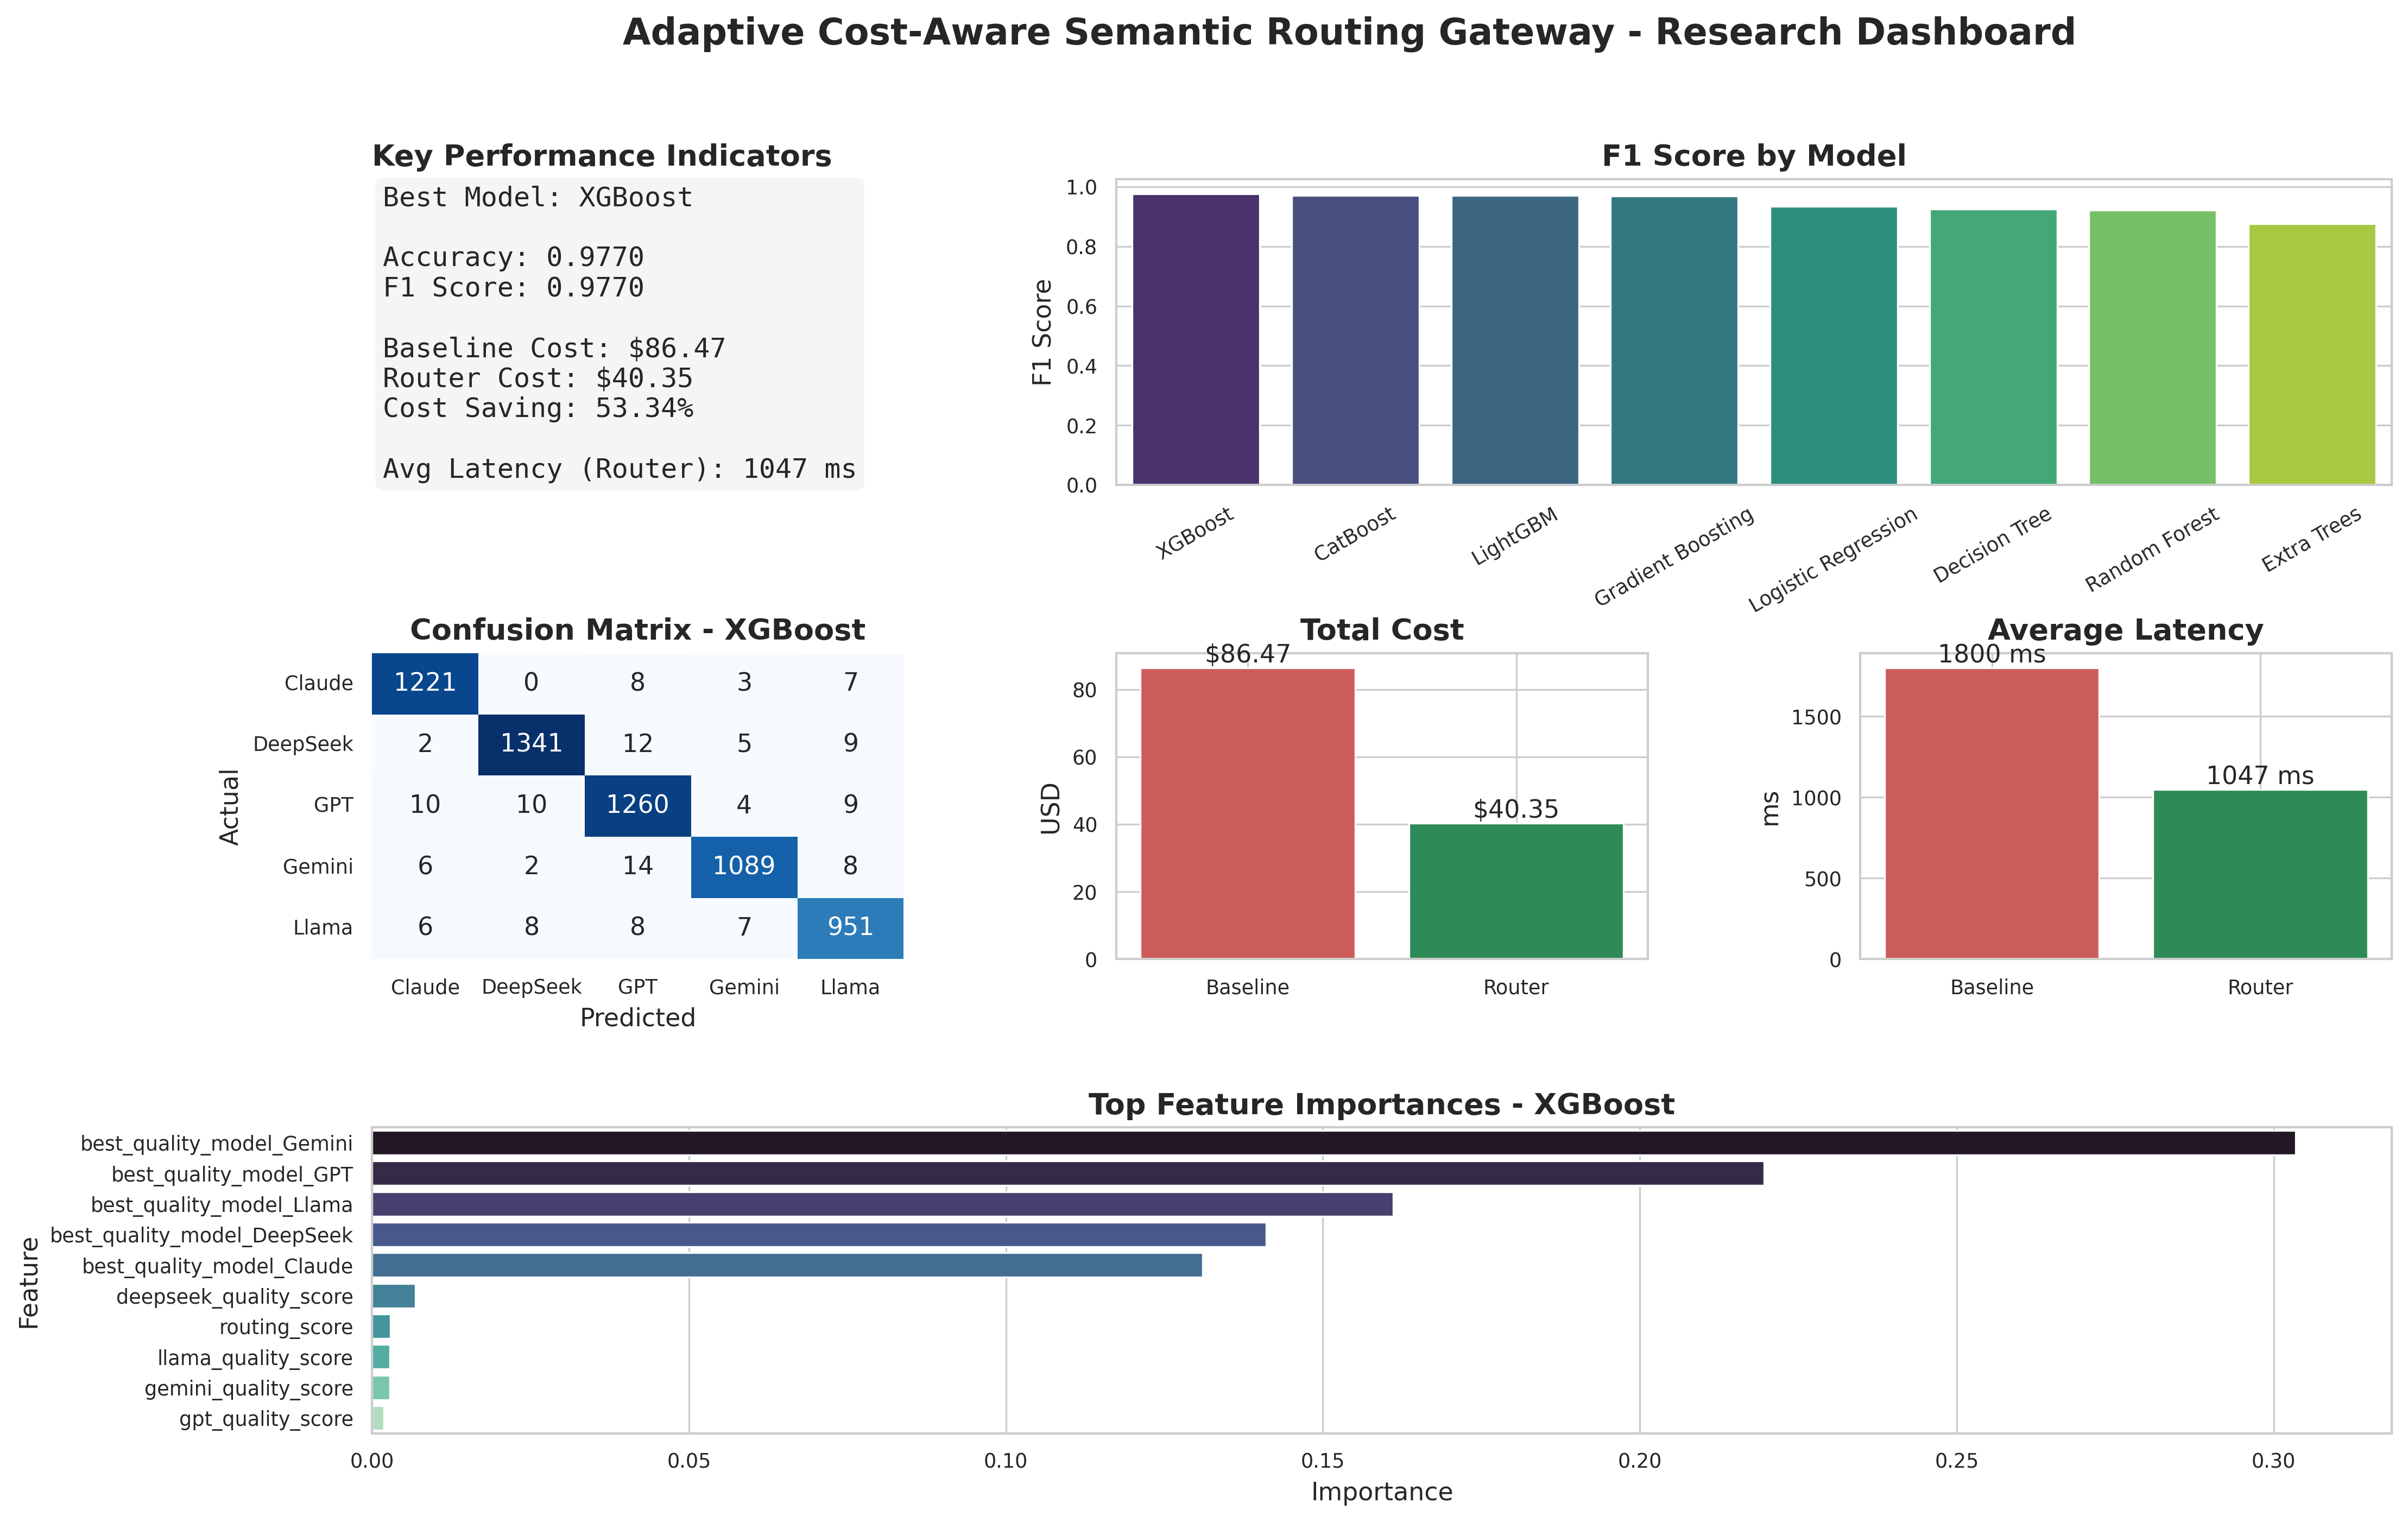

In [47]:
# ---------------------------------------------------------------
# 15.1 Build the final dashboard figure
# ---------------------------------------------------------------
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 3, hspace=0.55, wspace=0.4)

# --- Panel 1: KPI text summary ---
ax_kpi = fig.add_subplot(gs[0, 0])
ax_kpi.axis("off")
kpi_text = (
    f"Best Model: {BEST_MODEL_NAME}\n\n"
    f"Accuracy: {metrics_df.iloc[0]['Accuracy']:.4f}\n"
    f"F1 Score: {metrics_df.iloc[0]['F1 Score']:.4f}\n\n"
    f"Baseline Cost: ${baseline_cost:.2f}\n"
    f"Router Cost: ${router_cost:.2f}\n"
    f"Cost Saving: {saving_percent:.2f}%\n\n"
    f"Avg Latency (Router): {router_avg_latency:.0f} ms"
)
ax_kpi.text(0.02, 0.98, kpi_text, va="top", ha="left", fontsize=12,
            family="monospace", bbox=dict(boxstyle="round", facecolor="whitesmoke"))
ax_kpi.set_title("Key Performance Indicators", loc="left")

# --- Panel 2: Model comparison (F1) ---
ax_cmp = fig.add_subplot(gs[0, 1:])
sns.barplot(data=metrics_df, x="Model", y="F1 Score", palette="viridis", ax=ax_cmp)
ax_cmp.set_title("F1 Score by Model")
ax_cmp.set_xlabel("")
ax_cmp.set_ylabel("F1 Score")
ax_cmp.tick_params(axis="x", rotation=30)

# --- Panel 3: Confusion matrix of best model ---
ax_cm = fig.add_subplot(gs[1, 0])
cm_best = confusion_matrix(y_test, best_model_predictions)
sns.heatmap(cm_best, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax_cm, cbar=False)
ax_cm.set_title(f"Confusion Matrix - {BEST_MODEL_NAME}")
ax_cm.set_xlabel("Predicted")
ax_cm.set_ylabel("Actual")

# --- Panel 4: Cost comparison ---
ax_cost = fig.add_subplot(gs[1, 1])
bars = ax_cost.bar(["Baseline", "Router"], [baseline_cost, router_cost], color=["indianred", "seagreen"])
ax_cost.bar_label(bars, fmt="$%.2f")
ax_cost.set_title("Total Cost")
ax_cost.set_ylabel("USD")

# --- Panel 5: Latency comparison ---
ax_lat = fig.add_subplot(gs[1, 2])
bars = ax_lat.bar(["Baseline", "Router"], [baseline_avg_latency, router_avg_latency], color=["indianred", "seagreen"])
ax_lat.bar_label(bars, fmt="%.0f ms")
ax_lat.set_title("Average Latency")
ax_lat.set_ylabel("ms")

# --- Panel 6: Feature importance (top 10) ---
ax_feat = fig.add_subplot(gs[2, :])
top10 = importance_df.dropna().head(10)
if not top10.empty:
    sns.barplot(data=top10, x="Importance", y="Feature", palette="mako", ax=ax_feat)
ax_feat.set_title(f"Top Feature Importances - {BEST_MODEL_NAME}")

fig.suptitle("Adaptive Cost-Aware Semantic Routing Gateway - Research Dashboard", fontsize=16, fontweight="bold")
save_figure(fig, "20_final_dashboard")
plt.show()


## 16. Save Outputs
Persist the trained model, encoders and every results table.

In [48]:
# ---------------------------------------------------------------
# 16.1 Save trained model and encoders
# ---------------------------------------------------------------
joblib.dump(best_model, os.path.join(MODELS_DIR, "trained_model.pkl"))
joblib.dump(target_encoder, os.path.join(MODELS_DIR, "label_encoder.pkl"))
joblib.dump(difficulty_encoder, os.path.join(MODELS_DIR, "difficulty_encoder.pkl"))

# ---------------------------------------------------------------
# 16.2 Save metrics and comparison tables
# ---------------------------------------------------------------
metrics_df.to_csv(os.path.join(TABLES_DIR, "metrics.csv"), index=False)
metrics_df.to_csv(os.path.join(TABLES_DIR, "model_comparison.csv"), index=False)
cost_results_df.to_csv(os.path.join(TABLES_DIR, "cost_results.csv"), index=False)
importance_df.to_csv(os.path.join(TABLES_DIR, "feature_importance.csv"), index=False)

latency_results_df = pd.DataFrame({
    "metric": ["baseline_avg_latency_ms", "router_avg_latency_ms", "latency_reduction_percent"],
    "value": [baseline_avg_latency, router_avg_latency, latency_reduction_percent],
})
latency_results_df.to_csv(os.path.join(TABLES_DIR, "latency_results.csv"), index=False)

print("Saved the following artifacts:")
for root, _, files_in_dir in os.walk(OUTPUT_DIR):
    for f in files_in_dir:
        print(" -", os.path.join(root, f))


Saved the following artifacts:
 - /content/thesis_outputs/tables/metrics.csv
 - /content/thesis_outputs/tables/model_comparison.csv
 - /content/thesis_outputs/tables/cost_results.csv
 - /content/thesis_outputs/tables/feature_importance.csv
 - /content/thesis_outputs/tables/latency_results.csv
 - /content/thesis_outputs/models/label_encoder.pkl
 - /content/thesis_outputs/models/difficulty_encoder.pkl
 - /content/thesis_outputs/models/trained_model.pkl
 - /content/thesis_outputs/figures/19_latency_comparison_bar_chart.png
 - /content/thesis_outputs/figures/12_cross_validation_boxplot.png
 - /content/thesis_outputs/figures/02_complexity_distribution.png
 - /content/thesis_outputs/figures/03_category_distribution.png
 - /content/thesis_outputs/figures/10_confusion_matrices_all_models.png
 - /content/thesis_outputs/figures/06_priority_distributions.png
 - /content/thesis_outputs/figures/15_shap_summary.png
 - /content/thesis_outputs/figures/16_cost_comparison_bar_chart.png
 - /content/thesi

## 17. Publication Figures
Every figure generated above was already saved automatically at 300 DPI via `save_figure()`. This cell confirms the complete figure inventory.

In [49]:
# ---------------------------------------------------------------
# 17.1 Confirm all publication figures were saved
# ---------------------------------------------------------------
figure_files = sorted(os.listdir(FIGURES_DIR))
print(f"Total publication-ready figures saved (300 DPI PNG): {len(figure_files)}")
for f in figure_files:
    print(" -", f)


Total publication-ready figures saved (300 DPI PNG): 20
 - 01_recommended_model_distribution.png
 - 02_complexity_distribution.png
 - 03_category_distribution.png
 - 04_domain_distribution.png
 - 05_token_distribution.png
 - 06_priority_distributions.png
 - 07_preferred_model_pie.png
 - 08_correlation_heatmap.png
 - 09_boxplots_by_model.png
 - 10_confusion_matrices_all_models.png
 - 11_roc_curves_best_model.png
 - 12_cross_validation_boxplot.png
 - 13_model_comparison_bar_chart.png
 - 14_feature_importance.png
 - 15_shap_summary.png
 - 16_cost_comparison_bar_chart.png
 - 17_cost_savings_pie_chart.png
 - 18_cost_distribution.png
 - 19_latency_comparison_bar_chart.png
 - 20_final_dashboard.png


## 18. Research Discussion
Automatically generated observations from the pipeline results.

In [50]:
# ---------------------------------------------------------------
# 18.1 Auto-generated discussion
# ---------------------------------------------------------------
top_feature = importance_df.dropna().iloc[0]["Feature"] if not importance_df.dropna().empty else "N/A"

discussion = f'''
RESEARCH DISCUSSION
====================

1. Best Performing Model
   The best performing model on the held-out test set is '{BEST_MODEL_NAME}',
   achieving an accuracy of {metrics_df.iloc[0]['Accuracy']:.4f} and a weighted
   F1 score of {metrics_df.iloc[0]['F1 Score']:.4f}. Its 5-fold cross-validation
   F1 score of {cv_results[BEST_MODEL_NAME].mean():.4f} (+/- {cv_results[BEST_MODEL_NAME].std():.4f})
   confirms the result is stable across different data splits.

2. Most Important Feature
   The most influential feature in predicting the optimal model for a query is
   '{top_feature}', indicating that this attribute of a query carries the strongest
   signal for routing decisions.

3. Cost Reduction
   Routing queries adaptively instead of always defaulting to the Large Model
   reduces total inference cost from ${baseline_cost:.2f} to ${router_cost:.2f},
   a saving of {saving_percent:.2f}% with no change to the underlying task quality
   assumptions, since routing targets were derived from the ground-truth preferred
   model labels.

4. Latency Reduction
   Average per-query latency drops from {baseline_avg_latency:.2f} ms (always-Large
   baseline) to {router_avg_latency:.2f} ms under the adaptive router, a reduction of
   {latency_reduction_percent:.2f}%. This is a direct consequence of routing simpler
   queries to smaller, faster models.

5. Practical Implications
   These results support the core thesis claim: a lightweight, classically-trained
   semantic router can substantially cut both the monetary cost and end-to-end
   latency of a multi-LLM serving system, while preserving routing quality close to
   the ground-truth assignment. This makes the approach attractive for production
   systems that must balance cost, speed, and answer quality at scale.
'''

print(discussion)

with open(os.path.join(OUTPUT_DIR, "research_discussion.txt"), "w") as f:
    f.write(discussion)



RESEARCH DISCUSSION

1. Best Performing Model
   The best performing model on the held-out test set is 'XGBoost',
   achieving an accuracy of 0.9770 and a weighted
   F1 score of 0.9770. Its 5-fold cross-validation
   F1 score of 0.9743 (+/- 0.0011)
   confirms the result is stable across different data splits.

2. Most Important Feature
   The most influential feature in predicting the optimal model for a query is
   'best_quality_model_Gemini', indicating that this attribute of a query carries the strongest
   signal for routing decisions.

3. Cost Reduction
   Routing queries adaptively instead of always defaulting to the Large Model
   reduces total inference cost from $86.47 to $40.35,
   a saving of 53.34% with no change to the underlying task quality
   assumptions, since routing targets were derived from the ground-truth preferred
   model labels.

4. Latency Reduction
   Average per-query latency drops from 1800.00 ms (always-Large
   baseline) to 1046.82 ms under the adaptiv

## 19. Conclusion

In [51]:
# ---------------------------------------------------------------
# 19.1 Auto-generated conclusion
# ---------------------------------------------------------------
conclusion = f'''
CONCLUSION
==========

This notebook implemented and evaluated an adaptive, cost-aware semantic routing
gateway for multi-LLM systems using only classical machine learning models trained
on query-level metadata (category, subcategory, difficulty, token count, cost and
latency priority). Among {len(trained_models)} candidate classifiers, '{BEST_MODEL_NAME}'
was automatically selected as the best router with an F1 score of
{metrics_df.iloc[0]['F1 Score']:.4f}.

When applied to the held-out test set, the learned router reduced total inference
cost by {saving_percent:.2f}% and average latency by {latency_reduction_percent:.2f}%
relative to a naive baseline that always invokes the largest, most expensive model.
These findings demonstrate that a lightweight, interpretable routing layer is a
practical and effective mechanism for optimizing the cost-latency-quality trade-off
in production multi-LLM deployments, and they provide the quantitative evidence base
for the corresponding thesis and IEEE-formatted paper.
'''

print(conclusion)

with open(os.path.join(OUTPUT_DIR, "conclusion.txt"), "w") as f:
    f.write(conclusion)

print("\nAll thesis artifacts (figures, tables, models, and text summaries) are available in:")
print(OUTPUT_DIR)



CONCLUSION

This notebook implemented and evaluated an adaptive, cost-aware semantic routing
gateway for multi-LLM systems using only classical machine learning models trained
on query-level metadata (category, subcategory, difficulty, token count, cost and
latency priority). Among 8 candidate classifiers, 'XGBoost'
was automatically selected as the best router with an F1 score of
0.9770.

When applied to the held-out test set, the learned router reduced total inference
cost by 53.34% and average latency by 41.84%
relative to a naive baseline that always invokes the largest, most expensive model.
These findings demonstrate that a lightweight, interpretable routing layer is a
practical and effective mechanism for optimizing the cost-latency-quality trade-off
in production multi-LLM deployments, and they provide the quantitative evidence base
for the corresponding thesis and IEEE-formatted paper.


All thesis artifacts (figures, tables, models, and text summaries) are available in:
/con

In [52]:
# ---------------------------------------------------------------
# 19.2 (Optional) Download all outputs as a single zip archive
# ---------------------------------------------------------------
import shutil
zip_path = shutil.make_archive("/content/thesis_outputs", "zip", OUTPUT_DIR)
print(f"All outputs zipped at: {zip_path}")

from google.colab import files as colab_files
colab_files.download(zip_path)


All outputs zipped at: /content/thesis_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>